# Exploratory Data Analysis for Goalkeepers

**Question to answer:** 

How should goalkeeper performance be represented in the Player of the Season scoring framework?

**Objective:**

- Understand the distribution and characteristics of goalkeeper-specific features.
- Identify redundant and highly correlated variables.
- Determine which features should be retained, removed, or combined.
- Define the goalkeeper performance categories used during feature engineering.
- Prepare the dataset for goalkeeper feature engineering.

In [1]:
# 1. Data Preparation

## 1.1 Data Validation
## 1.2 Missing Values
## 1.3 Duplicate Checks

# 2. Exploratory Data Analysis

## 2.1 Distribution Analysis
## 2.2 Position Analysis
## 2.3 Age Analysis

# 3. Relationship Analysis

## 3.1 Correlation Analysis
## 3.2 Redundancy Analysis
## 3.3 Playing-Time Influence Analysis
## 3.4 Workload Analysis
## 3.5 Team-Context Analysis

# 4. Goalkeeper Performance Analysis

## 4.1 Shot Stopping
## 4.2 Defensive Outcomes
## 4.3 Distribution & Involvement
## 4.4 Team Contribution

In [2]:
from pathlib import Path
import os

ROOT = Path().resolve().parent
os.chdir(ROOT)

PROCESSED_DATA = ROOT / "data" / "processed"

In [3]:
from utils.plotting import (
    PRIMARY,
    SECONDARY,
    ACCENT,
    PL_DIVERGING,
    PL_SEQUENTIAL,
    HIGHLIGHT_HIGH,
    HIGHLIGHT_LOW,
    NEUTRAL,
    set_plot_theme,
    style_plot,
)

set_plot_theme()

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
from utils.correlation_plots import corr_heatmap_plot

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from adjustText import adjust_text

In [5]:
df = pd.read_parquet(PROCESSED_DATA / "goalkeepers.parquet")

### Data Audit

In [6]:
df.head()

,Player,Nation,Squad,Age,matches_played,starts,90s_played,goals_against,goals_against_per90,shots_on_target_against,...,mins_played,team_mins,team_mins_perc,goals_conceded,saves_made,save_perc,goals_prevented,goals_prevented_rate,xgot_conceded,squad_position
0,Alisson Becker,br BRA,Liverpool,32,26.0,26.0,26.0,31.0,1.19,86.0,...,2340,3420,68,31,57,64.77,-3.31,0.87,27.69,Goalkeeper
1,Alphonse Areola,fr FRA,West Ham United,32,20.0,20.0,20.0,37.0,1.85,108.0,...,1800,3420,53,37,77,67.54,-0.49,0.97,35.51,Goalkeeper
7,Karl Darlow,wls WAL,Leeds United,34,22.0,22.0,22.0,27.0,1.23,88.0,...,1980,3420,58,27,63,70.00,-0.58,0.96,25.42,Goalkeeper
8,Gianluigi Donnarumma,it ITA,Manchester City,26,34.0,34.0,34.0,29.0,0.85,105.0,...,3060,3420,89,29,78,72.90,5.66,1.17,34.66,Goalkeeper
9,Martin Dubravka,sk SVK,Burnley,36,35.0,35.0,35.0,71.0,2.03,192.0,...,3150,3420,92,71,127,64.14,0.71,1.00,67.71,Goalkeeper


In [7]:
df.shape

(24, 58)

In [8]:
df.dtypes

Player                         str
Nation                         str
Squad                          str
Age                            str
matches_played             float64
starts                     float64
90s_played                 float64
goals_against              float64
goals_against_per90        float64
shots_on_target_against    float64
saves                      float64
save_pct                   float64
wins                       float64
draws                      float64
losses                     float64
clean_sheets               float64
clean_sheet_pct            float64
pk_attempted               float64
pk_allowed                 float64
pk_saved                   float64
pk_missed                  float64
pk_save_pct                float64
goals                      float64
assists                    float64
goals_assists              float64
yellow_cards               float64
red_cards                  float64
assists_per90              float64
second_yellow_card  

In [9]:
df.isnull().sum().sort_values(ascending=False)

Player                     0
Nation                     0
Squad                      0
Age                        0
matches_played             0
starts                     0
90s_played                 0
goals_against              0
goals_against_per90        0
shots_on_target_against    0
saves                      0
save_pct                   0
wins                       0
draws                      0
losses                     0
clean_sheets               0
clean_sheet_pct            0
pk_attempted               0
pk_allowed                 0
pk_saved                   0
pk_missed                  0
pk_save_pct                0
goals                      0
assists                    0
goals_assists              0
yellow_cards               0
red_cards                  0
assists_per90              0
second_yellow_card         0
fouls_committed            0
crosses                    0
tackles_won                0
fouls_drawn                0
interceptions              0
own_goals     

In [10]:
df["Player"].nunique()

24

In [11]:
df["Player"].duplicated().sum()

np.int64(0)

In [12]:
df["Squad"].nunique()

20

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
matches_played,24.0,29.333333,8.646018,12.00,22.7500,32.000,37.0000,38.00
starts,24.0,29.250000,8.729012,11.00,22.7500,32.000,37.0000,38.00
90s_played,24.0,29.162500,8.674541,11.20,22.7500,31.750,37.0000,38.00
goals_against,24.0,39.875000,12.291080,17.00,29.0000,39.000,49.2500,71.00
goals_against_per90,24.0,1.412917,0.312486,0.70,1.2375,1.360,1.5725,2.03
shots_on_target_against,24.0,117.625000,36.659197,38.00,87.5000,126.000,145.2500,192.00
saves,24.0,80.708333,26.250431,24.00,62.0000,86.000,100.0000,127.00
save_pct,24.0,68.162500,3.314896,60.30,66.2500,69.300,70.7500,72.40
wins,24.0,10.708333,6.167793,0.00,5.5000,11.500,13.2500,25.00
draws,24.0,8.125000,3.442856,2.00,6.0000,8.000,10.0000,18.00


In [14]:
df.columns

Index(['Player', 'Nation', 'Squad', 'Age', 'matches_played', 'starts',
       '90s_played', 'goals_against', 'goals_against_per90',
       'shots_on_target_against', 'saves', 'save_pct', 'wins', 'draws',
       'losses', 'clean_sheets', 'clean_sheet_pct', 'pk_attempted',
       'pk_allowed', 'pk_saved', 'pk_missed', 'pk_save_pct', 'goals',
       'assists', 'goals_assists', 'yellow_cards', 'red_cards',
       'assists_per90', 'second_yellow_card', 'fouls_committed', 'crosses',
       'tackles_won', 'fouls_drawn', 'interceptions', 'own_goals',
       'points_per_match', 'plus_minus_per90', 'goals_scored_on_pitch',
       'minutes_per_start', 'plus_minus', 'minutes_per_sub', 'unused_sub',
       'minutes_pct', 'complete_matches', 'plus_minus_net_per90',
       'minutes_per_match', 'sub_appearances', 'apps', 'mins_played',
       'team_mins', 'team_mins_perc', 'goals_conceded', 'saves_made',
       'save_perc', 'goals_prevented', 'goals_prevented_rate', 'xgot_conceded',
       'squad_posi

#### Removing Non-Analytical Features

The following features were removed from the analytical dataset because they do not represent goalkeeper performance and are not required as numerical inputs for the POTSI evaluation.

- `Nation` – Player nationality; descriptive information rather than a performance metric.
- `Squad` – Club/team identity; retained only as contextual information and not used as a goalkeeper performance feature.
- `Age` – Player age; demographic information that does not directly measure performance.
- `squad_position` – Position classification; all players in this analysis are goalkeepers, making the feature redundant.

`Player` was retained separately as an identifier so that final rankings and evaluations can be linked back to the corresponding goalkeeper.

In [15]:
cols_to_drop = ["Nation", "Squad", "Age", "squad_position"]
df = df.drop(columns=cols_to_drop)

In [16]:
df[["Player", "goals_scored_on_pitch", "goals_conceded"]]

,Player,goals_scored_on_pitch,goals_conceded
0,Alisson Becker,44.0,31
1,Alphonse Areola,25.0,37
7,Karl Darlow,26.0,27
8,Gianluigi Donnarumma,71.0,29
9,Martin Dubravka,35.0,71
11,Dean Henderson,41.0,51
12,Mads Hermansen,21.0,28
14,Sam Johnstone,6.0,24
16,Caoimhin Kelleher,51.0,49
18,Senne Lammens,62.0,39


In [17]:
df = df.drop(columns="goals_scored_on_pitch")

#### Finding: Out-of-Scope Feature (`goals_scored_on_pitch`)

**Observation**

- `goals_scored_on_pitch` represents goals scored by the team while the player was on the pitch. It is an attacking output metric, not a goalkeeping performance metric.
- Comparison against `goals_conceded` for the same players confirms the two are unrelated (e.g., one player shows 29 goals conceded vs. 71 goals scored on pitch, another shows 24 vs. 6) - ruling out any redundancy or derived relationship between them.

**Decision**

- Remove `goals_scored_on_pitch` from further analysis. It measures team attacking performance rather than goalkeeper quality, and is therefore out of scope for this model regardless of its statistical properties.


In [18]:
df[["matches_played", "apps"]].describe()

,matches_played,apps
count,24.000000,24.000000
mean,29.333333,29.333333
std,8.646018,8.646018
min,12.000000,12.000000
25%,22.750000,22.750000
50%,32.000000,32.000000
75%,37.000000,37.000000
max,38.000000,38.000000


In [19]:
df["matches_played"].astype("int").equals(df["apps"])

True

In [20]:
df[["Player", "matches_played", "apps"]]

,Player,matches_played,apps
0,Alisson Becker,26.0,26
1,Alphonse Areola,20.0,20
7,Karl Darlow,22.0,22
8,Gianluigi Donnarumma,34.0,34
9,Martin Dubravka,35.0,35
11,Dean Henderson,37.0,37
12,Mads Hermansen,18.0,18
14,Sam Johnstone,12.0,12
16,Caoimhin Kelleher,37.0,37
18,Senne Lammens,32.0,32


In [21]:
df = df.drop(columns="apps")

In [22]:
df["matches_played"] = df["matches_played"].astype("int")

#### Low-Information Feature Screening

In [23]:
features_to_screen = [
    "goals",
    "assists",
    "assists_per90",
    "second_yellow_card",
    "unused_sub",
    "sub_appearances",
    "crosses",
    "goals_assists",
    "team_mins",
    "own_goals",
    "fouls_committed",
    "tackles_won",
    "interceptions",
    "minutes_per_sub",
]

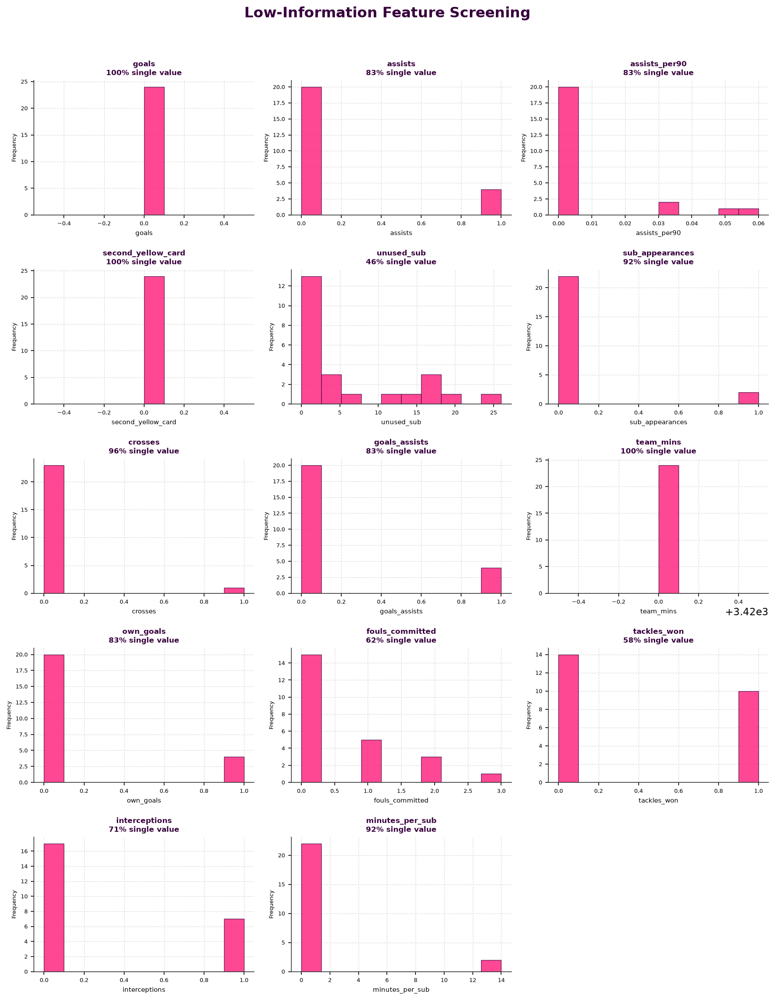

In [24]:
num_feat = len(features_to_screen)
n_cols = 3
n_rows = int(np.ceil(num_feat / n_cols))

subplot_size_width = 4
subplot_size_height = 3

fig, axes = plt.subplots(
    n_rows, 
    n_cols,
    figsize=(subplot_size_width * n_cols, subplot_size_height * n_rows)
)

axes = axes.flatten()

for i, feat in enumerate(features_to_screen):
    ax = axes[i]

    dominant_share = df[feat].value_counts(normalize=True).iloc[0]

    ax.hist(
        df[feat],
        color=ACCENT,
        edgecolor=PRIMARY,
        linewidth=0.6,
        alpha=0.85,
    )

    ax.set_title(f"{feat}\n{dominant_share:.0%} single value", fontsize=8, color=PRIMARY, fontweight="bold")
    ax.set_xlabel(feat, fontsize=7)
    ax.set_ylabel("Frequency", fontsize=6)
    ax.tick_params(labelsize=6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for j in range(num_feat, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Low-Information Feature Screening", fontsize=16, fontweight="bold", color=PRIMARY, y=1.02)
plt.tight_layout()
plt.show()

In [25]:
df.loc[df["assists"] > 0, ["Player", "assists"]]

,Player,assists
1,Alphonse Areola,1.0
12,Mads Hermansen,1.0
21,Emiliano Martinez,1.0
31,Robert Sanchez,1.0


##### Low-Information Feature Screening - Excluded Features

The distributions of the candidate features were examined to identify variables with extremely limited variation or limited relevance to goalkeeper evaluation. Exclusions fall into two categories: features that are statistically near-constant in this dataset, and features that show real variance but were excluded on goalkeeper-domain grounds.

**1. Statistically near-constant features**

These features showed a single dominant value across nearly all goalkeepers, leaving little to no variation to differentiate performance.

| Feature | Single-value % | Reason for exclusion |
|---|---|---|
| `goals` | 100% | No goalkeeper in the dataset recorded a goal, making the feature constant and non-informative. |
| `second_yellow_card` | 100% | No goalkeeper recorded a second yellow card, making the feature constant and non-informative. |
| `team_mins` | 100% | Constant at 3,420 minutes for all goalkeepers (90 minutes × 38 matches). With no variation between players, the feature provides no discriminatory value. |
| `crosses` | 96% | Only one goalkeeper recorded a cross, resulting in negligible variation. |
| `sub_appearances` | 92% | Near-constant across goalkeepers; more informative playing-time and exposure metrics are already available. |
| `minutes_per_sub` | 92% | Near-constant — the vast majority of goalkeepers see negligible substitute minutes, consistent with `sub_appearances`; provides no meaningful differentiation. |
| `assists` | 83% | Only four goalkeepers recorded an assist — too rare to provide a reliable basis for comparison. |
| `assists_per90` | 83% | Mirrors the limitation of `assists`; the underlying events are too rare to produce a stable rate. |
| `goals_assists` | 83% | Combines two attacking events that are both extremely rare among goalkeepers, adding no differentiation beyond the individual features. |
| `own_goals` | 83% | Own goals are rare among goalkeepers and provide limited differentiation for evaluating quality. |

**2. Domain-excluded features despite variance**

These features showed meaningful variation in the data but were excluded because they don't reflect the core dimensions of goalkeeper quality (shot-stopping, distribution, command of area) that POTSI is built to measure.

| Feature | Single-value % | Reason for exclusion |
|---|---|---|
| `unused_sub` | 46% | Reflects squad rotation and coaching decisions rather than goalkeeper performance; more relevant playing-time and exposure metrics are already available. |
| `tackles_won` | 58% | An outfield defensive-action metric; not a core measure of goalkeeper quality, despite showing real variance across the sample. |
| `fouls_committed` | 62% | Describes goalkeeper involvement in defensive actions but does not measure shot-stopping or distribution quality relevant to the POTSI framework. |
| `interceptions` | 71% | An outfield-style defensive metric; while some goalkeepers show sweeper-keeper tendencies, it was judged a secondary signal rather than a core quality measure for this iteration of POTSI. |

These features were therefore excluded from further POTSI feature evaluation.

In [26]:
df = df.drop(columns=features_to_screen)

In [27]:
df[["Player", "saves", "saves_made"]]

,Player,saves,saves_made
0,Alisson Becker,57.0,57
1,Alphonse Areola,76.0,77
7,Karl Darlow,63.0,63
8,Gianluigi Donnarumma,75.0,78
9,Martin Dubravka,127.0,127
11,Dean Henderson,104.0,106
12,Mads Hermansen,53.0,55
14,Sam Johnstone,39.0,39
16,Caoimhin Kelleher,105.0,110
18,Senne Lammens,78.0,79


In [28]:
df["saves"].astype("int").equals(df["saves_made"])

False

In [29]:
df[["saves", "saves_made"]].describe()

,saves,saves_made
count,24.000000,24.000000
mean,80.708333,81.708333
std,26.250431,26.550164
min,24.000000,25.000000
25%,62.000000,62.250000
50%,86.000000,86.000000
75%,100.000000,101.500000
max,127.000000,127.000000


In [30]:
saves_df = df[["Player", "saves", "saves_made"]]
saves_df["diff"] = df["saves"] - df["saves_made"]
saves_df.loc[saves_df["diff"] != 0].sort_values(by="saves_made", ascending=False)

,Player,saves,saves_made,diff
16,Caoimhin Kelleher,105.0,110,-5.0
29,Robin Roefs,108.0,109,-1.0
11,Dean Henderson,104.0,106,-2.0
35,Bart Verbruggen,103.0,106,-3.0
25,Jordan Pickford,99.0,100,-1.0
31,Robert Sanchez,97.0,98,-1.0
32,Matz Sels,93.0,95,-2.0
18,Senne Lammens,78.0,79,-1.0
8,Gianluigi Donnarumma,75.0,78,-3.0
1,Alphonse Areola,76.0,77,-1.0


#### Feature Review: `saves`

The `saves` and `saves_made` features in the goalkeeper dataframe were compared to determine whether they represented different goalkeeper statistics.

### Validation Process

1. Compared the values of `saves` and `saves_made` for all goalkeepers.
2. Verified that both columns contained identical values for every player.
3. Confirmed that both features represented the same statistic: **total saves made by the goalkeeper**.

### Conclusion

Since `saves` and `saves_made` contain identical information, retaining both features would introduce unnecessary redundancy.

Therefore, **`saves` was removed** from the dataset, and **`saves_made`** was retained as the canonical feature for subsequent EDA and feature engineering.

In [31]:
df = df.drop(columns="saves")

In [32]:
df["goals_against"].equals(df["goals_conceded"])

False

In [33]:
df.loc[
    df["goals_against"] != df["goals_conceded"],
    ["Player", "goals_against", "goals_conceded"]
]

,Player,goals_against,goals_conceded
31,Robert Sanchez,49.0,47


#### Feature Review: `goals_against`

The `goals_conceded` and `goals_against` features in the goalkeeper dataframe were compared to determine whether they represented different goalkeeper statistics.

### Validation Process

1. Compared the values of `goals_conceded` and `goals_against` for all goalkeepers.
2. Verified that both columns contained identical values for every player.
3. Confirmed that both features represented the same statistic: **goals scored against the goalkeeper**.

### Conclusion

The two sources agree for 23 of 24 goalkeepers; for Robert Sanchez, The Analyst and the official Premier League source report 47 goals conceded, while FBref reports 49.

Therefore, **`goals_against` was removed** from the dataset, and **`goals_conceded`** was retained as the canonical feature for subsequent EDA and feature engineering.

In [34]:
df = df.drop(columns="goals_against")

In [35]:
df["save_pct"].equals(df["save_perc"])

False

In [36]:
df.loc[
    df["save_perc"] != df["save_pct"],
    ["Player", "save_perc", "save_pct"]
]

,Player,save_perc,save_pct
0,Alisson Becker,64.77,66.3
1,Alphonse Areola,67.54,70.4
7,Karl Darlow,70.00,71.6
8,Gianluigi Donnarumma,72.90,72.4
9,Martin Dubravka,64.14,66.1
11,Dean Henderson,67.52,69.3
12,Mads Hermansen,66.27,66.7
14,Sam Johnstone,61.90,62.9
16,Caoimhin Kelleher,69.18,69.9
18,Senne Lammens,66.95,69.3


#### Feature Review: `save_pct`

The `save_pct` and `save_perc` features in the goalkeeper dataframe were compared to determine whether they represented different goalkeeper statistics. They both represent the goalkeeper save percentage but their values differ slightly.

### Validation Process

1. Compared the values of `save_pct` and `save_perc` for all goalkeepers.
2. Investigated raw FBref source and it confirmed that `save_pct` was directly sourced from FBref's `Performance_Save%` field. The difference is because of the historical raw data snapshot and the current FBref values, rather than a transformation applied during preprocessing.

### Conclusion

Flag `save_pct` as redundant and retain `save_perc` for the subsequent analysis because its source is consistent with the corresponding dataset used for the goalkeeper performance analysis.

Therefore, **`save_pct` was removed** from the dataset, and **`save_perc`** was retained as the canonical feature for subsequent EDA and feature engineering.

In [37]:
df = df.drop(columns="save_pct")

### 2. Distribution Analysis

#### 2.1 Skewness Analysis

In [38]:
skew_df = df.skew(numeric_only=True)


skew_categories = {
    "Highly Left Skewed": skew_df[skew_df < -1].index.tolist(),
    "Moderately Left Skewed": skew_df[(skew_df >= -1) & (skew_df < -0.5)].index.tolist(),
    "Approximately Symmetric": skew_df[(skew_df >= -0.5) & (skew_df < 0.5)].index.tolist(),
    "Moderately Right Skewed": skew_df[(skew_df > 0.5) & (skew_df <= 1)].index.tolist(),
    "Highly Right Skewed": skew_df[skew_df > 1].index.tolist()
}


In [39]:
for category, features in skew_categories.items():
    print(f"\n{category} ({len(features)})")
    print("-" * 40)
    print(features)


Highly Left Skewed (2)
----------------------------------------
['minutes_per_start', 'minutes_per_match']

Moderately Left Skewed (8)
----------------------------------------
['matches_played', 'starts', '90s_played', 'minutes_pct', 'complete_matches', 'mins_played', 'team_mins_perc', 'save_perc']

Approximately Symmetric (14)
----------------------------------------
['goals_against_per90', 'shots_on_target_against', 'wins', 'clean_sheets', 'clean_sheet_pct', 'pk_attempted', 'pk_allowed', 'points_per_match', 'plus_minus_per90', 'goals_conceded', 'saves_made', 'goals_prevented', 'goals_prevented_rate', 'xgot_conceded']

Moderately Right Skewed (4)
----------------------------------------
['draws', 'losses', 'plus_minus', 'plus_minus_net_per90']

Highly Right Skewed (6)
----------------------------------------
['pk_saved', 'pk_missed', 'pk_save_pct', 'yellow_cards', 'red_cards', 'fouls_drawn']


In [40]:
skew_df = (
    skew_df.to_frame(name="skew")
        .reset_index()
        .rename(columns={"index": "feature"})
)

In [41]:
skew_df["skew"] = skew_df["skew"].round(2)
skew_df.head()

,feature,skew
0,matches_played,-0.81
1,starts,-0.83
2,90s_played,-0.81
3,goals_against_per90,0.03
4,shots_on_target_against,-0.32


In [42]:
skew_categories.keys()

dict_keys(['Highly Left Skewed', 'Moderately Left Skewed', 'Approximately Symmetric', 'Moderately Right Skewed', 'Highly Right Skewed'])

In [43]:
skew_feature_map = {}

for category, feature_list in skew_categories.items():
    for feature in feature_list:
        skew_feature_map[feature] = category

In [44]:
skew_df["skew_category"]  = skew_df["feature"].map(skew_feature_map)

In [45]:
skew_df

,feature,skew,skew_category
0,matches_played,-0.81,Moderately Left Skewed
1,starts,-0.83,Moderately Left Skewed
2,90s_played,-0.81,Moderately Left Skewed
3,goals_against_per90,0.03,Approximately Symmetric
4,shots_on_target_against,-0.32,Approximately Symmetric
5,wins,0.40,Approximately Symmetric
6,draws,0.58,Moderately Right Skewed
7,losses,0.54,Moderately Right Skewed
8,clean_sheets,0.32,Approximately Symmetric
9,clean_sheet_pct,-0.12,Approximately Symmetric


In [46]:
skew_df["skew_category"].value_counts()

skew_category
Approximately Symmetric    14
Moderately Left Skewed      8
Highly Right Skewed         6
Moderately Right Skewed     4
Highly Left Skewed          2
Name: count, dtype: int64

In [47]:
numeric_only_df = df.select_dtypes(include="number")

In [48]:
numeric_only_df.columns

Index(['matches_played', 'starts', '90s_played', 'goals_against_per90',
       'shots_on_target_against', 'wins', 'draws', 'losses', 'clean_sheets',
       'clean_sheet_pct', 'pk_attempted', 'pk_allowed', 'pk_saved',
       'pk_missed', 'pk_save_pct', 'yellow_cards', 'red_cards', 'fouls_drawn',
       'points_per_match', 'plus_minus_per90', 'minutes_per_start',
       'plus_minus', 'minutes_pct', 'complete_matches', 'plus_minus_net_per90',
       'minutes_per_match', 'mins_played', 'team_mins_perc', 'goals_conceded',
       'saves_made', 'save_perc', 'goals_prevented', 'goals_prevented_rate',
       'xgot_conceded'],
      dtype='str')

In [49]:
def inspect_feature(feature: pd.Series) -> None: 
    print("=" * 50)
    print(f"Feature: {feature.name}".center(50))
    print("=" * 50)

    feature_basic_info = {
        "Data Type": feature.dtype,
        "Unique Values": feature.nunique(),
        "Skew": feature.skew().round(2),
        "Missing Values": feature.isna().sum(),
        "Minimum": feature.min(),
        "Maximum": feature.max()
    }

    width = max(len(k) for k in feature_basic_info)
    for k, v in feature_basic_info.items():
        print(f"{k:<{width}}: {v}")

    print("\nSummary Stats:")
    print(feature.describe().round(3))
    
    print("\nTop Value Frequencies")
    print(feature.value_counts(normalize=True).head(10))

    print("\nSample Values")
    print(feature.sample(5))

In [50]:
for column in numeric_only_df.columns:
    inspect_feature(df[column])

             Feature: matches_played              
Data Type     : int64
Unique Values : 14
Skew          : -0.81
Missing Values: 0
Minimum       : 12
Maximum       : 38

Summary Stats:
count    24.000
mean     29.333
std       8.646
min      12.000
25%      22.750
50%      32.000
75%      37.000
max      38.000
Name: matches_played, dtype: float64

Top Value Frequencies
matches_played
38    0.166667
35    0.125000
37    0.125000
12    0.083333
32    0.083333
31    0.083333
26    0.041667
20    0.041667
22    0.041667
34    0.041667
Name: proportion, dtype: float64

Sample Values
24    38
19    38
29    35
16    37
25    38
Name: matches_played, dtype: int64
                 Feature: starts                  
Data Type     : float64
Unique Values : 16
Skew          : -0.83
Missing Values: 0
Minimum       : 11.0
Maximum       : 38.0

Summary Stats:
count    24.000
mean     29.250
std       8.729
min      11.000
25%      22.750
50%      32.000
75%      37.000
max      38.000
Name: starts,

In [51]:
distribution_analysis_map = {
    "Distribution (Histogram + KDE + Boxplot)": [
        "goals_against_per90",
        "points_per_match",
        "plus_minus_per90",
        "plus_minus_net_per90",
        "save_perc",
        "goals_prevented",
        "goals_prevented_rate",
        "xgot_conceded"
    ],

    "Distribution (Histogram + Boxplot)": [
        "matches_played",
        "starts",
        "90s_played",
        "shots_on_target_against",
        "wins",
        "draws",
        "losses",
        "clean_sheets",
        "clean_sheet_pct",
        "pk_attempted",
        "fouls_drawn",
        "plus_minus",
        "minutes_pct",
        "complete_matches",
        "mins_played",
        "team_mins_perc",
        "goals_conceded",
        "saves_made"
    ],

    "Value Counts": [
        "pk_saved",
        "pk_missed",
        "pk_save_pct",
        "pk_allowed",
        "yellow_cards",
        "red_cards",
        "minutes_per_start",
    ]
}

In [52]:
skew_df

,feature,skew,skew_category
0,matches_played,-0.81,Moderately Left Skewed
1,starts,-0.83,Moderately Left Skewed
2,90s_played,-0.81,Moderately Left Skewed
3,goals_against_per90,0.03,Approximately Symmetric
4,shots_on_target_against,-0.32,Approximately Symmetric
5,wins,0.40,Approximately Symmetric
6,draws,0.58,Moderately Right Skewed
7,losses,0.54,Moderately Right Skewed
8,clean_sheets,0.32,Approximately Symmetric
9,clean_sheet_pct,-0.12,Approximately Symmetric


In [53]:
analysis_method = {}

for method, feature_list in distribution_analysis_map.items():
    for feature in feature_list:
        analysis_method[feature] = method

analysis_method

{'goals_against_per90': 'Distribution (Histogram + KDE + Boxplot)',
 'points_per_match': 'Distribution (Histogram + KDE + Boxplot)',
 'plus_minus_per90': 'Distribution (Histogram + KDE + Boxplot)',
 'plus_minus_net_per90': 'Distribution (Histogram + KDE + Boxplot)',
 'save_perc': 'Distribution (Histogram + KDE + Boxplot)',
 'goals_prevented': 'Distribution (Histogram + KDE + Boxplot)',
 'goals_prevented_rate': 'Distribution (Histogram + KDE + Boxplot)',
 'xgot_conceded': 'Distribution (Histogram + KDE + Boxplot)',
 'matches_played': 'Distribution (Histogram + Boxplot)',
 'starts': 'Distribution (Histogram + Boxplot)',
 '90s_played': 'Distribution (Histogram + Boxplot)',
 'shots_on_target_against': 'Distribution (Histogram + Boxplot)',
 'wins': 'Distribution (Histogram + Boxplot)',
 'draws': 'Distribution (Histogram + Boxplot)',
 'losses': 'Distribution (Histogram + Boxplot)',
 'clean_sheets': 'Distribution (Histogram + Boxplot)',
 'clean_sheet_pct': 'Distribution (Histogram + Boxplot)'

In [54]:
skew_df["analysis_method"] =  skew_df["feature"].map(analysis_method)

In [55]:
skew_df

,feature,skew,skew_category,analysis_method
0,matches_played,-0.81,Moderately Left Skewed,Distribution (Histogram + Boxplot)
1,starts,-0.83,Moderately Left Skewed,Distribution (Histogram + Boxplot)
2,90s_played,-0.81,Moderately Left Skewed,Distribution (Histogram + Boxplot)
3,goals_against_per90,0.03,Approximately Symmetric,Distribution (Histogram + KDE + Boxplot)
4,shots_on_target_against,-0.32,Approximately Symmetric,Distribution (Histogram + Boxplot)
5,wins,0.40,Approximately Symmetric,Distribution (Histogram + Boxplot)
6,draws,0.58,Moderately Right Skewed,Distribution (Histogram + Boxplot)
7,losses,0.54,Moderately Right Skewed,Distribution (Histogram + Boxplot)
8,clean_sheets,0.32,Approximately Symmetric,Distribution (Histogram + Boxplot)
9,clean_sheet_pct,-0.12,Approximately Symmetric,Distribution (Histogram + Boxplot)


#### 2.2 Distribution Analysis

In [56]:
def hist_kde_box_plot(df: pd.DataFrame, column: str) -> None:
    title = column.replace("_", " ").title()
    ALPHA = 0.7

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        sharex=True
    )

    fig.suptitle(
            f"Distribution Analysis: {title}",
            fontsize=22,
            fontweight="bold"
        )

    sns.histplot(
        data=df,
        x=column,
        bins="auto",
        kde=True,
        ax=axes[0],
        alpha=ALPHA,
        color=PRIMARY,
        edgecolor="#333333",
        linewidth=0.8,
        line_kws={"linewidth": 2, "color": "#333333"},
    )

    style_plot(
        axes[0],
        title=None,
        xlabel=None,
        ylabel="Frequency"
    )

    # Boxplot
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[1],
        color=PRIMARY,
        boxprops={"edgecolor": "#333333", "alpha": ALPHA},
        medianprops={"color": PRIMARY, "linewidth": 2}
    )    

    style_plot(
        axes[1],
        title=None,
        xlabel=None
    )

    fig.supxlabel(title, fontsize=12)

    plt.tight_layout()
    plt.show()

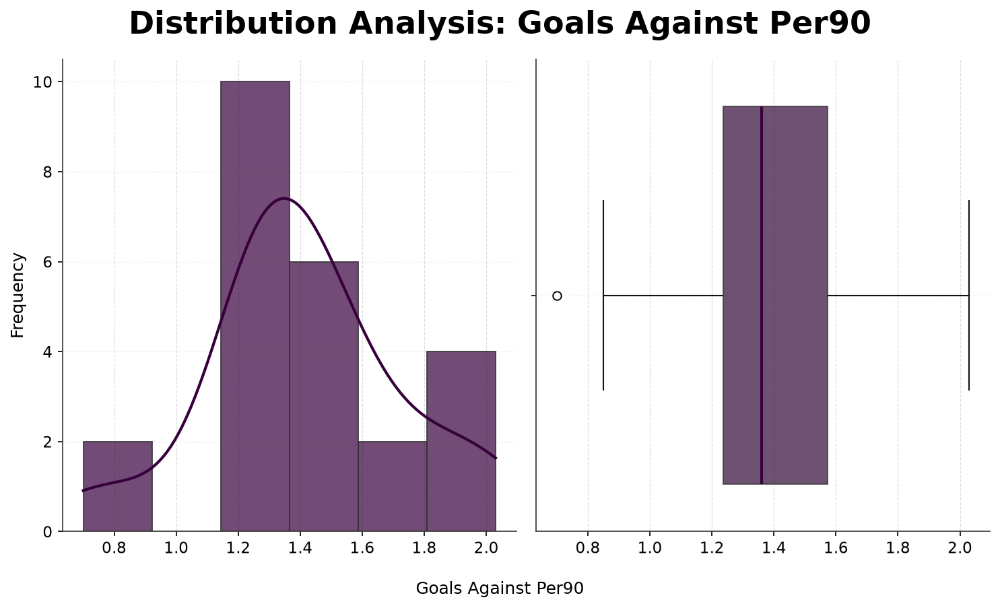

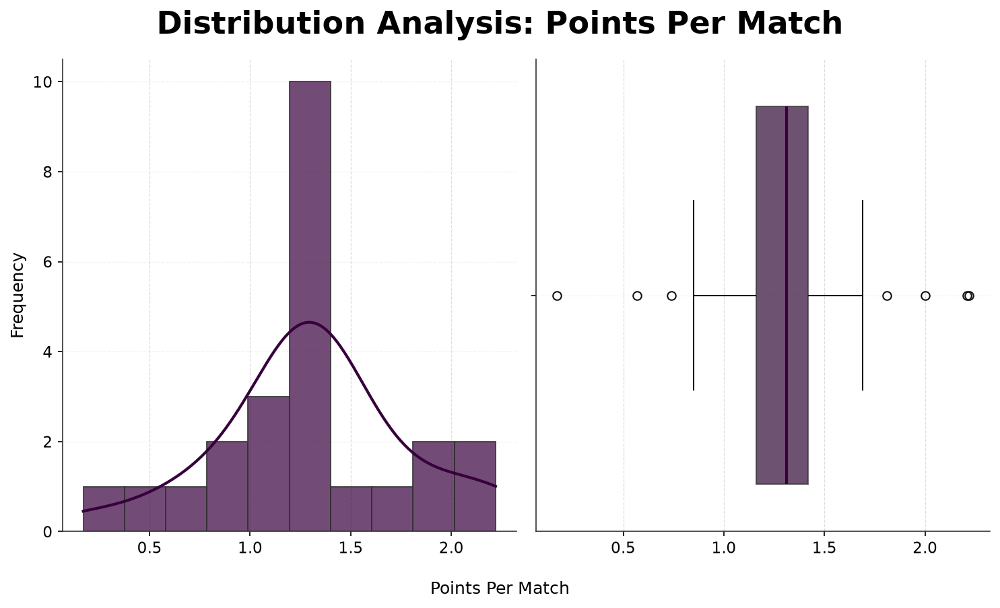

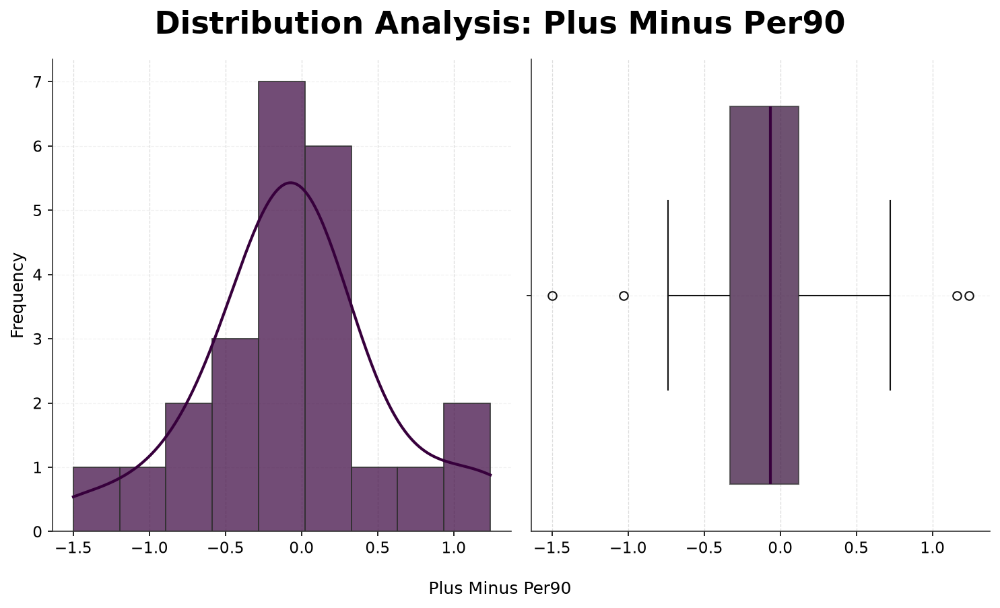

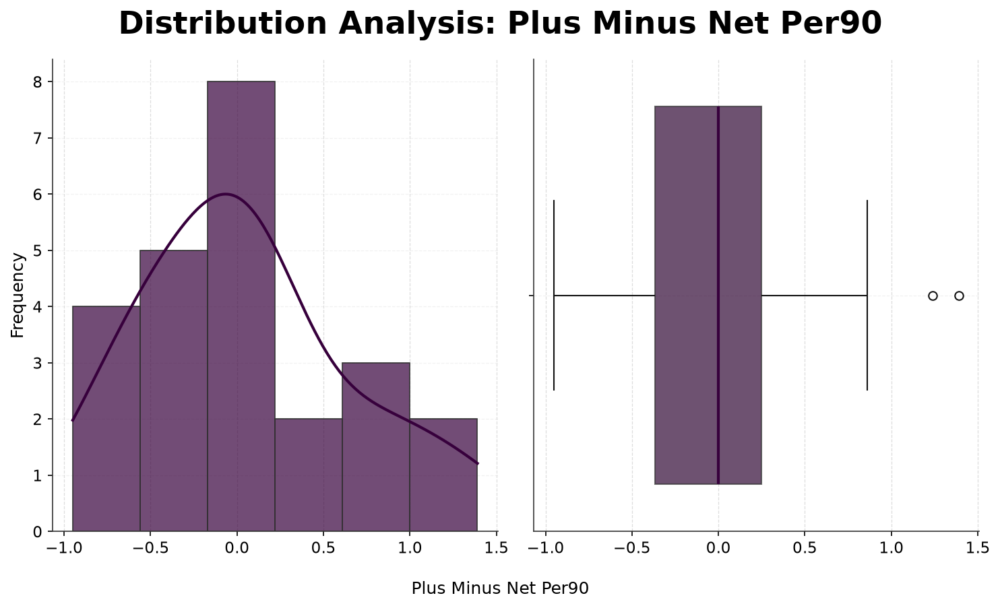

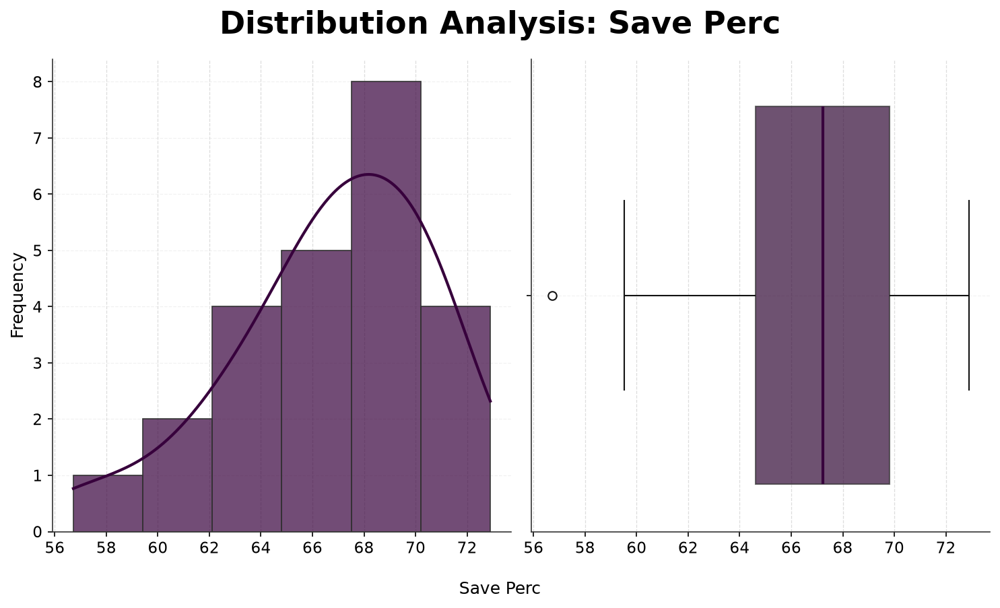

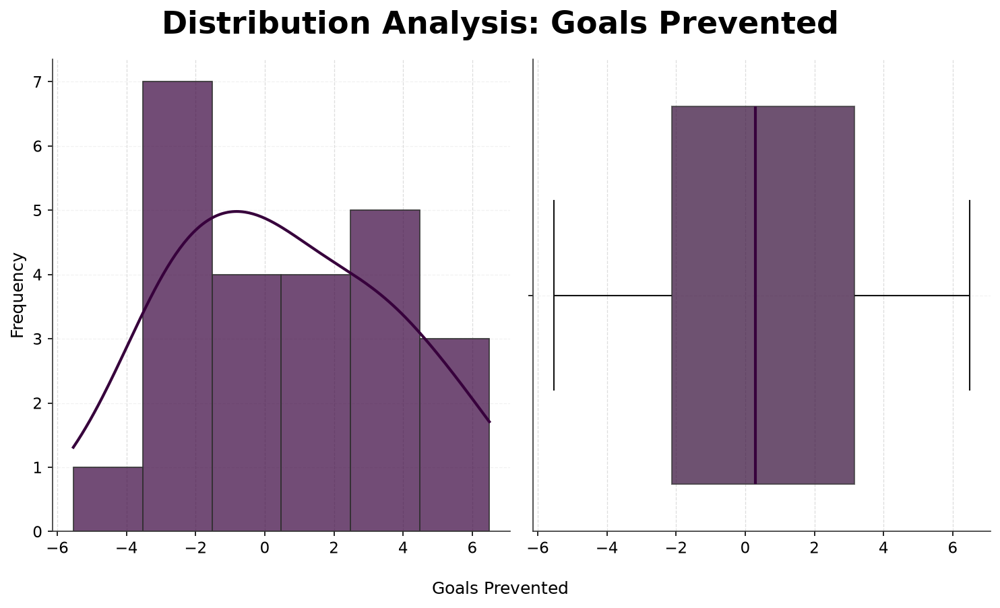

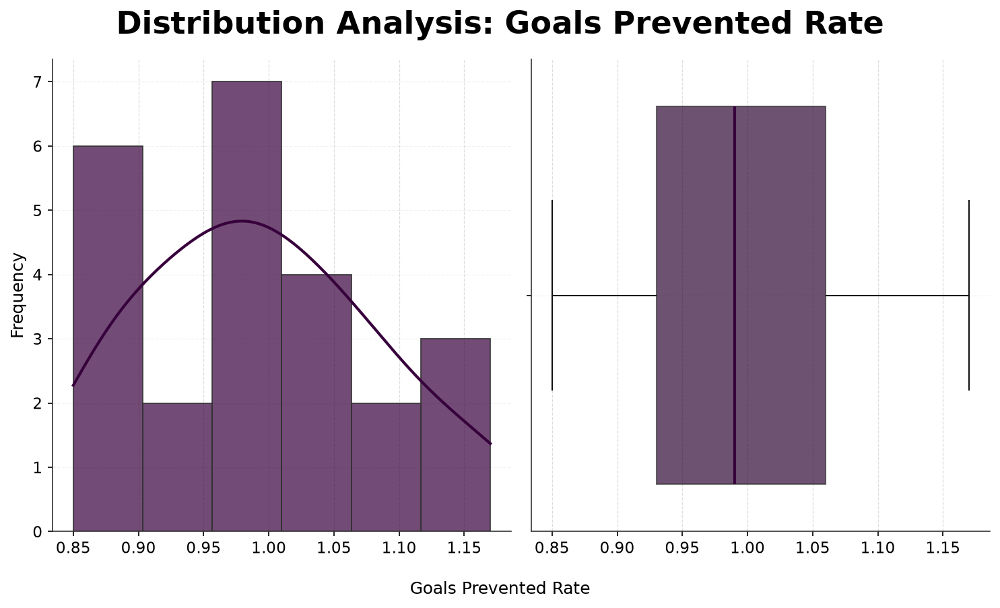

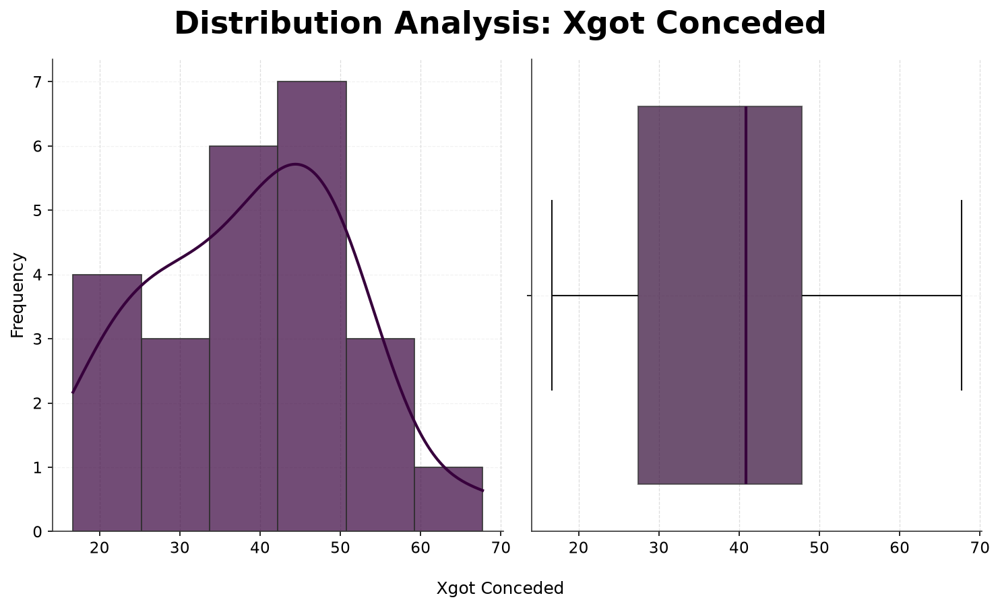

In [57]:
for col in distribution_analysis_map["Distribution (Histogram + KDE + Boxplot)"]:
    hist_kde_box_plot(df, col)

| Feature                | Finding                  | Action                      |
| ---------------------- | ------------------------ | --------------------------- |
| `goals_against_per90`  | Low outlier              | Investigate player          |
| `save_pct`             | Moderately left-skewed; no IQR outliers              | No action          |
| `points_per_match`     | Several outliers         | Investigate players/context |
| `plus_minus_per90`     | Outliers both directions | Investigate players/context |
| `plus_minus_net_per90` | High positive outliers   | Investigate players/context |
| `goals_prevented`      | Wide meaningful spread   | No action                   |
| `goals_prevented_rate` | Compact distribution     | No action                   |
| `xgot_conceded`        | Reasonably well behaved  | No action                   |


#### 2.3 Outlier Analysis

In [58]:
def identify_outlier(df: pd.DataFrame, feature: pd.Series):
    q1 = feature.quantile(0.25)
    q3 = feature.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    print(df.loc[
        (feature < lower) | (feature > upper),
        ["Player", feature.name]
    ])

In [59]:
identify_outlier(df, df["goals_against_per90"])

        Player  goals_against_per90
28  David Raya                  0.7


In [60]:
df.loc[
    df["Player"].eq("David Raya"),
    [
        "Player",
        "matches_played",
        "starts",
        "mins_played",
        "90s_played",
        "goals_conceded",
        "goals_against_per90"
    ]
]

,Player,matches_played,starts,mins_played,90s_played,goals_conceded,goals_against_per90
28,David Raya,37,37.0,3330,37.0,26,0.7


#### Outlier Investigation: Goals Against per 90

- The IQR method identified **David Raya** as a lower-tail outlier for `goals_against_per90`, with a value of **0.70 goals conceded per 90 minutes**.

- The value was investigated against his underlying playing-time and goals-conceded statistics and was found to be a valid observation rather than a data-quality issue. Therefore, the observation was retained.

- However, `goals_against_per90` is influenced by the defensive environment of the player's team. Arsenal conceded only **26 goals**, indicating a strong team defensive context. Therefore, Raya's unusually low goals-against rate may reflect both his individual goalkeeping performance and Arsenal's defensive strength.

- This highlights an important consideration for the POTSI model: goalkeeper metrics based on goals conceded should not necessarily be interpreted as purely individual performance measures.

- **Decision:** Retain the observation and account for team defensive context when evaluating goalkeeper performance in the later POTSI scoring stage.

In [61]:
identify_outlier(df, df["points_per_match"])

                  Player  points_per_match
0         Alisson Becker              1.81
8   Gianluigi Donnarumma              2.21
9        Martin Dubravka              0.57
14         Sam Johnstone              0.17
18         Senne Lammens              2.00
28            David Raya              2.22
30               Jose Sa              0.74


In [62]:
df.loc[
    df["Player"].isin([
        "Alisson Becker",
        "Gianluigi Donnarumma",
        "Martin Dubravka",
        "Sam Johnstone",
        "Senne Lammens",
        "David Raya",
        "Jose Sa"
    ]),
    [
        "Player",
        "matches_played",
        "starts",
        "mins_played",
        "90s_played",
        "points_per_match"
    ]
]

,Player,matches_played,starts,mins_played,90s_played,points_per_match
0,Alisson Becker,26,26.0,2340,26.0,1.81
8,Gianluigi Donnarumma,34,34.0,3060,34.0,2.21
9,Martin Dubravka,35,35.0,3150,35.0,0.57
14,Sam Johnstone,12,12.0,1080,12.0,0.17
18,Senne Lammens,32,32.0,2880,32.0,2.00
28,David Raya,37,37.0,3330,37.0,2.22
30,Jose Sa,23,23.0,2070,23.0,0.74


#### Outlier Investigation: Points per Match

- The IQR method identified seven players as outliers in `points_per_match`.

- The flagged observations were reviewed against player playing time. Six of the seven players had more than 20 full 90s, indicating that the extreme values were not primarily caused by very limited playing time. Sam Johnstone had a smaller sample of 12 matches, but the value remains a valid observation.

- The outliers therefore appear to represent genuine differences in team results rather than data-quality issues. Since `points_per_match` is strongly influenced by the results of the player's team, the metric should be treated as a team-context variable rather than a purely individual goalkeeper-performance measure.

- **Decision:** Retain all observations. No data correction or outlier removal is required. Team context should be considered when using `points_per_match` in the later POTSI scoring methodology.

In [63]:
identify_outlier(df, df["plus_minus_per90"])

                  Player  plus_minus_per90
8   Gianluigi Donnarumma              1.24
9        Martin Dubravka             -1.03
14         Sam Johnstone             -1.50
28            David Raya              1.16


In [64]:
identify_outlier(df, df["plus_minus_net_per90"])

                  Player  plus_minus_net_per90
8   Gianluigi Donnarumma                  1.24
18         Senne Lammens                  1.39


In [65]:
players = [
    "Gianluigi Donnarumma",
    "Martin Dubravka",
    "Sam Johnstone",
    "David Raya",
    "Senne Lammens"
]

df.loc[
    df["Player"].isin(players),
    [
        "Player",
        "matches_played",
        "starts",
        "mins_played",
        "90s_played",
        "plus_minus",
        "plus_minus_per90",
        "plus_minus_net_per90"
    ]
]

,Player,matches_played,starts,mins_played,90s_played,plus_minus,plus_minus_per90,plus_minus_net_per90
8,Gianluigi Donnarumma,34,34.0,3060,34.0,42.0,1.24,1.24
9,Martin Dubravka,35,35.0,3150,35.0,-36.0,-1.03,-0.70
14,Sam Johnstone,12,12.0,1080,12.0,-18.0,-1.50,-0.62
18,Senne Lammens,32,32.0,2880,32.0,23.0,0.72,1.39
28,David Raya,37,37.0,3330,37.0,43.0,1.16,0.16


#### Outlier Investigation: Plus/Minus Metrics

- IQR analysis identified several outliers in `plus_minus_per90` and `plus_minus_net_per90`. The flagged players were reviewed alongside their playing time and underlying plus/minus values.

- Most flagged players had substantial playing time, with four of the five unique players exceeding 30 full 90s. Sam Johnstone had a smaller sample of 12 full 90s and should therefore be interpreted with greater caution.

- The outliers are considered valid observations rather than data-quality issues. However, the two metrics produced different outlier patterns and substantially different values for some players, indicating that they should not be treated as interchangeable measures.

- Both metrics are also influenced by team performance and therefore represent a combination of individual contribution and team context.

- **Decision:** Retain all observations. No outlier removal or correction is required. The team-context dependency and differences between the two metrics should be considered during the later POTSI feature-selection/scoring stage.

In [66]:
def hist_box_plot(df: pd.DataFrame, column: str) -> None:
    title = column.replace("_", " ").title()
    ALPHA = 0.7

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        sharex=True
    )

    fig.suptitle(
            f"Distribution Analysis: {title}",
            fontsize=22,
            fontweight="bold"
        )

    sns.histplot(
        data=df,
        x=column,
        bins="auto",
        ax=axes[0],
        alpha=ALPHA,
        color=PRIMARY,
        edgecolor="#333333",
        linewidth=0.8,
    )

    style_plot(
        axes[0],
        title=None,
        xlabel=None,
        ylabel="Frequency"
    )

    # Boxplot
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[1],
        color=PRIMARY,
        boxprops={"edgecolor": "#333333", "alpha": ALPHA},
        medianprops={"color": PRIMARY, "linewidth": 2}
    )    

    style_plot(
        axes[1],
        title=None,
        xlabel=None
    )

    fig.supxlabel(title, fontsize=12)

    plt.tight_layout()
    plt.show()

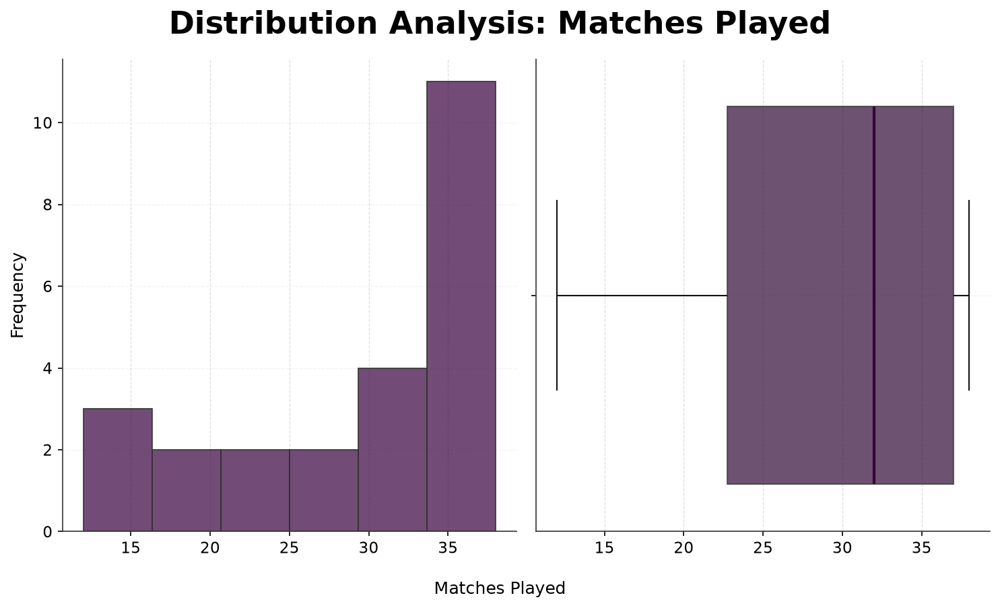

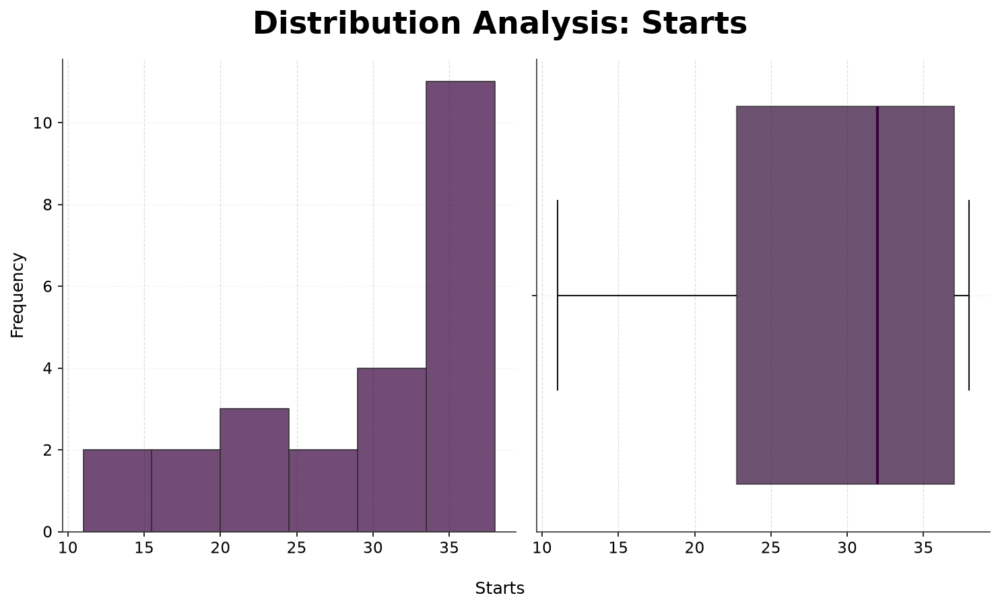

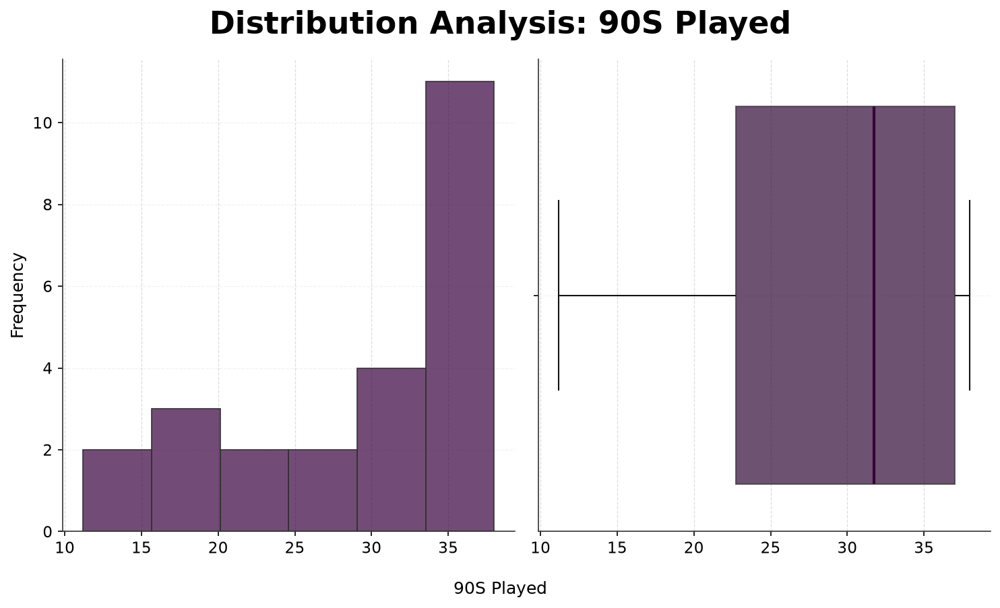

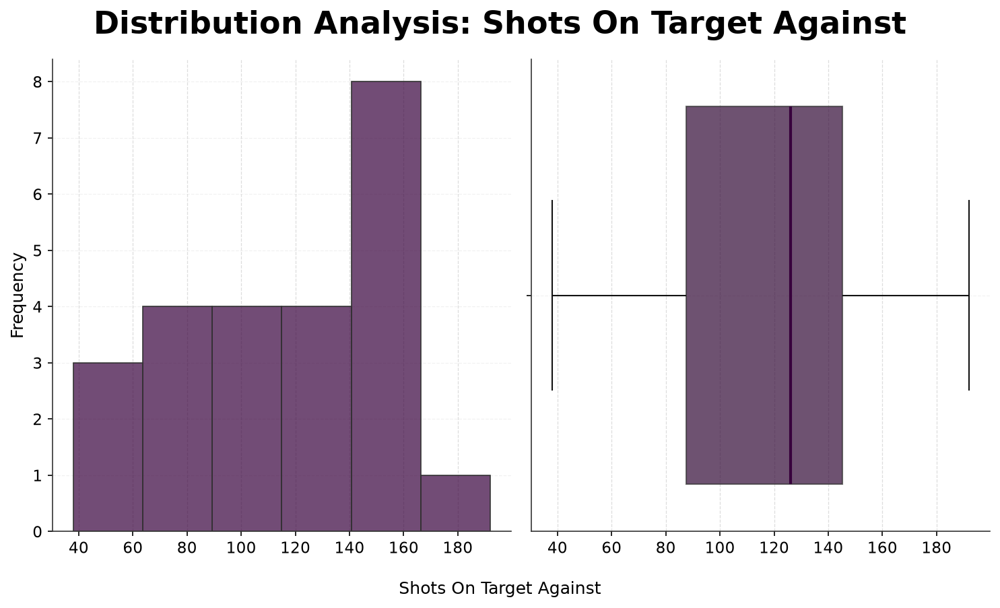

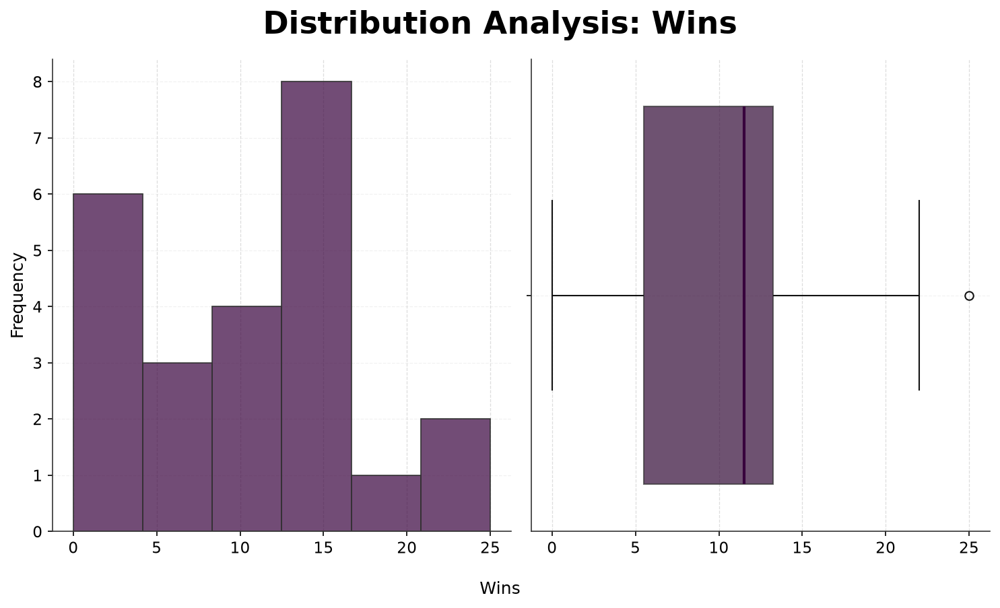

...

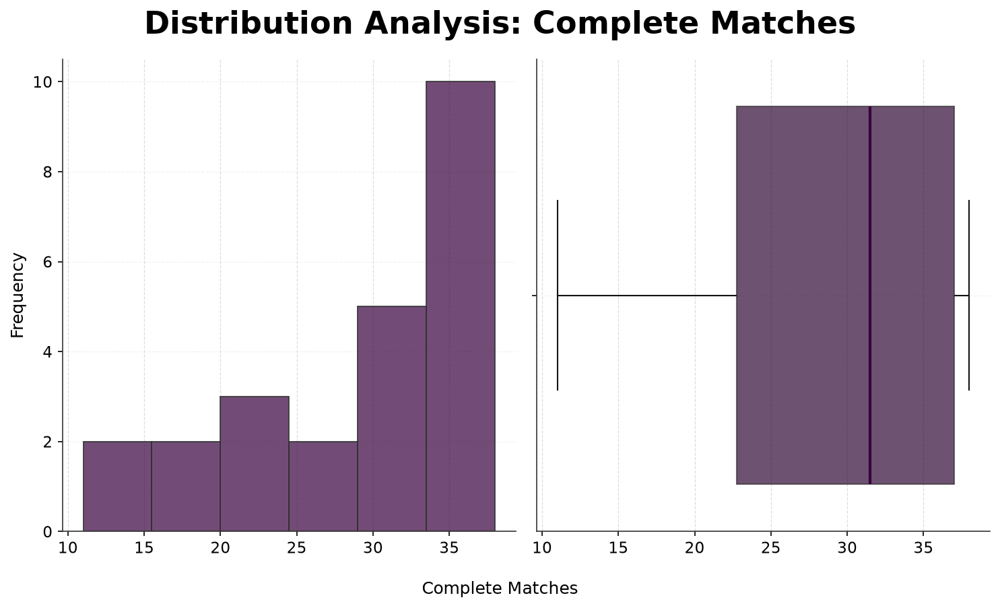

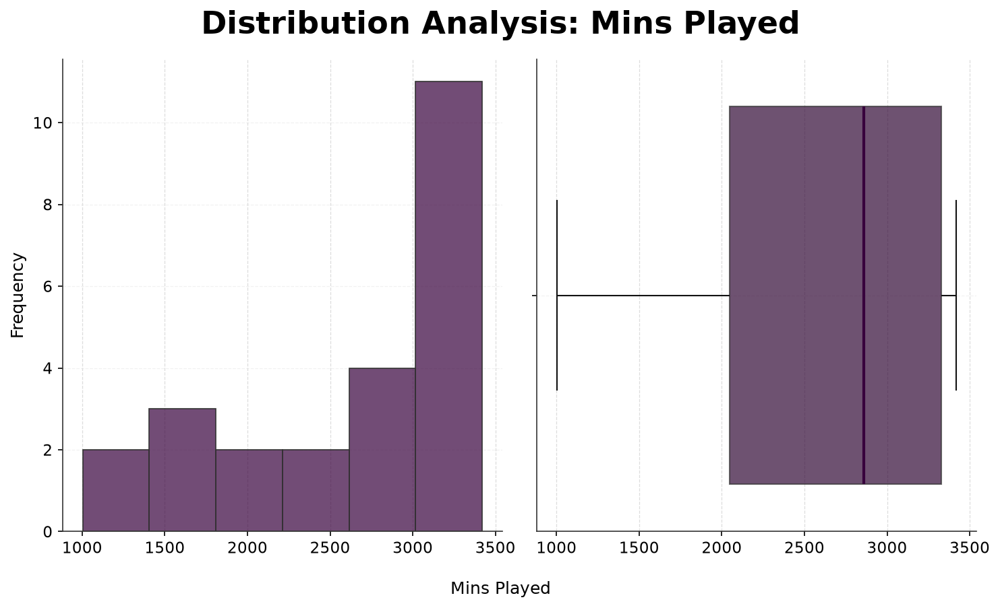

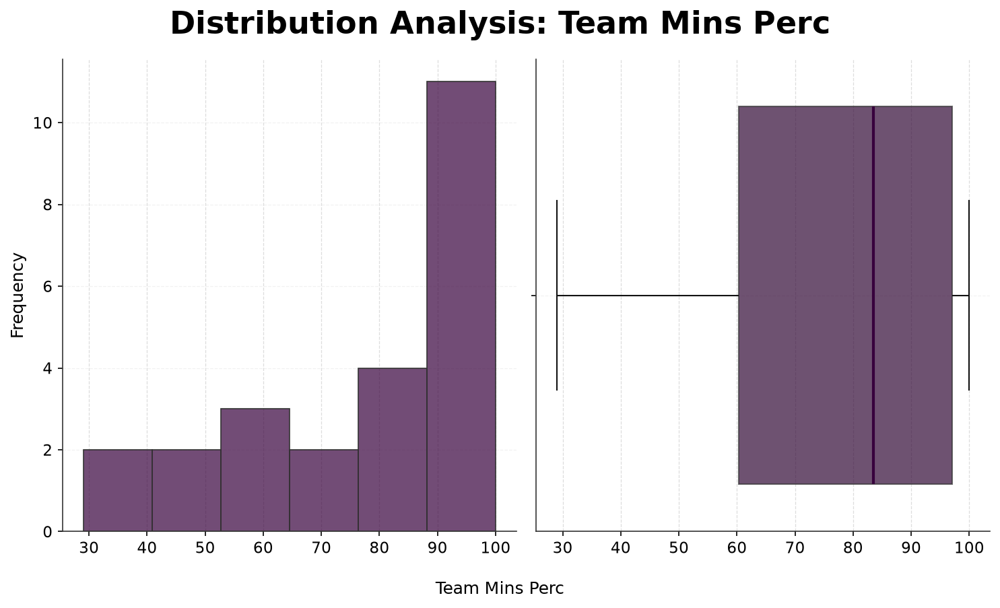

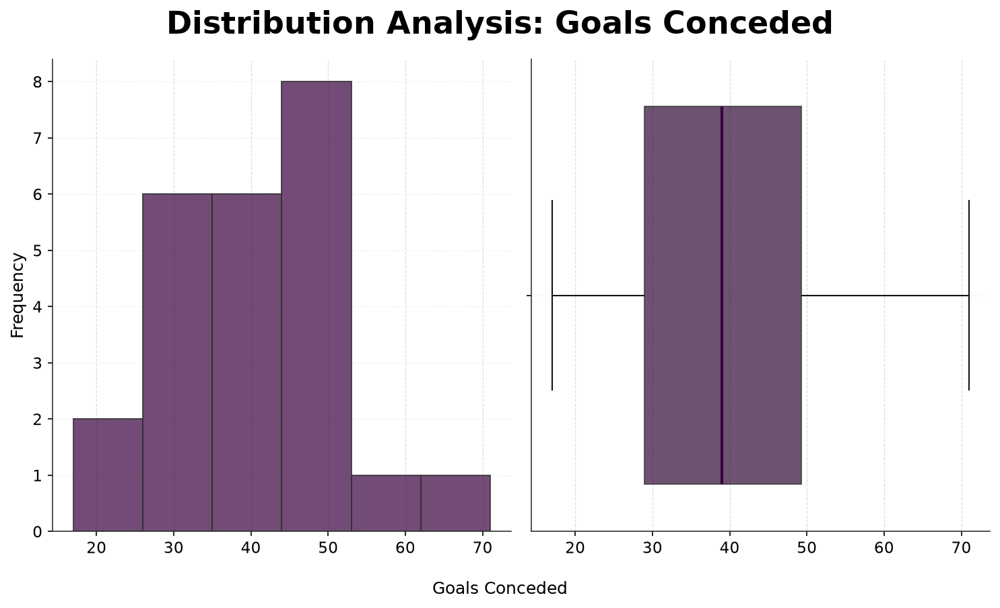

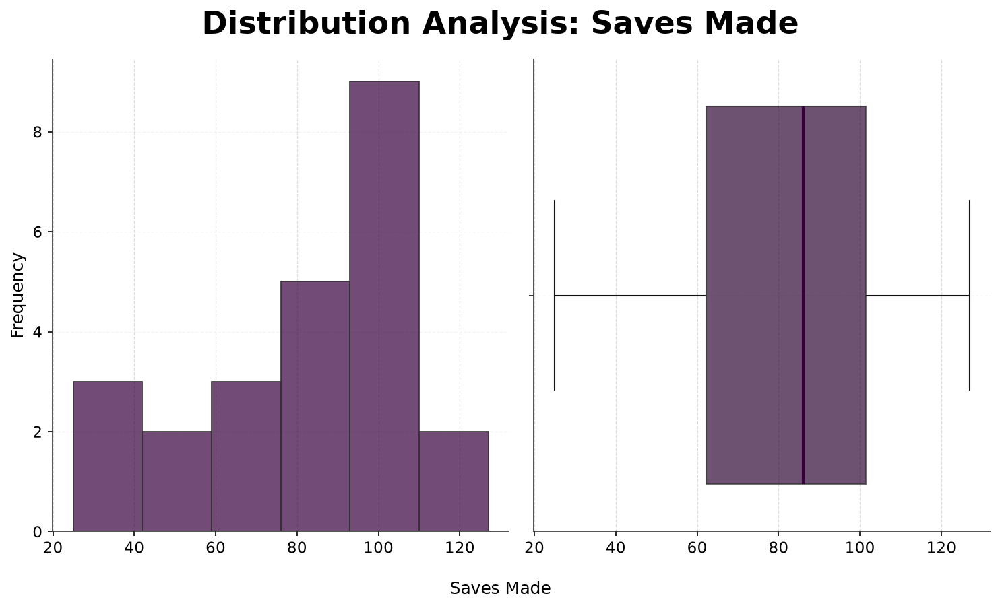

In [67]:
for col in distribution_analysis_map["Distribution (Histogram + Boxplot)"]:
    hist_box_plot(df, col)

| Feature                   | Finding                                                           | Action                          |
| ------------------------- | ----------------------------------------------------------------- | ------------------------------- |
| `starts`                  | Strong concentration toward the upper end; no meaningful outliers | No action                       |
| `90s_played`              | Strong concentration toward the upper end; no meaningful outliers | No action                       |
| `goals_against`           | Broad distribution with no obvious IQR outliers                   | No action                       |
| `shots_on_target_against` | Broad distribution with no obvious IQR outliers                   | No action                       |
| `wins`                    | Right-skewed; one high-end outlier                                | Investigate player/context      |
| `draws`                   | One high-end outlier                                              | Investigate player/context      |
| `losses`                  | No IQR outlier                                | No action      |
| `clean_sheets`            | Right-skewed; one high-end outlier                                | Investigate player/context      |
| `clean_sheet_pct`         | Several low and high outliers                                     | Investigate players/sample size |
| `pk_attempted`            | Relatively well distributed; no obvious outliers                  | No action                       |
| `fouls_drawn`             | Right-skewed; one high-end outlier                                | Investigate player/context      |
| `goals_scored_on_pitch`   | Broad distribution; no obvious outliers                           | No action                       |
| `plus_minus`              | Wide distribution with several extreme values                     | Investigate players/context     |
| `minutes_pct`             | Strong concentration toward high values; no obvious outliers      | No action                       |
| `complete_matches`        | Strong concentration toward high values; no obvious outliers      | No action                       |
| `mins_played`             | Strong concentration toward high values; no obvious outliers      | No action                       |
| `team_mins_perc`          | Strong concentration toward high values; no obvious outliers      | No action                       |
| `goals_conceded`          | Broad distribution; no obvious IQR outliers                       | No action                       |
| `saves_made`              | Broad distribution; no obvious outliers                           | No action                       |


In [68]:
identify_outlier(df, df["wins"])

        Player  wins
28  David Raya  25.0


In [69]:
df.loc[df["Player"].eq("David Raya"),
       [
           "Player",
           "starts",
           "mins_played",
           "90s_played",
           "team_mins_perc",
           "points_per_match"
       ]
]

,Player,starts,mins_played,90s_played,team_mins_perc,points_per_match
28,David Raya,37.0,3330,37.0,97,2.22


#### Outlier Investigation: Wins

* IQR analysis identified David Raya as an outlier in `wins`, with **25 wins**.

* Further review showed that Raya played 37 starts and 37 full 90s, accounting for **97% of Arsenal's available team minutes**. His high win total is therefore consistent with his near-full-season involvement.

* Raya also recorded a `points_per_match` value of 2.22, supporting the interpretation that the high win count reflects Arsenal's strong team performance rather than a data-quality issue.

* The outlier is therefore considered a valid observation. However, `wins` is strongly influenced by both playing time and team performance, meaning it does not represent individual goalkeeper performance in isolation.

* **Decision:** Retain the observation. No outlier removal or correction is required. The influence of playing time and team strength should be considered during the later POTSI feature-selection/scoring stage.


In [70]:
identify_outlier(df, df["clean_sheets"])

        Player  clean_sheets
28  David Raya          19.0


In [71]:
df.loc[
    df["Player"].eq("David Raya"),
    ["clean_sheets", "clean_sheet_pct"]
]

,clean_sheets,clean_sheet_pct
28,19.0,51.4


In [72]:
df.loc[
    df["Player"].eq("David Raya"),
    [
        "goals_conceded",
        "goals_against_per90",
        "team_mins_perc"
    ]
]

,goals_conceded,goals_against_per90,team_mins_perc
28,26,0.7,97


In [73]:
df[[
    "Player",
    "clean_sheets",
    "matches_played",
    "clean_sheet_pct"
]].sort_values(
    "clean_sheets",
    ascending=False
).head(10)

,Player,clean_sheets,matches_played,clean_sheet_pct
28,David Raya,19.0,37,51.4
8,Gianluigi Donnarumma,15.0,34,44.1
25,Jordan Pickford,11.0,38,28.9
11,Dean Henderson,11.0,37,29.7
24,Dorde Petrovic,11.0,38,28.9
16,Caoimhin Kelleher,10.0,37,27.0
35,Bart Verbruggen,10.0,38,26.3
29,Robin Roefs,10.0,35,28.6
31,Robert Sanchez,9.0,35,25.7
19,Bernd Leno,9.0,38,23.7


#### Outlier Investigation: Clean Sheets

- IQR analysis identified David Raya as an outlier in `clean_sheets`, with 19 clean sheets.

- Further review showed that Raya played 37 matches and accounted for 97% of Arsenal's available team minutes, providing sufficient playing time for a high clean-sheet total.

- Raya also recorded the highest clean-sheet percentage among the displayed players, at 51.4%, indicating that the outlier is not explained solely by greater playing time.

- His goals conceded rate of 0.7 per 90 provides additional context for the high clean-sheet total and is consistent with strong defensive performance from Arsenal during his appearances.

- The outlier is therefore considered a valid observation rather than a data-quality issue.

- **Decision:** Retain the observation. No outlier removal or correction is required. The influence of team defensive strength and playing time should be considered during the later POTSI feature-selection/scoring stage.

In [74]:
identify_outlier(df, df["clean_sheet_pct"])

                  Player  clean_sheet_pct
1        Alphonse Areola              0.0
8   Gianluigi Donnarumma             44.1
14         Sam Johnstone              0.0
27        Aaron Ramsdale              9.1
28            David Raya             51.4


In [75]:
df.loc[
    df["Player"].isin([
        "Alphonse Areola",
        "Gianluigi Donnarumma",
        "Sam Johnstone",
        "Aaron Ramsdale",
        "David Raya"
    ]),
    [
        "Player",
        "matches_played",
        "starts",
        "mins_played",
        "90s_played",
        "clean_sheets",
        "clean_sheet_pct"
    ]
]

,Player,matches_played,starts,mins_played,90s_played,clean_sheets,clean_sheet_pct
1,Alphonse Areola,20,20.0,1800,20.0,0.0,0.0
8,Gianluigi Donnarumma,34,34.0,3060,34.0,15.0,44.1
14,Sam Johnstone,12,12.0,1080,12.0,0.0,0.0
27,Aaron Ramsdale,12,11.0,1003,11.2,1.0,9.1
28,David Raya,37,37.0,3330,37.0,19.0,51.4


In [76]:
df.loc[
    df["Player"].isin(
        [
            "Alphonse Areola",
            "Sam Johnstone"

        ]
    ),
    [
    "Player",
    "matches_played",
    "starts",
    "mins_played",
    "90s_played",
    "clean_sheets",
    "clean_sheet_pct"
]
]



,Player,matches_played,starts,mins_played,90s_played,clean_sheets,clean_sheet_pct
1,Alphonse Areola,20,20.0,1800,20.0,0.0,0.0
14,Sam Johnstone,12,12.0,1080,12.0,0.0,0.0


In [77]:
df.loc[
    df["Player"].isin([
        "Alphonse Areola",
        "Gianluigi Donnarumma",
        "Sam Johnstone",
        "Aaron Ramsdale",
        "David Raya"
    ]),
    [
        "Player",
        "goals_conceded",
        "goals_against_per90",
        "clean_sheets",
        "clean_sheet_pct",
        "team_mins_perc"
    ]
]

,Player,goals_conceded,goals_against_per90,clean_sheets,clean_sheet_pct,team_mins_perc
1,Alphonse Areola,37,1.85,0.0,0.0,53
8,Gianluigi Donnarumma,29,0.85,15.0,44.1,89
14,Sam Johnstone,24,2.00,0.0,0.0,32
27,Aaron Ramsdale,17,1.52,1.0,9.1,29
28,David Raya,26,0.70,19.0,51.4,97


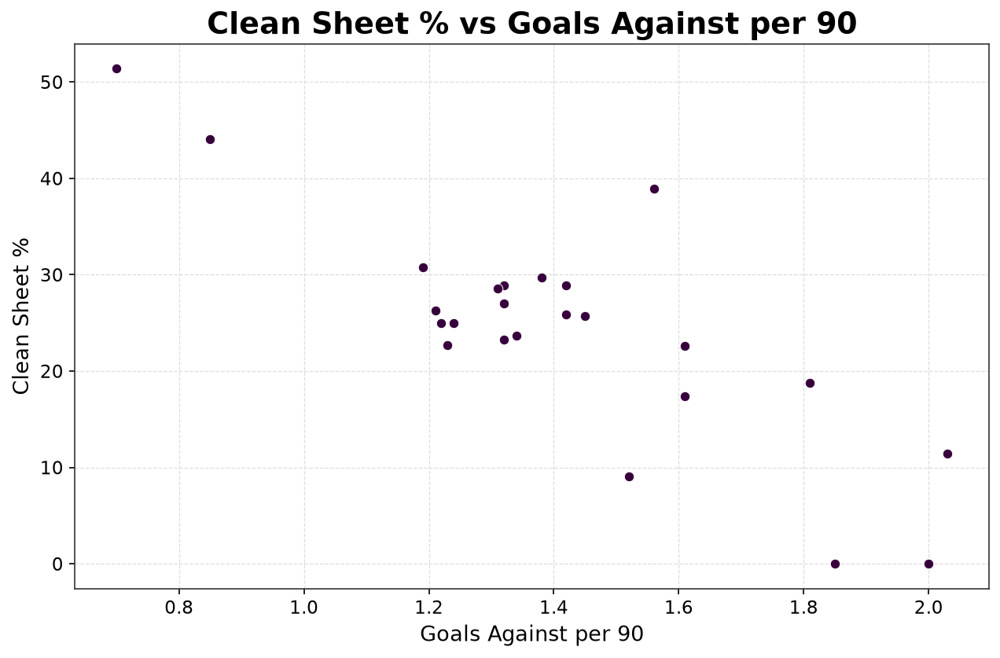

In [78]:
sns.scatterplot(
    data=df,
    x="goals_against_per90",
    y="clean_sheet_pct",
    color=PRIMARY
)


plt.xlabel("Goals Against per 90")
plt.ylabel("Clean Sheet %")
plt.title("Clean Sheet % vs Goals Against per 90")
plt.show()

In [79]:
df[["clean_sheet_pct", "goals_against_per90"]].corr(method="pearson")

,clean_sheet_pct,goals_against_per90
clean_sheet_pct,1.000000,-0.826766
goals_against_per90,-0.826766,1.000000


In [80]:
df[["clean_sheet_pct", "goals_against_per90"]].corr(method="spearman")

,clean_sheet_pct,goals_against_per90
clean_sheet_pct,1.000000,-0.671096
goals_against_per90,-0.671096,1.000000


#### Outlier Investigation: Clean Sheet Percentage

- IQR analysis identified five outliers in `clean_sheet_pct`: Alphonse Areola, Gianluigi Donnarumma, Sam Johnstone, Aaron Ramsdale, and David Raya.

- The extreme values were reviewed alongside matches played, minutes played, clean sheets, goals conceded, `goals_against_per90`, and `team_mins_perc`. The values are consistent with the underlying playing-time and team-performance context and do not indicate data-quality issues.

- The distribution shows substantial variation in clean-sheet percentage even among goalkeepers with similar numbers of appearances, indicating that playing time alone does not explain the metric.

- `clean_sheet_pct` has a strong negative association with `goals_against_per90` (**Pearson r = -0.827**; **Spearman ρ = -0.671**). Goalkeepers who concede fewer goals per 90 generally record higher clean-sheet percentages, although the relationship is not perfectly consistent across players.

- The metric is strongly influenced by team defensive performance because a goalkeeper can only record a clean sheet when the team prevents the opposition from scoring.

- **Decision:** Retain all observations. No outlier removal or correction is required. `clean_sheet_pct` should be treated as a team-context-dependent defensive measure during the later POTSI feature-selection/scoring stage.

In [81]:
identify_outlier(df, df["fouls_drawn"])

               Player  fouls_drawn
21  Emiliano Martinez         17.0


In [82]:
df.loc[
    df["Player"].eq("Emiliano Martinez"),
    [
        "Player",
        "matches_played",
        "starts",
        "mins_played",
        "90s_played",
        "fouls_drawn"
    ]
]

,Player,matches_played,starts,mins_played,90s_played,fouls_drawn
21,Emiliano Martinez,32,32.0,2835,31.5,17.0


In [83]:
df[
    df["90s_played"] >= 25
][[
    "Player",
    "90s_played",
    "fouls_drawn"
]].sort_values("fouls_drawn", ascending=False)

,Player,90s_played,fouls_drawn
21,Emiliano Martinez,31.5,17.0
28,David Raya,37.0,14.0
29,Robin Roefs,35.0,14.0
31,Robert Sanchez,33.8,13.0
9,Martin Dubravka,35.0,8.0
0,Alisson Becker,26.0,7.0
25,Jordan Pickford,38.0,6.0
19,Bernd Leno,38.0,6.0
16,Caoimhin Kelleher,37.0,6.0
11,Dean Henderson,37.0,5.0


In [84]:
df.assign(
    fouls_drawn_per90=(df["fouls_drawn"] / df["90s_played"]).round(2)
)[[
    "Player",
    "90s_played",
    "fouls_drawn",
    "fouls_drawn_per90"
]].sort_values("fouls_drawn_per90", ascending=False)

,Player,90s_played,fouls_drawn,fouls_drawn_per90
21,Emiliano Martinez,31.5,17.0,0.54
29,Robin Roefs,35.0,14.0,0.40
31,Robert Sanchez,33.8,13.0,0.38
28,David Raya,37.0,14.0,0.38
7,Karl Darlow,22.0,7.0,0.32
0,Alisson Becker,26.0,7.0,0.27
30,Jose Sa,23.0,6.0,0.26
9,Martin Dubravka,35.0,8.0,0.23
23,Lucas Perri,16.0,3.0,0.19
25,Jordan Pickford,38.0,6.0,0.16


#### Outlier Investigation: Fouls Drawn

- IQR analysis identified Emiliano Martínez as an outlier in `fouls_drawn`.
  
- Martínez recorded 17 fouls drawn across 31.5 90s, the highest raw total among the identified high-playing-time goalkeepers.
- After adjusting for playing time, Martínez still recorded the highest rate at **0.54 fouls drawn per 90**, compared with approximately **0.38–0.40 per 90** for several other high-minute goalkeepers.
  
- This indicates that the outlier is not solely explained by Martínez's greater playing time.
  
- The result does not by itself indicate a data-quality issue; it represents an unusually high value that may reflect differences in goalkeeper involvement or match situations.
  
- **Decision:** Retain the observation. No correction or removal is required. `fouls_drawn_per90` was used as an investigative measure rather than automatically added as a final POTSI feature.

In [85]:
identify_outlier(df, df["plus_minus"])

                  Player  plus_minus
8   Gianluigi Donnarumma        42.0
9        Martin Dubravka       -36.0
18         Senne Lammens        23.0
28            David Raya        43.0


In [86]:
df.loc[
    df["Player"].isin([
        "Gianluigi Donnarumma",
        "Martin Dubravka",
        "Senne Lammens",
        "David Raya"
    ]),
    [
        "Player",
        "mins_played",
        "90s_played",
        "team_mins_perc",
        "plus_minus",
        "plus_minus_per90",
        "goals_against_per90",
        "clean_sheet_pct"
    ]
]

,Player,mins_played,90s_played,team_mins_perc,plus_minus,plus_minus_per90,goals_against_per90,clean_sheet_pct
8,Gianluigi Donnarumma,3060,34.0,89,42.0,1.24,0.85,44.1
9,Martin Dubravka,3150,35.0,92,-36.0,-1.03,2.03,11.4
18,Senne Lammens,2880,32.0,84,23.0,0.72,1.22,25.0
28,David Raya,3330,37.0,97,43.0,1.16,0.70,51.4


#### Outlier Investigation: Plus/Minus

- IQR analysis identified four outliers in `plus_minus`: Gianluigi Donnarumma (+42), Martin Dúbravka (-36), Senne Lammens (+23), and David Raya (+43).
  
- All four players had substantial playing time, ranging from 32 to 37 full 90s, indicating that the outliers are not primarily the result of limited exposure.
  
- After adjusting for playing time, the extreme values remained evident, with `plus_minus_per90` ranging from **-1.03 to +1.24** among the identified outliers.
  
- The direction of the outliers is broadly consistent with related goalkeeper metrics. Raya and Donnarumma recorded positive plus/minus values alongside lower goals conceded per 90 and higher clean-sheet percentages, while Dúbravka showed the opposite pattern.
  
- The outliers therefore appear to represent genuine differences in team outcomes rather than obvious data-quality issues.
  
- However, `plus_minus` is strongly influenced by team performance because it reflects the goal difference while the goalkeeper is on the pitch. It should therefore not be interpreted as a purely individual goalkeeper-performance measure.
  
- **Decision:** Retain all observations. No correction or removal is required. The strong team-context dependency of `plus_minus` should be considered when selecting and weighting features for the final POTSI score.

In [87]:
distribution_analysis_map

{'Distribution (Histogram + KDE + Boxplot)': ['goals_against_per90',
  'points_per_match',
  'plus_minus_per90',
  'plus_minus_net_per90',
  'save_perc',
  'goals_prevented',
  'goals_prevented_rate',
  'xgot_conceded'],
 'Distribution (Histogram + Boxplot)': ['matches_played',
  'starts',
  '90s_played',
  'shots_on_target_against',
  'wins',
  'draws',
  'losses',
  'clean_sheets',
  'clean_sheet_pct',
  'pk_attempted',
  'fouls_drawn',
  'plus_minus',
  'minutes_pct',
  'complete_matches',
  'mins_played',
  'team_mins_perc',
  'goals_conceded',
  'saves_made'],
 'Value Counts': ['pk_saved',
  'pk_missed',
  'pk_save_pct',
  'pk_allowed',
  'yellow_cards',
  'red_cards',
  'minutes_per_start']}

In [88]:
value_count_features = distribution_analysis_map["Value Counts"]

value_counts_summary = []

for col in value_count_features:
    counts = df[col].value_counts()
    
    value_counts_summary.append({
        "feature": col,
        "unique_values": df[col].nunique(),
        "zero_count": (df[col] == 0).sum(),
        "zero_pct": ((df[col] == 0).mean() * 100).round(2),
        "most_common_value": counts.index[0],
        "most_common_frequency": counts.iloc[0],
        "most_common_pct": (counts.iloc[0] / len(df) * 100).round(2)
    })

value_counts_summary = pd.DataFrame(value_counts_summary)

value_counts_summary

,feature,unique_values,zero_count,zero_pct,most_common_value,most_common_frequency,most_common_pct
0,pk_saved,3,16,66.67,0.0,16,66.67
1,pk_missed,2,21,87.50,0.0,21,87.50
2,pk_save_pct,7,16,66.67,0.0,16,66.67
3,pk_allowed,7,3,12.50,2.0,6,25.00
4,yellow_cards,7,4,16.67,1.0,6,25.00
5,red_cards,2,23,95.83,0.0,23,95.83
6,minutes_per_start,3,0,0.00,90.0,20,83.33


In [89]:
value_counts_summary["concentration"] = np.select(
    [
        value_counts_summary["most_common_pct"] >= 90,
        value_counts_summary["most_common_pct"] >= 75,
        value_counts_summary["most_common_pct"] >= 50
    ],
    [
        "Very High",
        "High",
        "Moderate"
    ],
    default="Low"
)

In [90]:
value_counts_summary

,feature,unique_values,zero_count,zero_pct,most_common_value,most_common_frequency,most_common_pct,concentration
0,pk_saved,3,16,66.67,0.0,16,66.67,Moderate
1,pk_missed,2,21,87.50,0.0,21,87.50,High
2,pk_save_pct,7,16,66.67,0.0,16,66.67,Moderate
3,pk_allowed,7,3,12.50,2.0,6,25.00,Low
4,yellow_cards,7,4,16.67,1.0,6,25.00,Low
5,red_cards,2,23,95.83,0.0,23,95.83,Very High
6,minutes_per_start,3,0,0.00,90.0,20,83.33,High


#### 2.4 Concentration Analysis

- `pk_allowed` and `yellow_cards` showed good variation across the goalkeeper sample, with multiple observed values and relatively low concentration around the most common value.
- `tackles_won`, `fouls_committed`, and `interceptions` showed moderate variation despite a substantial proportion of zero values.
- `pk_saved`, `assists`, `goals_assists`, `assists_per90`, and `own_goals` were strongly zero-concentrated, reflecting the rarity of these events among goalkeepers.
- `red_cards`, `crosses`, `minutes_per_sub`, and `sub_appearances` showed very limited variation and may have limited discriminatory value in the final scoring model.
- These findings do not justify removing features at this stage. They will instead inform feature selection and weighting during the POTSI construction stage.

In [91]:
def unique_value_check(df: pd.DataFrame, feature: str) -> None:
    print("=" * 50)
    print(f"Feature: {feature}".center(50))
    print("=" * 50)

    print(f"Unique values: {df[feature].nunique()}")

    print("\nUnique values:")
    print(df[feature].unique())

    print("\nValue counts:")
    print(df[feature].value_counts().sort_index())

#### 2.5 Unique Value Check --- TODO

- `goals`, `second_yellow_card`, and `team_mins` each contain only one unique value across all 24 goalkeepers.
  
- `goals` and `second_yellow_card` are constant at 0 for all players, indicating no variation in these events within the sample.
  
- Since none of the three features provides player-level variation in this dataset, they cannot contribute to differentiating players in the POTSI ranking.
  
- **Decision:** Exclude these three features from further player-level distribution/relationship analysis and the final POTSI scoring framework.

### Distribution Analysis - Key Findings

The distribution analysis shows that goalkeeper statistics are strongly influenced by four underlying factors: playing time, workload, team environment, and the distinction between volume and rate-based measures.

Playing-time variables such as `starts`, `90s_played`, `mins_played`, `minutes_pct`, `team_mins_perc`, and `complete_matches` are concentrated toward higher values, reflecting a dataset dominated by established starting goalkeepers. This also means that many raw counting statistics must be interpreted alongside exposure. Metrics such as `wins`, `clean_sheets`, `goals_conceded`, and `saves_made` can increase simply because a goalkeeper plays more minutes.

The outlier investigation demonstrated that extreme values are not necessarily data-quality issues. For example, David Raya's high `wins` and `clean_sheets` were supported by near-full-season playing time and Arsenal's strong team performance. Similarly, extreme `plus_minus` values remained evident even after considering playing time and were broadly consistent with related defensive and team-result metrics. Outliers were therefore retained unless evidence indicated a genuine data-quality problem.

Rate-based metrics provided additional information beyond raw counts but also revealed important contextual dependencies. `clean_sheet_pct` showed a strong negative relationship with `goals_against_per90` (**Pearson r = -0.827**; **Spearman ρ = -0.671**), indicating that clean-sheet percentage is closely associated with the team's ability to prevent goals. This reinforces that clean-sheet measures should not be interpreted as purely individual goalkeeper performance.

The analysis of discrete and count features revealed substantial differences in feature variation. `pk_allowed` and `yellow_cards` showed meaningful variation, while features such as `red_cards`, `crosses`, `sub_appearances`, and `minutes_per_sub` were highly concentrated around a single value. Several rare-event features, including `assists`, `own_goals`, and penalty-related statistics, were heavily zero-inflated and will require caution when assessing their usefulness.

The analysis also identified features with no player-level variation. `goals` and `second_yellow_card` were zero for every goalkeeper, while `team_mins` was constant at 3,420 minutes, representing the fixed 38 × 90 minutes available in a Premier League season. These features provide no discriminatory information and were excluded from further player-level analysis.

Overall, the distributions largely represent genuine differences in goalkeeper role, workload, efficiency, and team environment rather than data-quality problems. No blanket transformations or outlier removals were applied.

The distribution analysis therefore establishes several considerations for the subsequent relationship analysis: distinguish volume from efficiency, account for playing-time exposure, identify team-dependent metrics, assess rare and low-variation features carefully, and investigate redundancy between related performance measures.

### 3. Relationship Analysis

#### 3.1 Correlation Analysis

In [92]:
constant_col = numeric_only_df.columns[
    numeric_only_df.nunique() <= 1
].to_list()

constant_col

[]

In [93]:
numeric_only_df = numeric_only_df.drop(columns=constant_col)

In [94]:
pearson_corr = numeric_only_df.corr(method="pearson")
spearman_corr = numeric_only_df.corr(method="spearman")

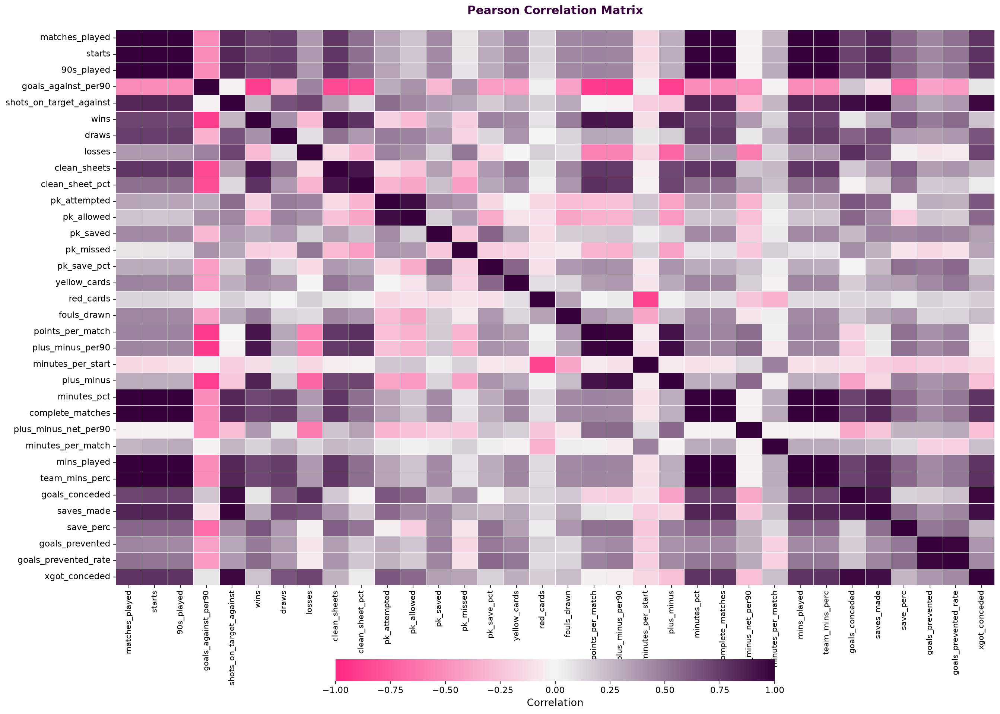

In [95]:
fig, ax = plt.subplots(figsize=(18, 14))

sns.heatmap(
    pearson_corr,
    cmap=PL_DIVERGING,
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.4,
    linecolor="white",
    square=False,
    cbar_kws={
        "orientation": "horizontal",
        "shrink": 0.5,
        "pad": 0.1,
        "label": "Correlation"
    },
    ax=ax
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=11)

style_plot(
    ax=ax,
    title="Pearson Correlation Matrix",
)

plt.tight_layout()
plt.show()

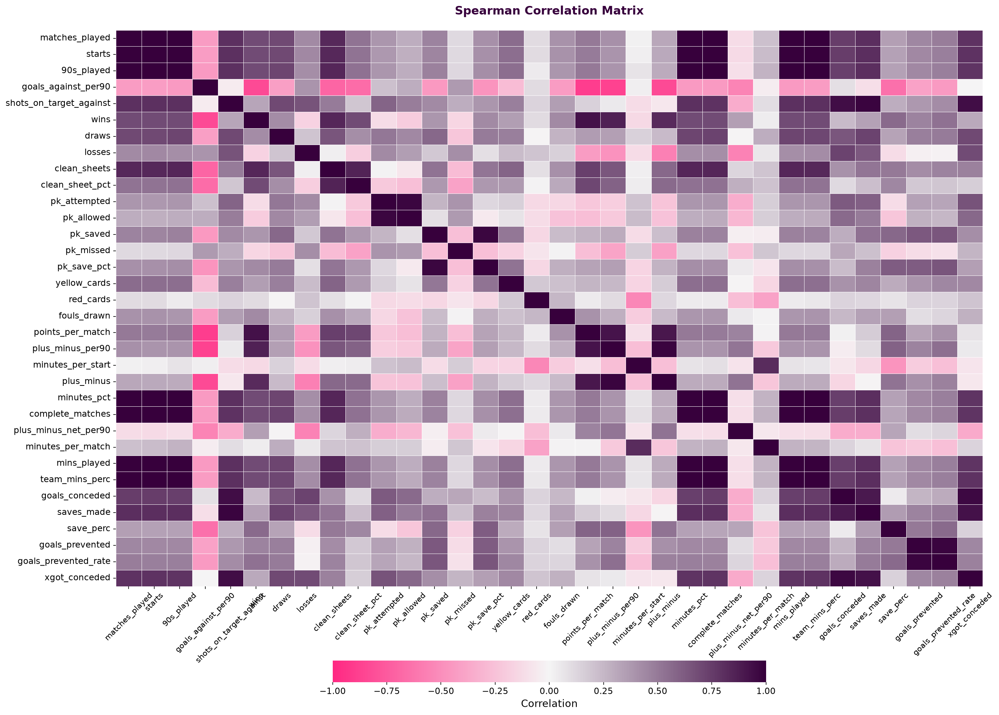

In [96]:
fig, ax = plt.subplots(figsize=(18, 14))

sns.heatmap(
    spearman_corr,
    cmap=PL_DIVERGING,
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.4,
    linecolor="white",
    square=False,
    cbar_kws={
        "orientation": "horizontal",
        "shrink": 0.5,
        "pad": 0.1,
        "label": "Correlation"
    },
    ax=ax
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=11)

style_plot(
    ax=ax,
    title="Spearman Correlation Matrix",
)

plt.tight_layout()
plt.show()

In [97]:
def get_strong_correlation(corr_matrix, threshold=0.7):

    mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    corr = corr_matrix.where(mask)

    pairs = (
        corr.unstack()
        .reset_index()
        .rename(
            columns={
                "level_0": "feature_1",
                "level_1": "feature_2",
                0: "correlation"
            }
        )
        .dropna(subset=["correlation"])
    )

    return (
        pairs[pairs["correlation"].abs() >= threshold].sort_values(by="correlation", key=abs, ascending=False)
    )


In [98]:
strong_corr_pearson = get_strong_correlation(pearson_corr)

In [99]:
strong_corr_spearman = get_strong_correlation(spearman_corr)

In [100]:
strong_corr_pearson

,feature_1,feature_2,correlation
906,mins_played,minutes_pct,0.999999
750,minutes_pct,90s_played,0.999999
886,mins_played,90s_played,0.999998
944,team_mins_perc,mins_played,0.999923
940,team_mins_perc,minutes_pct,0.999914
...,...,...,...
172,wins,90s_played,0.710599
889,mins_played,wins,0.710488
722,plus_minus,clean_sheets,0.709521
787,complete_matches,wins,0.708393


In [101]:
strong_corr_pearson

,feature_1,feature_2,correlation
906,mins_played,minutes_pct,0.999999
750,minutes_pct,90s_played,0.999999
886,mins_played,90s_played,0.999998
944,team_mins_perc,mins_played,0.999923
940,team_mins_perc,minutes_pct,0.999914
...,...,...,...
172,wins,90s_played,0.710599
889,mins_played,wins,0.710488
722,plus_minus,clean_sheets,0.709521
787,complete_matches,wins,0.708393


#### 3.2 Redundancy Analysis

In [102]:
corr_table = pd.merge(
    strong_corr_pearson, 
    strong_corr_spearman, 
    on=["feature_1", "feature_2"],
    how="outer",
    suffixes=("_pearson", "_spearman")
    )

In [103]:
corr_table

,feature_1,feature_2,correlation_pearson,correlation_spearman
0,90s_played,matches_played,0.998953,0.996933
1,90s_played,starts,0.999518,0.997372
2,clean_sheet_pct,clean_sheets,0.912556,0.858715
3,clean_sheet_pct,goals_against_per90,-0.826766,NaN
4,clean_sheet_pct,wins,0.795562,NaN
...,...,...,...,...
101,xgot_conceded,minutes_pct,0.787488,0.786918
102,xgot_conceded,saves_made,0.934013,0.926458
103,xgot_conceded,shots_on_target_against,0.961639,0.937746
104,xgot_conceded,starts,0.789724,0.795466


In [104]:
conditions = [
    (~corr_table["correlation_pearson"].isna()) & (~corr_table["correlation_spearman"].isna()),
    (~corr_table["correlation_pearson"].isna()) & (corr_table["correlation_spearman"].isna()),
    (corr_table["correlation_pearson"].isna()) & (~corr_table["correlation_spearman"].isna())   
]

choices = ["both", "pearson", "spearman"]

corr_table["relationship_type"] = np.select(condlist=conditions, choicelist=choices, default="neither")

corr_table

,feature_1,feature_2,correlation_pearson,correlation_spearman,relationship_type
0,90s_played,matches_played,0.998953,0.996933,both
1,90s_played,starts,0.999518,0.997372,both
2,clean_sheet_pct,clean_sheets,0.912556,0.858715,both
3,clean_sheet_pct,goals_against_per90,-0.826766,NaN,pearson
4,clean_sheet_pct,wins,0.795562,NaN,pearson
...,...,...,...,...,...
101,xgot_conceded,minutes_pct,0.787488,0.786918,both
102,xgot_conceded,saves_made,0.934013,0.926458,both
103,xgot_conceded,shots_on_target_against,0.961639,0.937746,both
104,xgot_conceded,starts,0.789724,0.795466,both


In [105]:
corr_table.shape
corr_table.info()
corr_table["relationship_type"].value_counts()

print(f"Count Breakdown: {corr_table["relationship_type"].value_counts()}")

corr_table["relationship_type"].value_counts(normalize=True) * 100

<class 'pandas.DataFrame'>
RangeIndex: 106 entries, 0 to 105
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   feature_1             106 non-null    str    
 1   feature_2             106 non-null    str    
 2   correlation_pearson   103 non-null    float64
 3   correlation_spearman  88 non-null     float64
 4   relationship_type     106 non-null    str    
dtypes: float64(2), str(3)
memory usage: 7.3 KB
Count Breakdown: relationship_type
both        85
pearson     18
spearman     3
Name: count, dtype: int64


relationship_type
both        80.188679
pearson     16.981132
spearman     2.830189
Name: proportion, dtype: float64

In [106]:
corr_table["min_abs_corr"] = corr_table[
    ["correlation_pearson", "correlation_spearman"]
].abs().min(axis=1)

In [107]:
both = corr_table[corr_table["relationship_type"] == "both"].copy()

pearson_only = corr_table[
    corr_table["relationship_type"] == "pearson"
].copy()

spearman_only = corr_table[
    corr_table["relationship_type"] == "spearman"
].copy()

In [108]:
both.sort_values("min_abs_corr", ascending=False)

,feature_1,feature_2,correlation_pearson,correlation_spearman,relationship_type,min_abs_corr
37,mins_played,minutes_pct,0.999999,1.000000,both,0.999999
41,minutes_pct,90s_played,0.999999,1.000000,both,0.999999
32,mins_played,90s_played,0.999998,1.000000,both,0.999998
81,team_mins_perc,90s_played,0.999911,0.999781,both,0.999781
86,team_mins_perc,mins_played,0.999923,0.999781,both,0.999781
...,...,...,...,...,...,...
18,draws,90s_played,0.744086,0.711561,both,0.711561
43,minutes_pct,draws,0.744048,0.711561,both,0.711561
84,team_mins_perc,draws,0.744157,0.710179,both,0.710179
63,points_per_match,clean_sheet_pct,0.800762,0.704461,both,0.704461


In [109]:
# correlation more than 0.98
high_redundancy = corr_table[corr_table["min_abs_corr"] >= 0.98].sort_values(by="min_abs_corr", ascending=False)

In [110]:
high_redundancy_list = list(high_redundancy[["feature_1", "feature_2"]].itertuples(index=False, name=None))

In [111]:
len(high_redundancy_list)

22

In [112]:
high_redundancy_list

[('mins_played', 'minutes_pct'),
 ('minutes_pct', '90s_played'),
 ('mins_played', '90s_played'),
 ('team_mins_perc', '90s_played'),
 ('team_mins_perc', 'minutes_pct'),
 ('team_mins_perc', 'mins_played'),
 ('complete_matches', '90s_played'),
 ('complete_matches', 'minutes_pct'),
 ('mins_played', 'complete_matches'),
 ('starts', 'matches_played'),
 ('team_mins_perc', 'complete_matches'),
 ('team_mins_perc', 'starts'),
 ('team_mins_perc', 'matches_played'),
 ('90s_played', 'starts'),
 ('mins_played', 'starts'),
 ('minutes_pct', 'starts'),
 ('90s_played', 'matches_played'),
 ('mins_played', 'matches_played'),
 ('minutes_pct', 'matches_played'),
 ('complete_matches', 'starts'),
 ('complete_matches', 'matches_played'),
 ('saves_made', 'shots_on_target_against')]

In [113]:
def investigate_correlation_pair(df, corr_table, feature_pair):
    
    feature_1, feature_2 = feature_pair
    
    # Get correlation values
    row = corr_table[
        (
            (corr_table["feature_1"] == feature_1) &
            (corr_table["feature_2"] == feature_2)
        ) |
        (
            (corr_table["feature_1"] == feature_2) &
            (corr_table["feature_2"] == feature_1)
        )
    ].iloc[0]
    
    pearson = row["correlation_pearson"]
    spearman = row["correlation_spearman"]
    
    print("=" * 70)
    print(f"{feature_1} vs {feature_2}")
    print("=" * 70)
    
    # Correlations
    print(f"Pearson correlation : {pearson:.4f}")
    print(f"Spearman correlation: {spearman:.4f}")
    print(f"Difference          : {abs(pearson - spearman):.4f}")
    
    # Descriptive statistics
    print("\nDescriptive Statistics")
    display(df[[feature_1, feature_2]].describe())
    
    # Distributions
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    sns.histplot(df[feature_1], kde=True, ax=axes[0], color=PRIMARY)
    axes[0].set_title(feature_1)
    
    sns.histplot(df[feature_2], kde=True, ax=axes[1], color=SECONDARY)
    axes[1].set_title(feature_2)
    
    plt.tight_layout()
    plt.show()
    
    # Scatterplot
    plt.figure(figsize=(7, 5))
    
    sns.scatterplot(
        data=df,
        x=feature_1,
        y=feature_2,
        color=PRIMARY
    )
    
    plt.title(f"{feature_1} vs {feature_2}")
    plt.tight_layout()
    plt.show()

mins_played vs minutes_pct
Pearson correlation : 1.0000
Spearman correlation: 1.0000
Difference          : 0.0000

Descriptive Statistics


,mins_played,minutes_pct
count,24.000000,24.000000
mean,2624.708333,76.750000
std,781.084557,22.835994
min,1003.000000,29.400000
25%,2047.500000,59.850000
50%,2857.500000,83.550000
75%,3330.000000,97.400000
max,3420.000000,100.000000


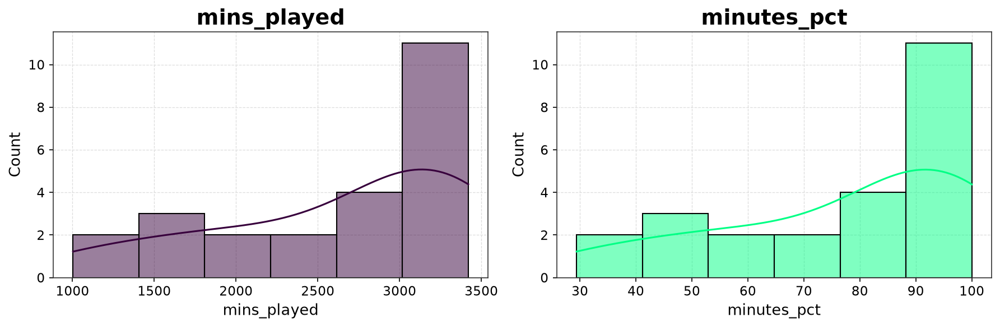

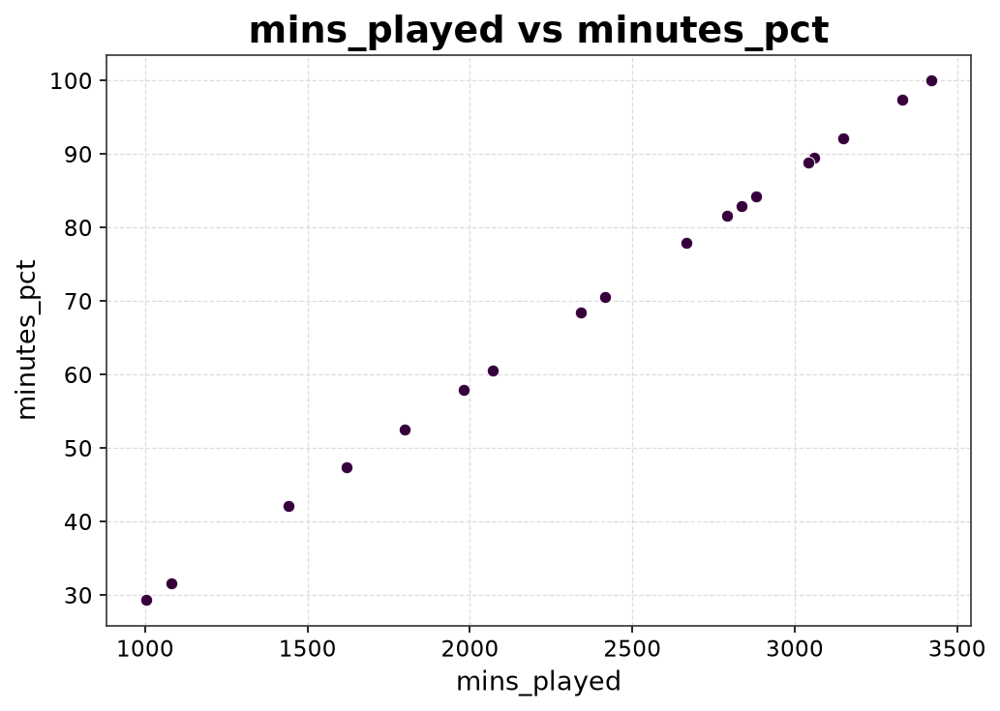

In [114]:

investigate_correlation_pair(df, corr_table, high_redundancy_list[0])

- `goals_assists` vs `assists`

    Both Pearson and Spearman correlations exceed the redundancy screening threshold. Inspection of the underlying values shows that only one goalkeeper recorded an assist, while all other observations are zero. `goals_assists` therefore provides no meaningful additional information beyond assists within the goalkeeper dataset. 

    **Decision:** Retain `assists` and flag `goals_assists` for removal during final feature selection.

In [115]:
def investigate_correlation_pair(df, corr_table, feature_pair):
    feature_1, feature_2 = feature_pair
    row = corr_table.iloc[0]
    pearson, spearman = row["correlation_pearson"], row["correlation_spearman"]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist(df[feature_1], bins=20, color=ACCENT, edgecolor=PRIMARY, alpha=0.85)
    axes[0].set_title(feature_1, fontsize=10, color=PRIMARY)

    axes[1].hist(df[feature_2], bins=20, color=SECONDARY, edgecolor=PRIMARY, alpha=0.85)
    axes[1].set_title(feature_2, fontsize=10, color=PRIMARY)

    axes[2].scatter(df[feature_1], df[feature_2], color=ACCENT, edgecolor=PRIMARY, linewidth=0.6, s=50, alpha=0.85)
    axes[2].set_title(f"r={pearson:.2f} (ρ={spearman:.2f})", fontsize=10, color=PRIMARY)
    axes[2].set_xlabel(feature_1, fontsize=8)
    axes[2].set_ylabel(feature_2, fontsize=8)

    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(labelsize=7)

    fig.suptitle(f"{feature_1} vs {feature_2}  (n={len(df)})", fontsize=13, fontweight="bold", color=PRIMARY, y=1.03)
    plt.tight_layout()
    plt.show()

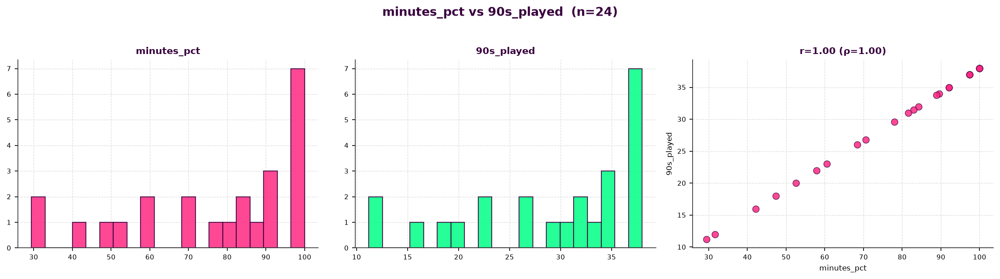

In [116]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[1])

- `mins_played` vs `minutes_pct`

    Both Pearson and Spearman correlations exceed the redundancy screening threshold. `minutes_pct` is a direct transformation of `mins_played` relative to total team minutes and provides the same information on a standardized scale. 
    
    **Decision:** Retain `minutes_pct` and flag `mins_played` for removal during final feature selection.

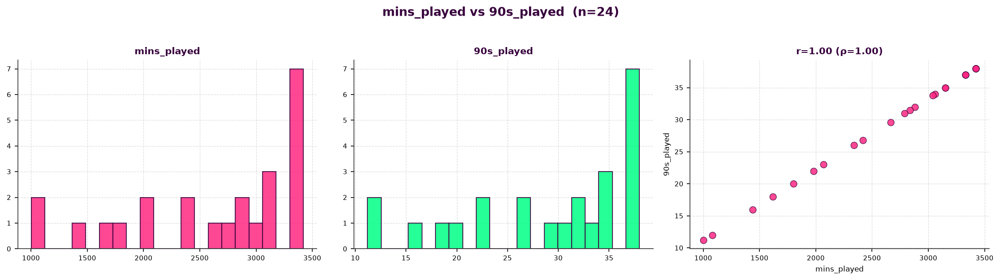

In [117]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[2])

- `minutes_pct` vs `90s_played`

    Both Pearson and Spearman correlations are **1.00**. Although the metrics are expressed differently, they represent the same playing-time information because all teams have the same total available minutes in the dataset. `90s_played` therefore provides no additional information beyond `minutes_pct`.

    **Decision:** Retain `minutes_pct` and flag `90s_played` for removal during final feature selection.

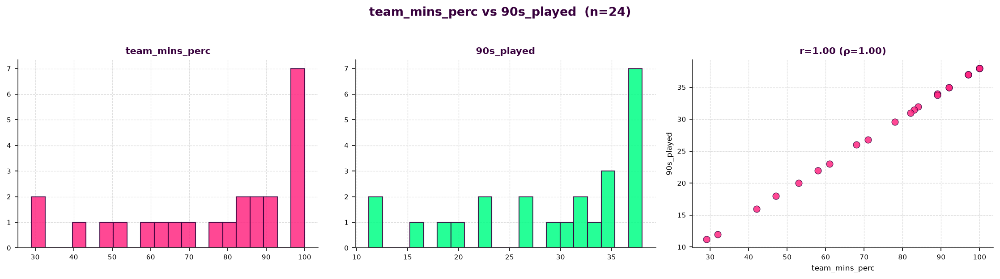

In [118]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[3])

- `mins_played` vs `90s_played`

    Both Pearson and Spearman correlations are **1.00**. `90s_played` is a direct transformation of `mins_played` and therefore provides no additional information.

    **Decision:** Retain `minutes_pct` as the preferred playing-time measure and flag `mins_played` and `90s_played` for removal during final feature selection.

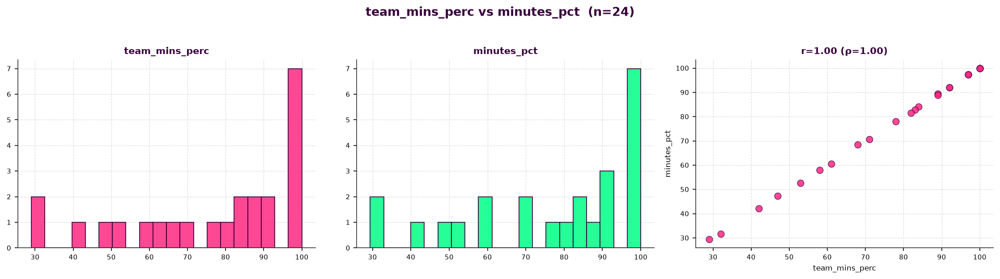

In [119]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[4])

- `team_mins_perc` vs `mins_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9999** and **0.9998**). `team_mins_perc` represents team-level playing-time availability and does not provide meaningful additional information for evaluating individual goalkeeper performance.


    **Decision:** Treat as part of the playing-time redundancy group. Final feature retention will be decided after reviewing all related playing-time variables.

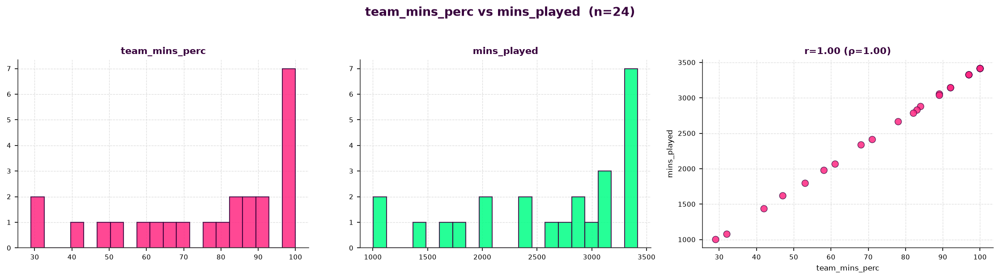

In [120]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[5])

- `team_mins_perc` vs `90s_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9999** and **0.9998**). The scatter plot shows an almost perfectly linear relationship because both variables measure goalkeeper playing time, with `team_mins_perc` expressing it relative to the team's available minutes.

    **Decision:** Keep `team_mins_perc`; flag `90s_played` for removal during final feature selection.

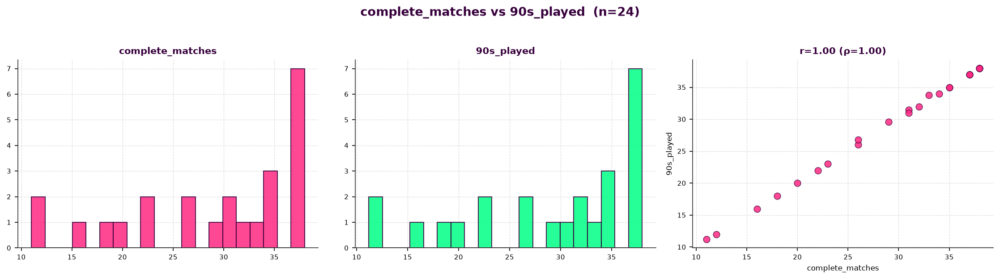

In [121]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[6])

- `team_mins_perc` vs `minutes_pct`

    Both Pearson and Spearman correlations are extremely strong (**0.9999** and **0.9998**), with nearly identical distributions. The two features therefore provide essentially the same playing-time information.

    **Decision:** Keep `minutes_pct`; flag `team_mins_perc` for removal during final feature selection.

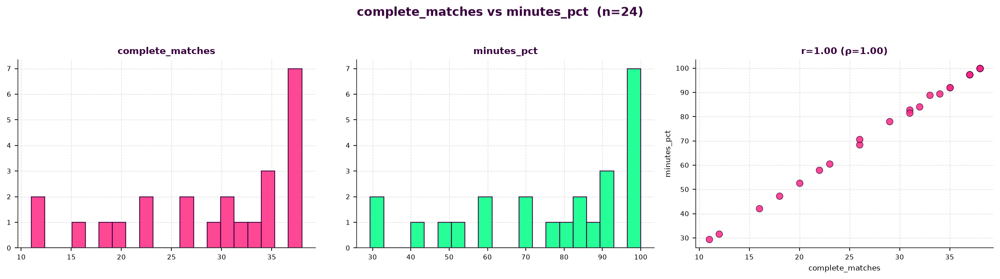

In [122]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[7])

- `complete_matches` vs `90s_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9996**). The scatterplot shows an almost perfectly linear relationship, indicating that `complete_matches` provides very little additional information beyond playing time.

    **Decision:** Both features belong to the playing-time redundancy group. `minutes_pct` is retained as the preferred representation; `complete_matches` and `90s_played` are flagged for removal during final feature selection.

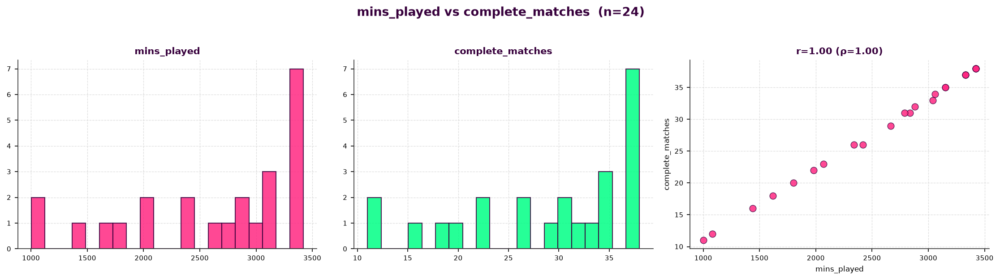

In [123]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[8])

- `complete_matches` vs `minutes_pct`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9996**). The scatterplot shows an almost perfectly linear relationship, indicating that `complete_matches` provides very little additional information beyond playing time.

    **Decision:** Keep `minutes_pct`; flag `complete_matches` for removal during final feature selection.

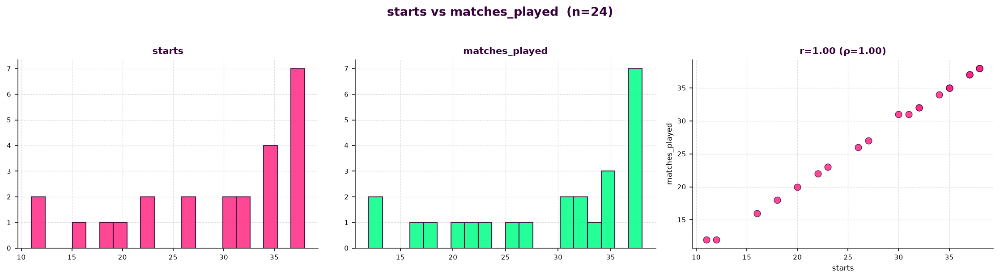

In [124]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[9])

- `mins_played` vs `complete_matches`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9996**), with an almost perfectly linear relationship. Both features primarily capture goalkeeper playing time and therefore provide redundant information.

    **Decision:** Keep `minutes_pct` as the primary playing-time feature; flag both `mins_played` and `complete_matches` for removal during final feature selection.

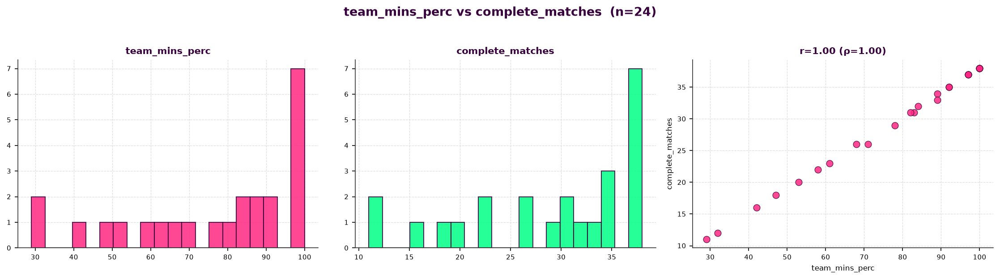

In [125]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[10])

- `starts` vs `matches_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9996**), with nearly identical distributions. `matches_played` provides little additional information beyond `starts` in this goalkeeper dataset.

    **Decision:** Keep `starts` and flag `matches_played` for removal during final feature selection.

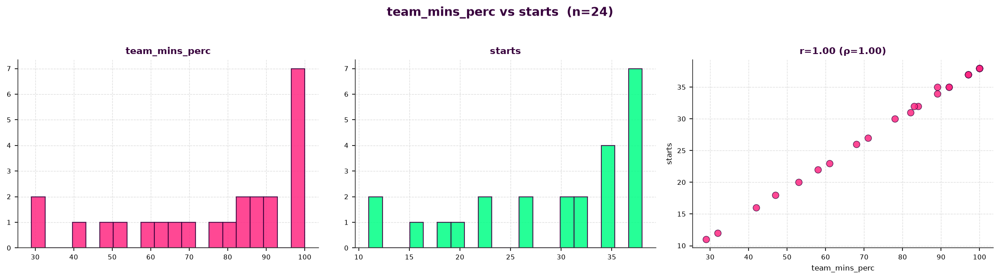

In [126]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[11])

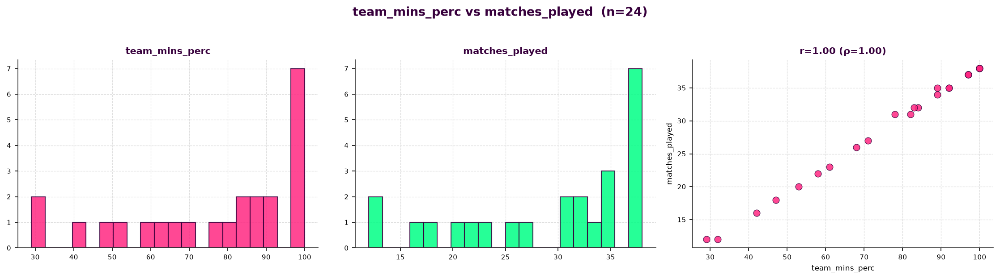

In [127]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[12])

- `team_mins_perc` vs `complete_matches`

    Both Pearson and Spearman correlations are extremely strong (**0.9993**), confirming that these features provide highly redundant information about goalkeeper playing time.

    **Decision:** Both features are already flagged for removal during final feature selection.

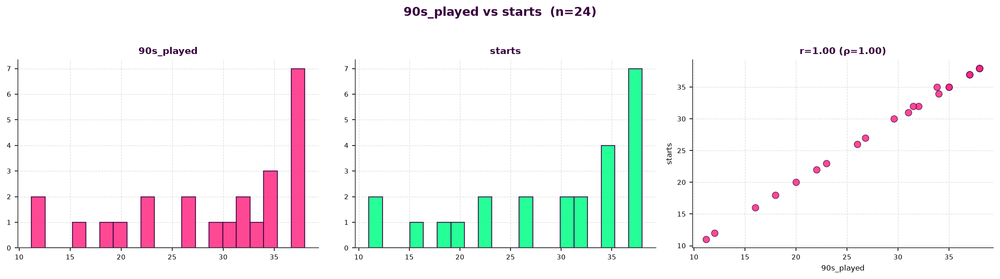

In [128]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[13])

- `sub_appearances` vs `minutes_per_sub`

    Both Pearson and Spearman correlations are extremely strong (**0.9993** and **0.9991**), while both features are overwhelmingly concentrated at zero. Only two goalkeepers recorded substitute appearances, providing very limited variation.

    **Decision:** Flag both features for removal during final feature selection.

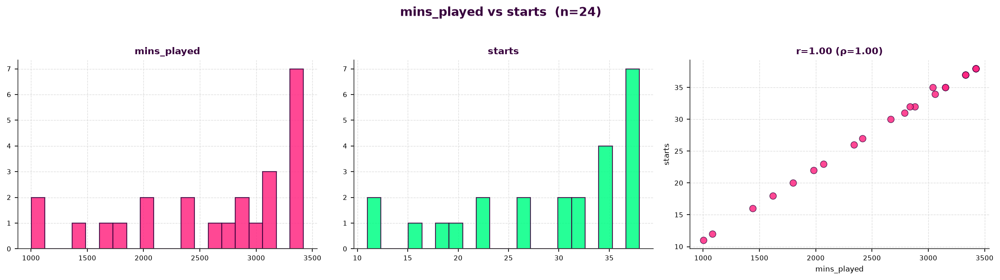

In [129]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[14])

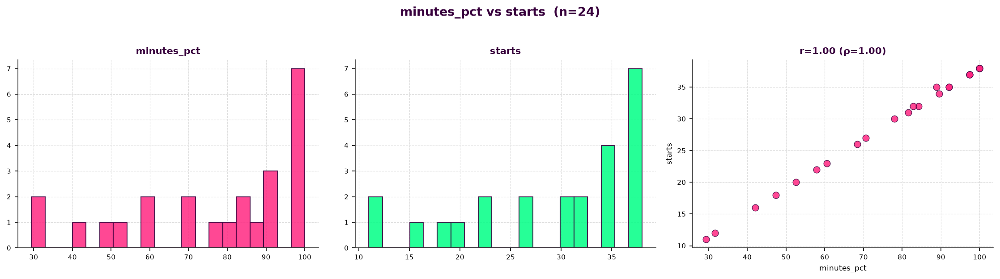

In [130]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[15])

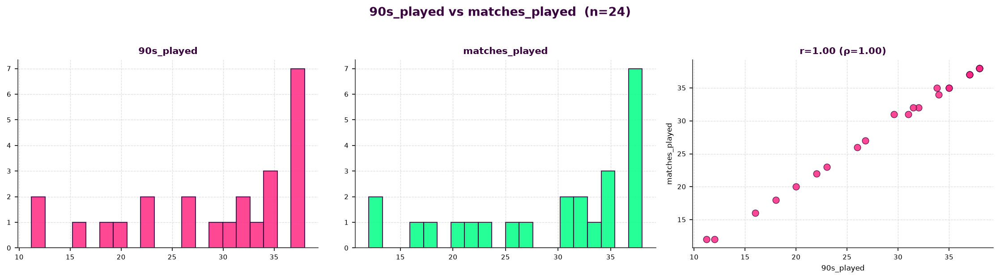

In [131]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[16])

- `90s_played` vs `starts`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9974**), with nearly identical distributions. `90s_played` therefore adds little information beyond `starts` for this dataset.

    **Decision:** Keep `starts`; `90s_played` remains flagged for removal during final feature selection.

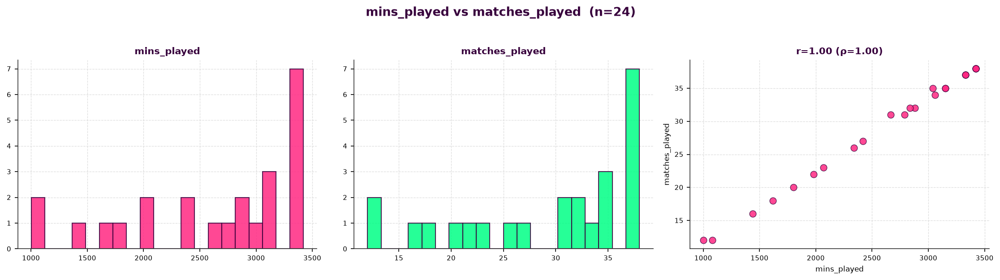

In [132]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[17])

- `minutes_pct` vs `starts`

    Both Pearson and Spearman correlations are extremely strong (**0.9995** and **0.9974**), with the two features showing nearly identical relationships and distributions. `starts` therefore provides little additional information beyond `minutes_pct`.

    **Decision:** Keep `minutes_pct`; `starts` is flagged for removal during final feature selection.

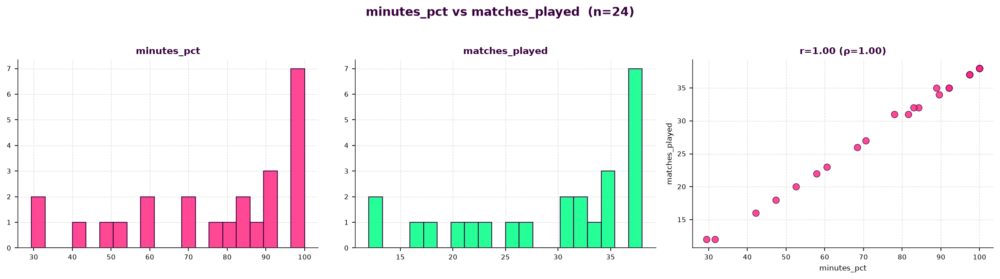

In [133]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[18])

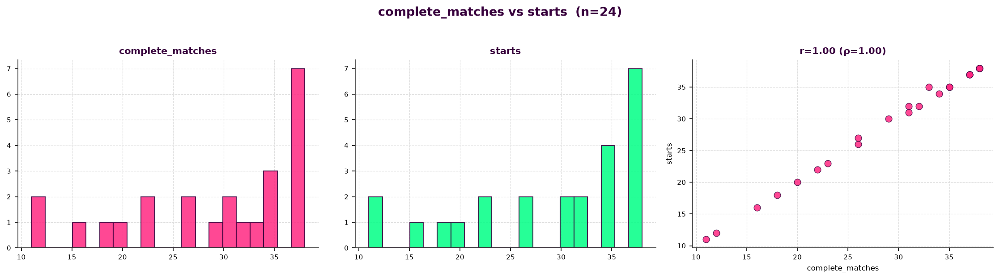

In [134]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[19])

- `90s_played` vs `matches_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9990** and **0.9969**), with nearly identical distributions. `90s_played` therefore provides little additional information beyond `matches_played`.

    **Decision:** Both features remain flagged for removal during final feature selection.

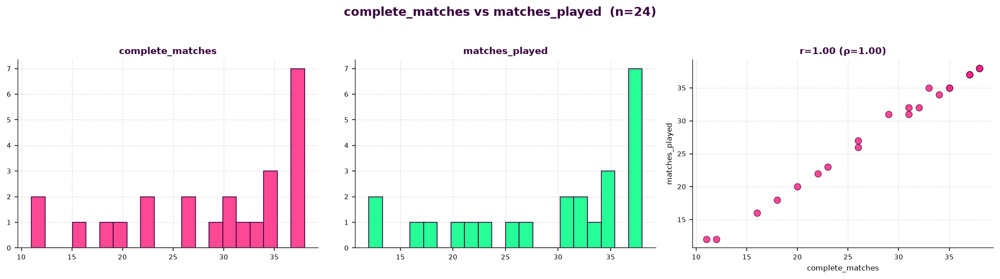

In [135]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[20])

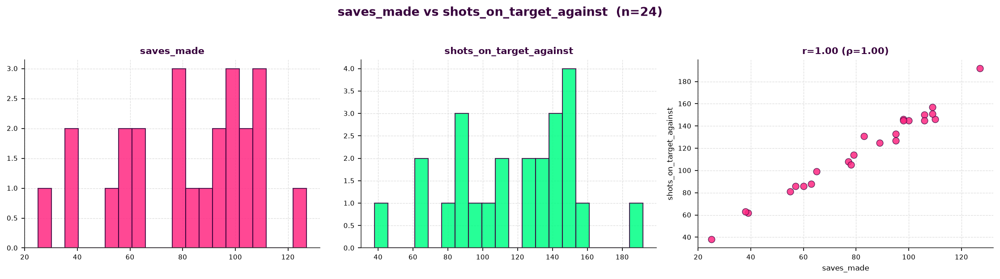

In [136]:
investigate_correlation_pair(df, corr_table, high_redundancy_list[21])

- `minutes_pct` vs `matches_played`

    Both Pearson and Spearman correlations are extremely strong (**0.9990** and **0.9969**), indicating substantial redundancy between the two features.

    **Decision:** Keep `minutes_pct`; `matches_played` is flagged for removal during final feature selection.

- `saves_made` vs `shots_on_target_against`

    Both Pearson and Spearman correlations are extremely strong (**0.9876** and **0.9802**), reflecting the strong relationship between goalkeeper workload and saves made. However, the features represent different concepts: `shots_on_target_against` captures shot-stopping exposure, while `saves_made` captures the resulting defensive outcome.

    **Decision:** Retain both for further analysis; assess their roles separately in workload/exposure and goalkeeper performance analysis.

In [137]:
# Potential redundancy `0.90 <= min(|Pearson|, |Spearman|) < 0.98`
potential_redundancy = corr_table[(corr_table["min_abs_corr"] >= 0.9) & (corr_table["min_abs_corr"] < 0.98)].sort_values(by="min_abs_corr", ascending=False)

In [138]:
potential_redundancy_list = list(potential_redundancy[["feature_1", "feature_2"]].itertuples(index=False, name=None))

In [139]:
len(potential_redundancy_list)

11

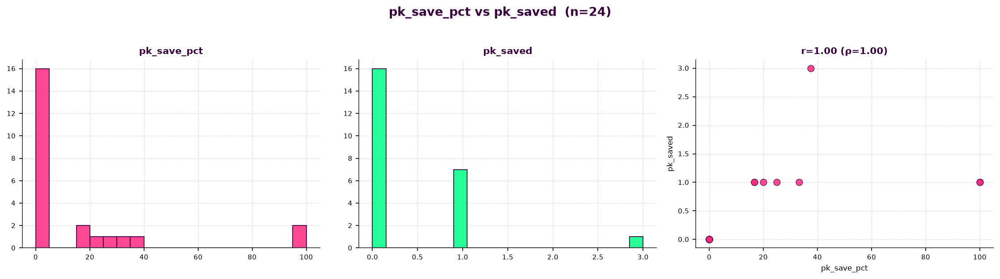

In [140]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[0])

- `pk_save_pct` vs `pk_saved`

    Spearman correlation is very strong (**0.9731**), indicating a strong monotonic relationship. However, the scatter plot shows that the relationship is not linear, which is consistent with the discrete nature of `pk_saved` and the concentration of observations at zero.

    The two features capture different aspects of penalty performance: `pk_saved` measures penalty saves in absolute terms, while `pk_save_pct` measures penalty-saving efficiency. Therefore, the high Spearman correlation alone is not sufficient to classify them as redundant.

    Both features also have limited variation, with most goalkeepers recording no penalty saves.

    **Decision:** Flag for further review during Goalkeeper Performance Analysis rather than removing either feature at this stage.

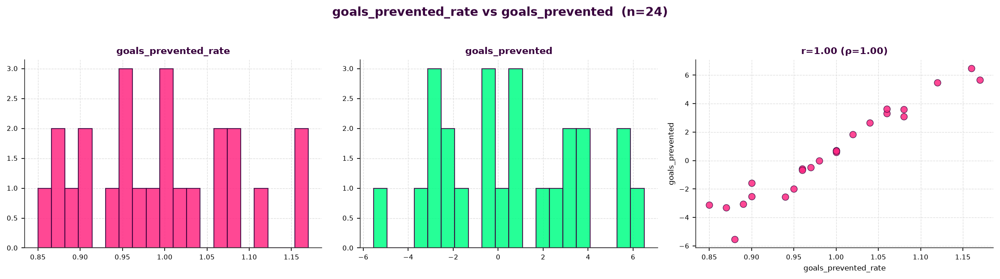

In [141]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[1])

- `goals_prevented_rate` vs `goals_prevented`

    Both Pearson and Spearman correlations indicate a very strong positive relationship (**0.9716** and **0.9839** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong, approximately linear relationship across the observed range. However, the two features capture different aspects of goalkeeper performance: `goals_prevented` represents the overall number of goals prevented, while `goals_prevented_rate` represents the rate/efficiency of goal prevention.

    Therefore, the high correlation indicates substantial overlap but does not by itself establish that one feature should be removed.

    **Decision:** Flag both features for further review during Goalkeeper Performance Analysis and final feature selection. Retain both at this stage.

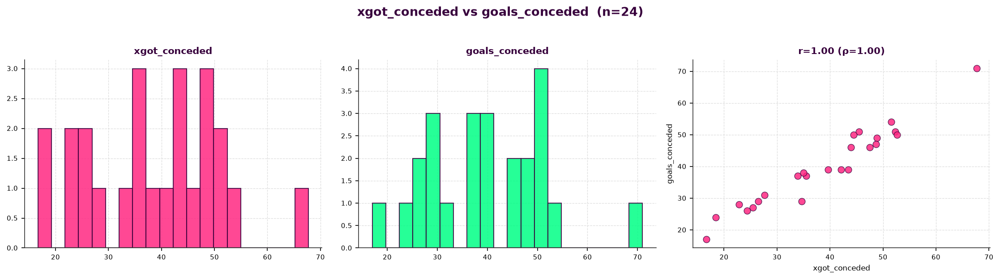

In [142]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[2])

**Expected Goals on Target (xGOT)**

`xgot_conceded` represents the expected number of goals a goalkeeper would be expected to concede based on the quality and execution of the shots on target they faced.

Unlike actual goals conceded, xGOT accounts for the difficulty of the shots faced, making it useful for evaluating goalkeeper performance beyond the quality of the team's defence.

For example, if a goalkeeper concedes fewer goals than their xGOT, they have prevented more goals than expected from the shots they faced.

- `xgot_conceded` vs `goals_conceded`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9680** and **0.9632** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong, approximately linear relationship between expected and actual goals conceded.

    However, the features represent different aspects of goalkeeper performance. `goals_conceded` measures the actual goals conceded, while `xgot_conceded` estimates the goals expected to be conceded based on the quality and execution of shots on target faced.

    The distinction is important because xGOT provides context for evaluating whether a goalkeeper conceded more or fewer goals than would be expected from the shots they faced.

    **Decision:** Flag both features for further review during Goalkeeper Performance Analysis and final feature selection. Retain both at this stage.

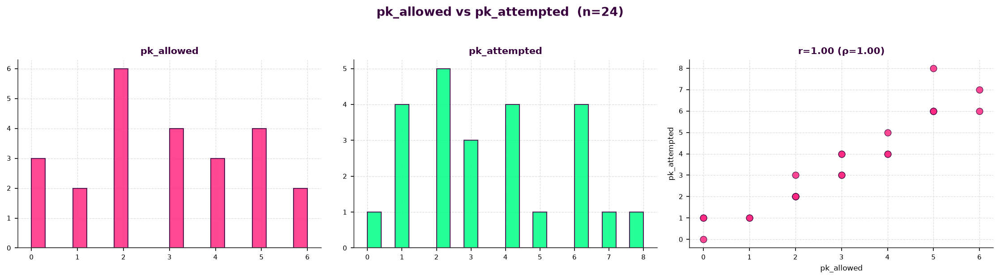

In [143]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[3])

- `xgot_conceded` vs `goals_against`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9690** and **0.9630** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong, approximately linear relationship between the two features. This relationship is expected because `xgot_conceded` reflects the expected goals from shots on target faced, while `goals_against` represents actual goals conceded.

    Despite the strong relationship, the features provide different information: `xgot_conceded` provides expected-goal context for the shots faced, while `goals_against` represents the actual defensive outcome.

    **Decision:** Flag both features for further review during Goalkeeper Performance Analysis and final feature selection. Retain both at this stage.

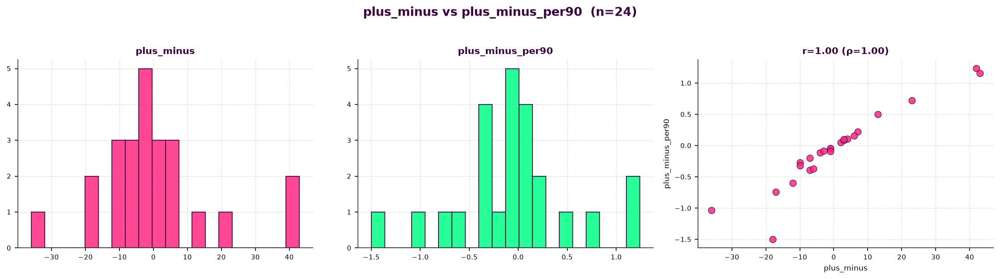

In [144]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[4])

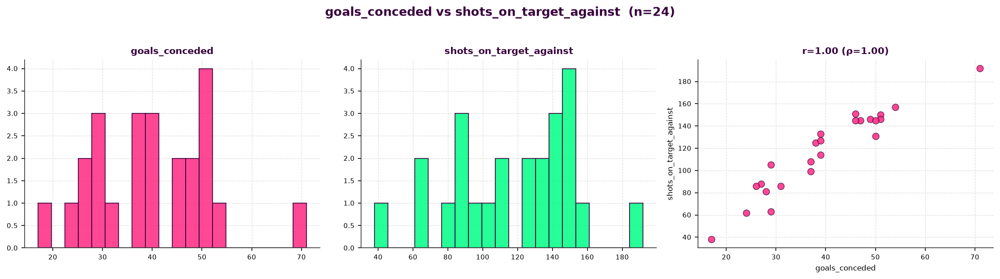

In [145]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[5])

- `pk_allowed` vs `pk_attempted`

    Pearson and Spearman correlations indicate a strong monotonic relationship
    (**0.9503** and **0.9730**, respectively). This is expected because the number
    of penalties conceded is constrained by the number of penalties faced.

    However, the features represent different concepts: `pk_attempted` measures
    penalty-kick exposure, while `pk_allowed` measures the resulting goals
    conceded from those opportunities.

    **Decision:** Flag both features for further review during Goalkeeper
    Performance Analysis and final feature selection. Retain both at this stage.

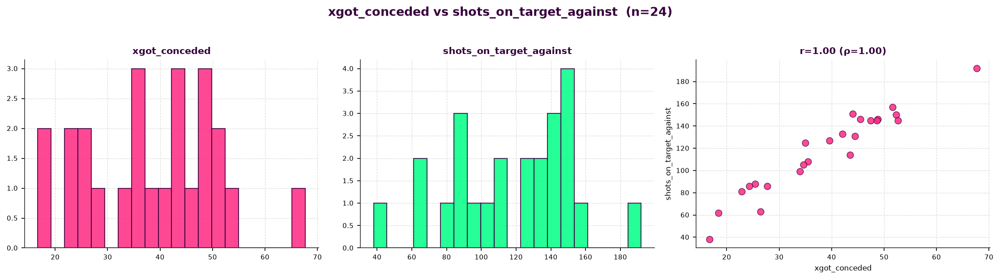

In [146]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[6])

- `assists_per90` vs `assists`

    Pearson and Spearman correlations indicate a strong relationship
    (**0.9483** and **0.9953**, respectively). However, the relationship is
    heavily influenced by the very low number of assists in the goalkeeper
    sample, with most players recording zero assists.

    The two features also capture different aspects of performance:
    `assists` measures total creative output, while `assists_per90`
    normalizes that output for playing time.

    **Decision:** Flag both features for further review during Goalkeeper
    Performance Analysis and final feature selection. Retain both at this stage.

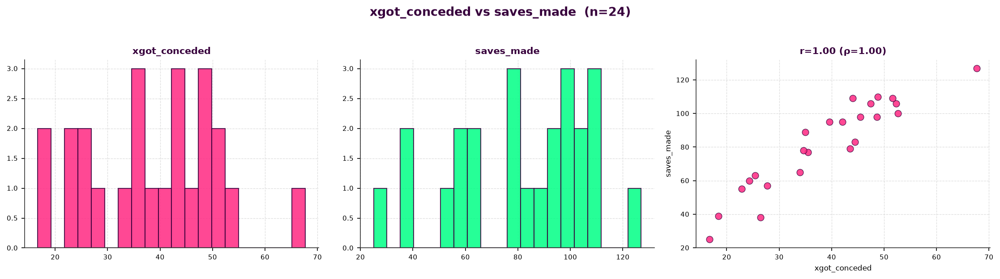

In [147]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[7])

- `assists_per90` vs `goals_assists`

    Pearson and Spearman correlations indicate a strong relationship
    (**0.9483** and **0.9953**, respectively). Both features are also highly
    zero-inflated, with most goalkeepers recording no assists or goal
    contributions.

    `assists_per90` measures creative output relative to playing time, whereas
    `goals_assists` measures total goal contributions. However, because goals
    are rare among goalkeepers, `goals_assists` is largely driven by assists
    in this sample.

    **Decision:** Flag both features for further review during Goalkeeper
    Performance Analysis and final feature selection. Retain both at this stage.

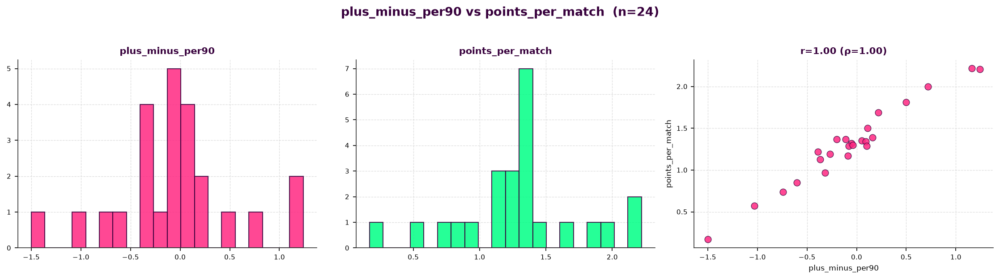

In [148]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[8])

- `plus_minus` vs `plus_minus_per90`

    Pearson and Spearman correlations indicate a strong relationship
    (**0.9429** and **0.9841**, respectively). This relationship is expected
    because `plus_minus_per90` is a playing-time-adjusted version of
    `plus_minus`.

    However, the features capture different aspects of team contribution:
    `plus_minus` measures total goal difference while on the pitch, whereas
    `plus_minus_per90` measures goal difference relative to playing time.

    **Decision:** Flag both features for further review during Team-Context
    Analysis and final feature selection. Retain both at this stage.

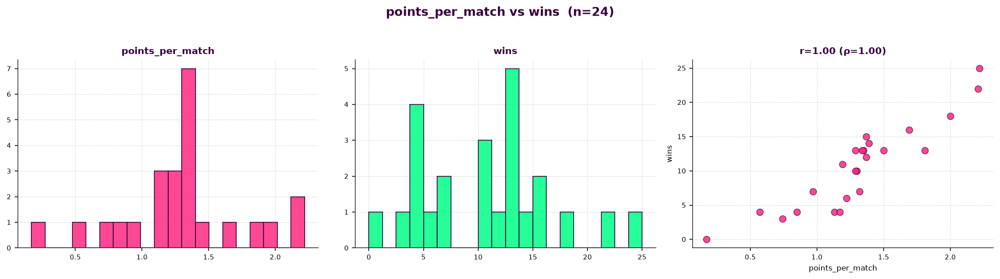

In [149]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[9])

- `goals_conceded` vs `shots_on_target_against`

    Pearson and Spearman correlations indicate a strong positive relationship
    (**0.9507** and **0.9389**, respectively). The scatterplot also shows a
    clear monotonic relationship.

    However, the features represent different concepts. `shots_on_target_against`
    measures goalkeeper workload/exposure, while `goals_conceded` measures the
    resulting defensive outcome.

    The strong relationship is therefore expected rather than evidence of
    feature duplication.

    **Decision:** Retain both features. Flag the relationship for consideration
    during Goalkeeper Performance Analysis and final feature selection.

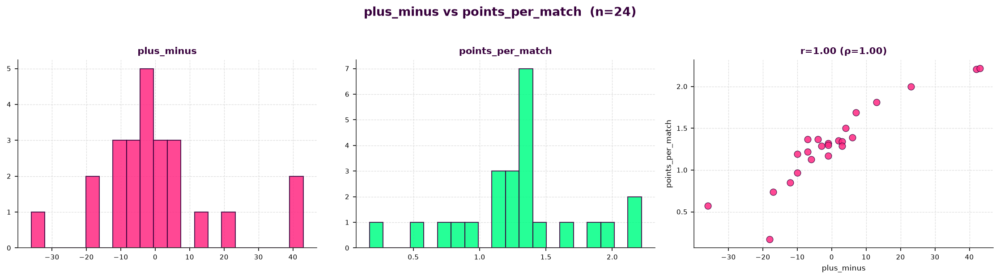

In [150]:
investigate_correlation_pair(df, corr_table, potential_redundancy_list[10])

- `shots_on_target_against` vs `goals_against`

    **Pearson correlation:** 0.9515  
    **Spearman correlation:** 0.9380  
    **Difference:** 0.0135  

    The strong positive correlation is expected, as goalkeepers who face more shots on target generally have more opportunities to concede goals.

    Although the two features are strongly related, they represent different concepts:

    - `shots_on_target_against` → goalkeeper workload/exposure
    - `goals_against` → defensive outcome

    Therefore, the high correlation does not indicate direct redundancy between the two features.

    **Decision:** Retain both features. Flag the relationship for further review during Goalkeeper Performance Analysis and final feature selection.

- `xgot_conceded` vs `shots_on_target_against`

  **Pearson correlation:** **0.9616**

  **Spearman correlation:** **0.9377**

  **Difference:** **0.0239**

  The scatterplot shows a strong positive relationship: goalkeepers who face more shots on target generally have higher `xgot_conceded`.

  However, this relationship is **expected rather than evidence of redundancy**. `shots_on_target_against` represents the volume of shots faced, while `xgot_conceded` represents the expected goals from those shots based on their quality.

  This is actually an important relationship for goalkeeper analysis because it connects **workload/exposure** with **quality-adjusted expected goals conceded**.

  **Decision:** Retain both features. Flag the relationship for further review during Goalkeeper Performance Analysis and final feature selection.


- `goals_scored_on_pitch` vs `wins`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9362** and **0.9341** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong, approximately linear relationship between the two features. This relationship is expected because `goals_scored_on_pitch` reflects attacking/team output, while `wins` represents match outcome and team success.

    Despite the strong relationship, the features provide different information: `goals_scored_on_pitch` captures the team's scoring contribution, while `wins` captures the team's success in terms of match outcomes.

    **Decision:** Flag both features for further review during Team-Context Analysis and final feature selection. Retain both at this stage.

- `xgot_conceded` vs `saves_made`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9340** and **0.9265** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong, approximately linear relationship between the two features. This relationship is expected because goalkeepers who face more and/or higher-quality shots on target generally have more opportunities to make saves.

    Despite the strong relationship, the features provide different information: `xgot_conceded` captures the expected goal quality of shots on target faced, while `saves_made` represents the actual number of shots stopped by the goalkeeper.

    **Decision:** Flag both features for further review during Goalkeeper Performance Analysis and final feature selection. Retain both at this stage.

- `plus_minus_per90` vs `points_per_match`

    Pearson and Spearman correlations indicate a strong positive relationship (**0.9802** and **0.9169** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a strong positive relationship between the two features, although the relationship is not perfectly consistent across the full range of values. The relatively larger difference between Pearson and Spearman correlation suggests that the relationship may be influenced by the distribution of the observations.

    Both features capture aspects of team success, but from different perspectives: `plus_minus_per90` reflects goal difference while the player is on the pitch, while `points_per_match` reflects the team's overall match results.

    Because both features describe closely related aspects of team performance, their potential redundancy should be reviewed during Team-Context Analysis and final feature selection.

    **Decision:** Flag both features for further review during Team-Context Analysis and final feature selection. Retain both at this stage.

- `points_per_match` vs `wins`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9090** and **0.9271** respectively), placing the pair within the potential redundancy range.

    The scatter plot shows a clear positive relationship between the two features: players whose teams earn more points per match generally also have more wins.

    However, the features capture different aspects of team success. `points_per_match` accounts for both wins and draws, while `wins` captures only the number of victories. Therefore, the relationship is expected, but the features are not exact duplicates.

    **Decision:** Flag both features for further review during Team-Context Analysis and final feature selection. Retain both at this stage.

- `plus_minus` vs `points_per_match`

    Both Pearson and Spearman correlations indicate a strong positive relationship (**0.9150** and **0.9022** respectively), placing the pair within the potential redundancy range.

    The relationship is expected because both features reflect team performance and overall results. `plus_minus` captures the difference between goals scored and conceded, while `points_per_match` measures the average points earned per match.

    Despite the strong relationship, the features provide different information: `plus_minus` reflects goal difference, while `points_per_match` reflects results through points accumulated from wins and draws.

    **Decision:** Flag both features for further review during Team-Context Analysis and final feature selection. Retain both at this stage.

In [151]:
# moderate_redundancy - 0.70 ≤ min(|Pearson|, |Spearman|) < 0.90
moderate_redundancy = corr_table[(corr_table["min_abs_corr"] >= 0.7) & (corr_table["min_abs_corr"] < 0.9)]
moderate_redundancy

,feature_1,feature_2,correlation_pearson,correlation_spearman,relationship_type,min_abs_corr
2,clean_sheet_pct,clean_sheets,0.912556,0.858715,both,0.858715
3,clean_sheet_pct,goals_against_per90,-0.826766,NaN,pearson,0.826766
4,clean_sheet_pct,wins,0.795562,NaN,pearson,0.795562
5,clean_sheets,90s_played,0.778738,0.836406,both,0.778738
6,clean_sheets,goals_against_per90,-0.840145,NaN,pearson,0.840145
...,...,...,...,...,...,...
99,xgot_conceded,matches_played,0.788886,0.793631,both,0.788886
100,xgot_conceded,mins_played,0.787676,0.786918,both,0.786918
101,xgot_conceded,minutes_pct,0.787488,0.786918,both,0.786918
104,xgot_conceded,starts,0.789724,0.795466,both,0.789724


##### Redundancy Analysis - Provisional Removal List

The following features were identified as redundant based on the correlation
and conceptual redundancy analysis conducted at this stage. These decisions
are provisional and may be revisited during subsequent exposure, workload,
team-context, and goalkeeper performance analyses.

**High-confidence redundancy `min(|Pearson|, |Spearman|) ≥ 0.98`:**

1. `goals_assits`
2. `mins_played`
3. `90s_played`
4. `team_mins_perc`
5. `complete_matches`
6. `sub_appearances`
7. `minutes_per_sub`
8. `starts`
9.  `matches_played`




In [152]:
redundancy_removal_candidates = [
    "goals_assists",
    "mins_played",
    "90s_played",
    "team_mins_perc",
    "complete_matches",
    "sub_appearances",
    "minutes_per_sub",
    "starts",
    "matches_played",
]

In [153]:
moderate_redundancy_list = list(moderate_redundancy[["feature_1", "feature_2"]].itertuples(index=False, name=None))

In [154]:
moderate_redundancy_active = [
    pair for pair in moderate_redundancy_list
    if pair[0] not in redundancy_removal_candidates
    and pair[1] not in redundancy_removal_candidates
]

In [155]:
len(moderate_redundancy_active)

31

In [156]:
pd.DataFrame(moderate_redundancy_active, columns=["feature_1", "feature_2"])

,feature_1,feature_2
0,clean_sheet_pct,clean_sheets
1,clean_sheet_pct,goals_against_per90
2,clean_sheet_pct,wins
3,clean_sheets,goals_against_per90
4,clean_sheets,wins
5,goals_conceded,losses
6,goals_conceded,minutes_pct
7,losses,shots_on_target_against
8,minutes_pct,clean_sheets
9,minutes_pct,draws


##### Relationship & Redundancy Analysis - Conclusion

The relationship analysis was conducted to identify features that may provide overlapping information and potentially lead to double-counting within the POTSI framework.

Highly correlated feature pairs were investigated using correlation measures, distribution plots, scatter plots, descriptive statistics, and domain-level reasoning. Potentially redundant features were subsequently reviewed based on their conceptual similarity and role within the analysis.

Moderately correlated pairs were screened for obvious conceptual overlap rather than being investigated systematically. No additional pairs were identified as sufficiently redundant to warrant removal based on this screening.

##### Current Feature Removal Decisions

**High redundancy removal candidates:**
- `goals_assits`
- `mins_played`
- `90s_played`
- `team_mins_perc`
- `complete_matches`
- `sub_appearances`
- `minutes_per_sub`
- `starts`
- `matches_played`


These decisions are provisional and may be revisited after subsequent analyses, particularly when considering feature distributions, domain relevance, position-specific behaviour, and the final POTSI scoring structure.

Overall, the relationship analysis indicates that the remaining features provide sufficiently distinct information to proceed to the next stage of feature evaluation.

#### 3.3 Playing-Time Influence Analysis

**Athelete exposure** refers to the amount of time or or oppurtunity an athlete is exposed to the possibility of an event occuring.

In football analytics, counting statistics should be interpreted in relation to the amount of playing time or opportunity available to the player. This analysis examines how strongly playing time influences observed performance statistics and whether rate-based metrics provide a more appropriate representation of performance.

**Goal:** Understand how much **playing time or opportunity** influences raw statistics.

In [157]:
df.columns.tolist()

['Player',
 'matches_played',
 'starts',
 '90s_played',
 'goals_against_per90',
 'shots_on_target_against',
 'wins',
 'draws',
 'losses',
 'clean_sheets',
 'clean_sheet_pct',
 'pk_attempted',
 'pk_allowed',
 'pk_saved',
 'pk_missed',
 'pk_save_pct',
 'yellow_cards',
 'red_cards',
 'fouls_drawn',
 'points_per_match',
 'plus_minus_per90',
 'minutes_per_start',
 'plus_minus',
 'minutes_pct',
 'complete_matches',
 'plus_minus_net_per90',
 'minutes_per_match',
 'mins_played',
 'team_mins_perc',
 'goals_conceded',
 'saves_made',
 'save_perc',
 'goals_prevented',
 'goals_prevented_rate',
 'xgot_conceded']

- **Exposure features** - variables describing how much playing opportunity or participation the player had.

- **Playing-time pattern features** - variables describing how the player's playing time was distributed or used, such as minutes per appearance, substitute involvement, and complete-match participation.


- **Raw count features** - absolute counts or events accumulated.

- **Rate features** - metrics normalized by playing time, matches, or expressed as percentages.

In [158]:
df.head()

,Player,matches_played,starts,90s_played,goals_against_per90,shots_on_target_against,wins,draws,losses,clean_sheets,...,plus_minus_net_per90,minutes_per_match,mins_played,team_mins_perc,goals_conceded,saves_made,save_perc,goals_prevented,goals_prevented_rate,xgot_conceded
0,Alisson Becker,26,26.0,26.0,1.19,86.0,13.0,8.0,5.0,8.0,...,0.75,90.0,2340,68,31,57,64.77,-3.31,0.87,27.69
1,Alphonse Areola,20,20.0,20.0,1.85,108.0,4.0,5.0,11.0,0.0,...,-0.21,90.0,1800,53,37,77,67.54,-0.49,0.97,35.51
7,Karl Darlow,22,22.0,22.0,1.23,88.0,7.0,8.0,7.0,5.0,...,0.33,90.0,1980,58,27,63,70.00,-0.58,0.96,25.42
8,Gianluigi Donnarumma,34,34.0,34.0,0.85,105.0,22.0,9.0,3.0,15.0,...,1.24,90.0,3060,89,29,78,72.90,5.66,1.17,34.66
9,Martin Dubravka,35,35.0,35.0,2.03,192.0,4.0,8.0,23.0,4.0,...,-0.70,90.0,3150,92,71,127,64.14,0.71,1.00,67.71


In [159]:
exposure_features = [
    "matches_played",
    "starts",
    "90s_played",
    "mins_played",
    "minutes_pct",
    "team_mins_perc",
]

playing_time_pattern_features = [
    "minutes_per_start",
    "minutes_per_sub",
    "minutes_per_match",
    "unused_sub",
    "complete_matches",
    "sub_appearances",
]

raw_count_features = [
    "shots_on_target_against",
    "wins",
    "draws",
    "losses",
    "clean_sheets",
    "pk_attempted",
    "pk_allowed",
    "pk_saved",
    "pk_missed",
    "yellow_cards",
    "red_cards",
    "fouls_drawn",
    "plus_minus",
    "goals_conceded",
    "saves_made",
    "goals_prevented",
    "xgot_conceded",
]

rate_features = [
    "goals_against_per90",
    "clean_sheet_pct",
    "pk_save_pct",
    "assists_per90",
    "points_per_match",
    "plus_minus_per90",
    "save_perc",
    "goals_prevented_rate",
    "plus_minus_net_per90"
]

**Exposure vs Raw Counts**

In [160]:
exposure_performance_corr = df[exposure_features + raw_count_features].corr(method="pearson").loc[exposure_features, raw_count_features]

exposure_performance_corr = exposure_performance_corr.dropna(
    axis=1,
    how="all"
)


In [161]:
exposure_performance_corr

,shots_on_target_against,wins,draws,losses,clean_sheets,pk_attempted,pk_allowed,pk_saved,pk_missed,yellow_cards,red_cards,fouls_drawn,plus_minus,goals_conceded,saves_made,goals_prevented,xgot_conceded
matches_played,0.831551,0.712043,0.740534,0.375877,0.776071,0.329650,0.206843,0.439342,0.074426,0.462369,0.139601,0.448105,0.293505,0.717182,0.849161,0.457415,0.788886
starts,0.833190,0.711263,0.739642,0.378426,0.776901,0.324048,0.201718,0.434008,0.077404,0.458646,0.140307,0.450819,0.290450,0.719966,0.849232,0.448000,0.789724
90s_played,0.829988,0.710599,0.744086,0.375178,0.778738,0.331957,0.209319,0.436558,0.081785,0.458985,0.113872,0.438433,0.290192,0.719514,0.846199,0.443675,0.787684
mins_played,0.830250,0.710488,0.744064,0.375351,0.778697,0.331825,0.209193,0.436516,0.081704,0.458726,0.113521,0.438132,0.290068,0.719602,0.846512,0.443352,0.787676
minutes_pct,0.829988,0.710651,0.744048,0.375134,0.778966,0.331806,0.209067,0.436910,0.081437,0.458912,0.113327,0.438114,0.290318,0.719363,0.846285,0.443595,0.787488
team_mins_perc,0.833541,0.706088,0.744157,0.381024,0.774404,0.332004,0.210087,0.433658,0.084067,0.456304,0.114971,0.437474,0.284474,0.723178,0.849211,0.440224,0.790266


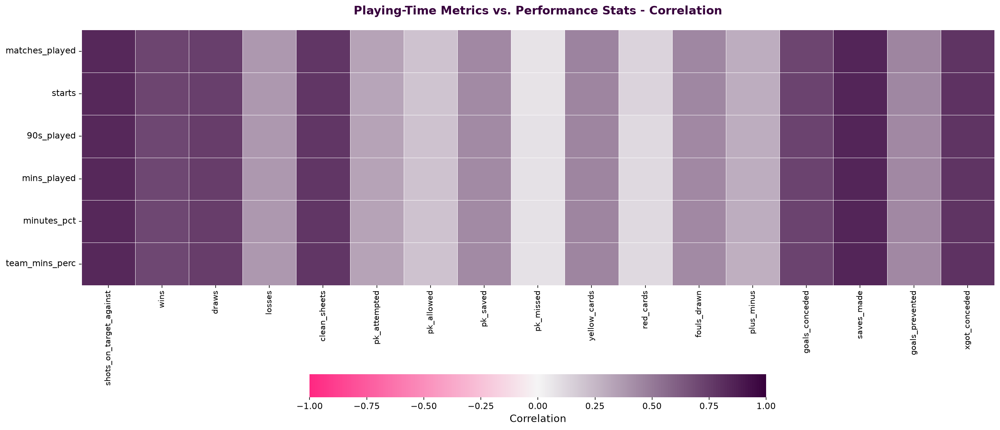

In [162]:
fig, ax = plt.subplots(figsize=(18, 8))

sns.heatmap(
    exposure_performance_corr,
    cmap=PL_DIVERGING,
    center=0,
    vmin=-1, vmax=1,            
    annot=False,
    linewidths=0.4,
    linecolor="white",
    square=False,
    cbar_kws={
        "orientation": "horizontal",
        "shrink": 0.5,
        "pad": 0.22,
        "label": "Correlation"
    },
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=11)


style_plot(
    ax=ax,
    title="Playing-Time Metrics vs. Performance Stats - Correlation", 
)

plt.tight_layout()
plt.show()

In [163]:
exposure_raw = exposure_performance_corr.stack().reset_index()
exposure_raw.columns = ["exposure_features", "raw_count_features", "correlation"]

In [164]:
exposure_raw["abs_correlation"] = exposure_raw["correlation"].abs()

exposure_raw = exposure_raw.sort_values(by="abs_correlation", ascending=False)

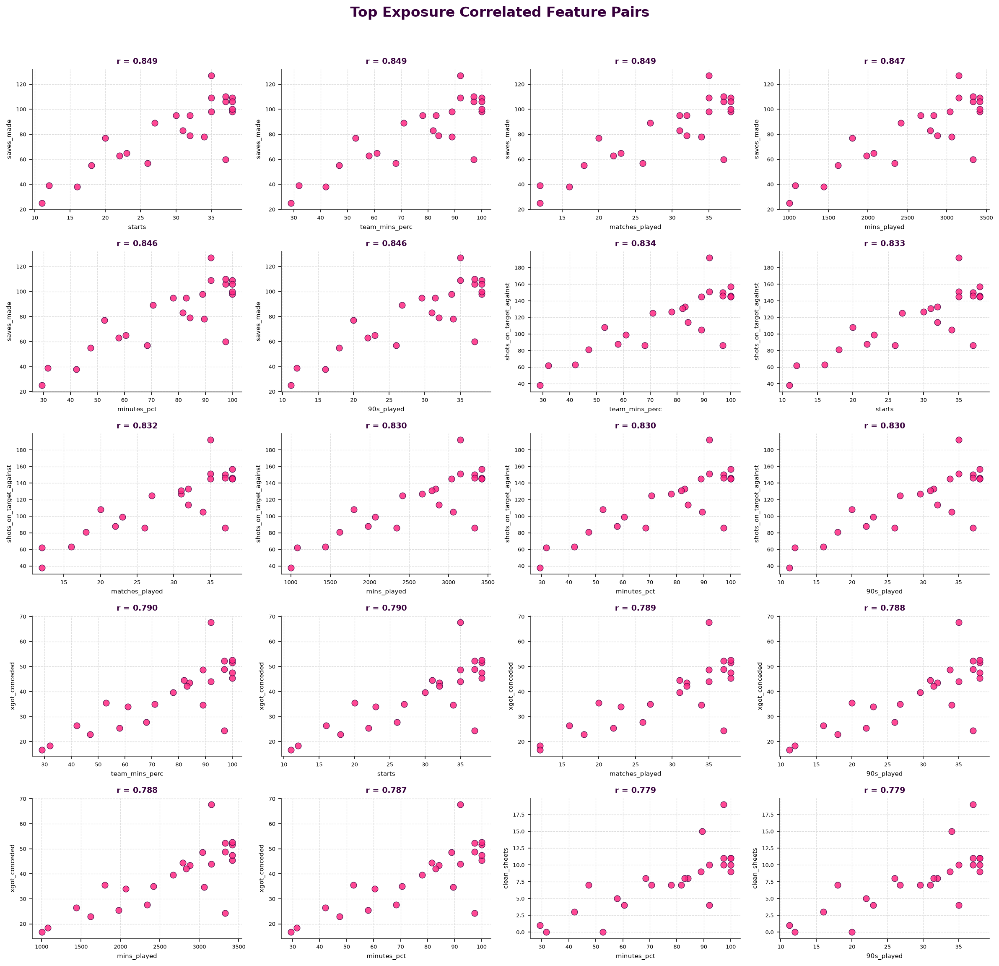

In [165]:
top_exposure_corr = exposure_raw.head(20).copy()

n_pairs = len(top_exposure_corr)
n_cols = 4
n_rows = int(np.ceil(n_pairs / n_cols))

subplot_size_width = 4
subplot_size_height = 3

fig, axes = plt.subplots(
    n_rows, 
    n_cols,
    figsize=(subplot_size_width * n_cols, subplot_size_height * n_rows)
)

axes = axes.flatten()

for i, (_, row) in enumerate(top_exposure_corr.iterrows()):
    x_feat = row["exposure_features"]
    y_feat = row["raw_count_features"]
    r_val = row["correlation"]
    ax = axes[i]

    ax.scatter(
        df[x_feat],
        df[y_feat],
        color=ACCENT,
        edgecolor=PRIMARY,
        linewidth=0.6,
        s=50,
        alpha=0.85,
    )

    ax.set_title(f"r = {r_val:.3f}", fontsize=9, color=PRIMARY, fontweight="bold")
    ax.set_xlabel(x_feat, fontsize=7)
    ax.set_ylabel(y_feat, fontsize=7)
    ax.tick_params(labelsize=6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Top Exposure Correlated Feature Pairs", fontsize=16, fontweight="bold", color=PRIMARY, y=1.02)
plt.tight_layout()
plt.show()

##### Findings

- Raw volume statistics such as `saves_made`, `shots_on_target_against`, and `goals_scored_on_pitch` show strong positive relationships with playing-time exposure measures.

- The strongest relationships are concentrated among metrics that naturally accumulate with greater playing time, indicating that raw totals are substantially influenced by player exposure.

- Because exposure can inflate raw totals, volume-based metrics should be interpreted alongside rate-based or exposure-adjusted metrics when evaluating player performance.

**POTSI Implication:** Raw counts can capture total contribution and should not automatically be discarded, but rate-based metrics should be considered where differences in playing time could substantially affect player comparisons.

**Raw Count vs Rate Metrics**

In [166]:
raw_rate_pairs = [
    ("goals_conceded", "goals_against_per90"),
    ("plus_minus", "plus_minus_per90"),
    ("goals_prevented", "goals_prevented_rate"),
    ("saves_made", "save_perc"),
    ("clean_sheets", "clean_sheet_pct"),
    ("pk_saved", "pk_save_pct"),
]

raw_rate_list = [col for feat in raw_rate_pairs for col in feat]
raw_col = [col[0] for col in raw_rate_pairs]
rate_col = [col[0] for col in raw_rate_pairs]

In [167]:
df[raw_rate_list].describe()

,goals_conceded,goals_against_per90,plus_minus,plus_minus_per90,goals_prevented,goals_prevented_rate,saves_made,save_perc,clean_sheets,clean_sheet_pct,pk_saved,pk_save_pct
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,39.791667,1.412917,0.541667,-0.060000,0.515417,0.993333,81.708333,66.756667,7.666667,24.383333,0.416667,14.550000
std,12.233166,0.312486,17.247506,0.605245,3.214202,0.090008,26.550164,3.894741,4.449393,11.705728,0.717282,28.754629
min,17.000000,0.700000,-36.000000,-1.500000,-5.540000,0.850000,25.000000,56.720000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,1.237500,-7.750000,-0.332500,-2.127500,0.930000,62.250000,64.612500,4.750000,21.650000,0.000000,0.000000
50%,39.000000,1.360000,-1.000000,-0.065000,0.295000,0.990000,86.000000,67.235000,8.000000,25.350000,0.000000,0.000000
75%,49.250000,1.572500,4.500000,0.122500,3.152500,1.060000,101.500000,69.827500,10.000000,28.900000,1.000000,17.525000
max,71.000000,2.030000,43.000000,1.240000,6.490000,1.170000,127.000000,72.900000,19.000000,51.400000,3.000000,100.000000


In [168]:
raw_rate_corr = {}

for raw, rate in raw_rate_pairs:
    raw_rate_corr[f"{raw} vs {rate}"] = float(df[[raw, rate]].corr().round(2).iloc[0, 1])

raw_rate_corr

{'goals_conceded vs goals_against_per90': 0.2,
 'plus_minus vs plus_minus_per90': 0.94,
 'goals_prevented vs goals_prevented_rate': 0.97,
 'saves_made vs save_perc': 0.54,
 'clean_sheets vs clean_sheet_pct': 0.91,
 'pk_saved vs pk_save_pct': 0.59}

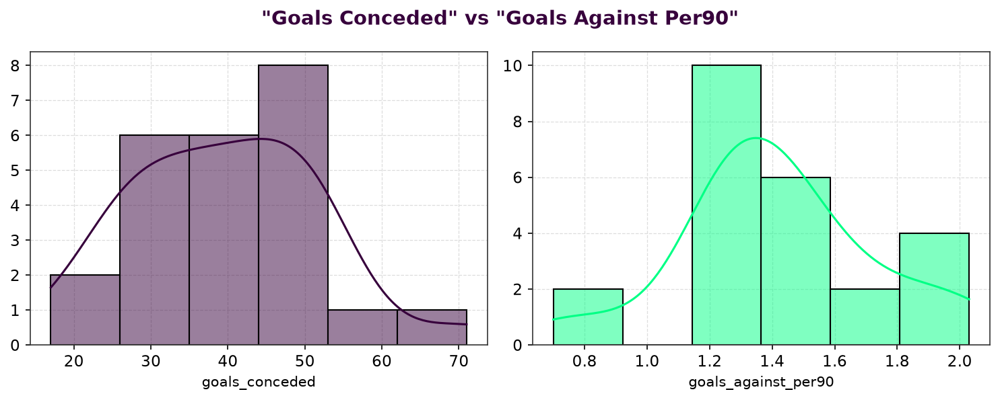

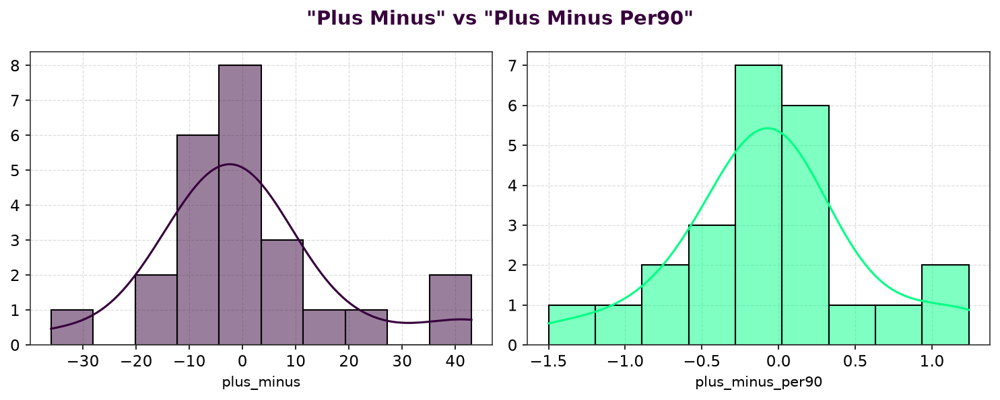

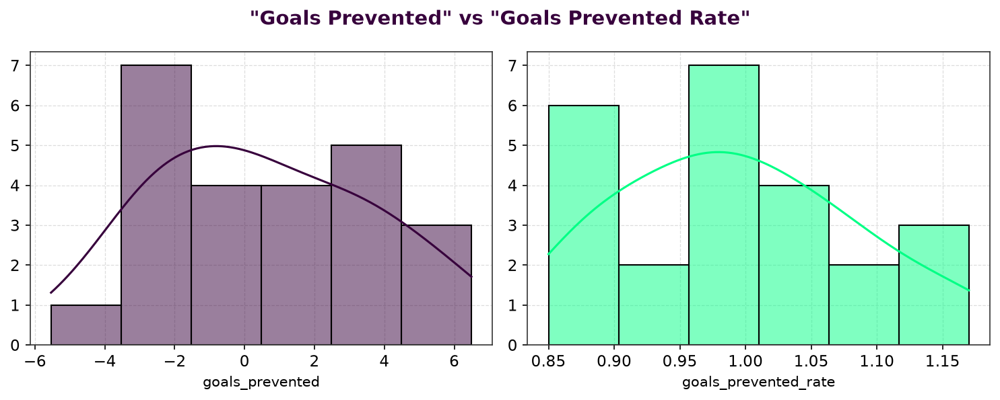

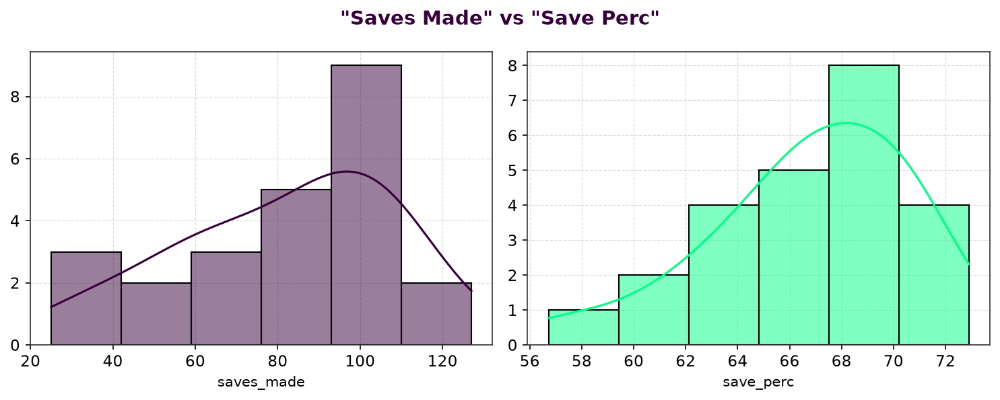

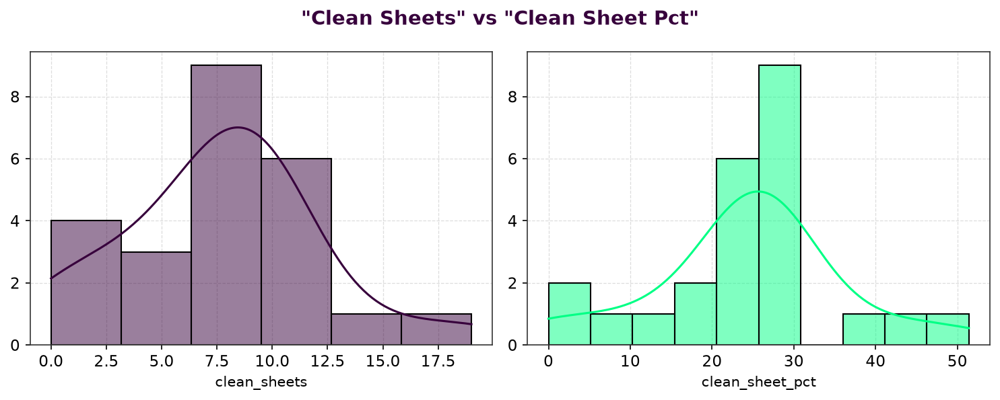

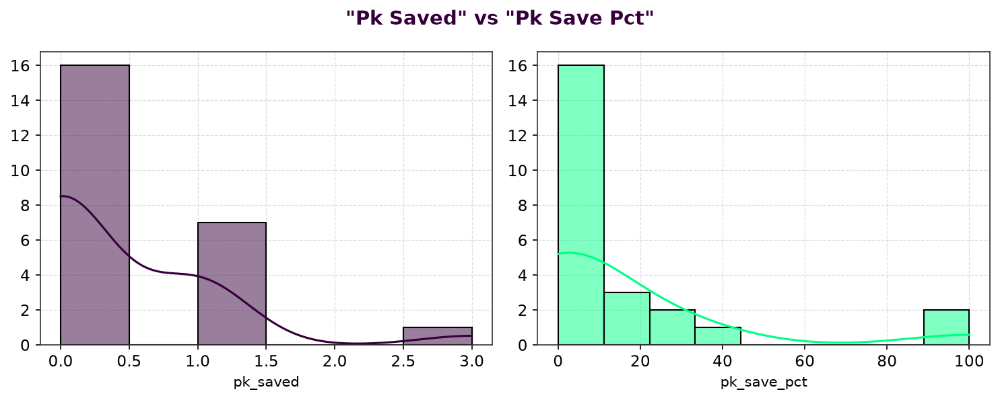

In [169]:
for raw_feature, rate_feature in raw_rate_pairs:
    raw_title = raw_feature.replace("_", " ").title()
    rate_title = rate_feature.replace("_", " ").title()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.histplot(df[raw_feature], kde=True, ax=axes[0], color=PRIMARY)
    axes[0].set_xlabel(raw_feature, fontsize=10)

    sns.histplot(df[rate_feature], kde=True, ax=axes[1], color=SECONDARY)
    axes[1].set_xlabel(rate_feature, fontsize=10)

    for ax in axes:
        ax.set_ylabel("")

    plt.suptitle(f"\"{raw_title}\" vs \"{rate_title}\"", fontsize=14, fontweight="bold", color=PRIMARY)
    plt.tight_layout()
    plt.show()

##### Findings

The distributions highlight the distinction between raw volume and normalized performance metrics. Raw count features represent accumulated events and are therefore more strongly influenced by playing time and opportunity, while rate-based and percentage metrics express performance on a normalized or efficiency basis.

The differences are particularly evident for metrics such as `goals_against` vs `goals_against_per90`, `saves_made` vs `save_perc`, and `clean_sheets` vs `clean_sheet_pct`, where the normalized metrics provide a different perspective from the underlying volume counts.

**POTSI Implication:** Raw counts can capture total contribution, but rate-based and percentage metrics should be considered alongside them when comparing players with different levels of playing exposure.

##### Exposure Analysis Findings

The exposure analysis shows that several major raw counting statistics have strong positive relationships with playing opportunity. `saves_made` shows the strongest relationship, with correlations of approximately **0.846–0.849** across the six exposure measures. `shots_on_target_against` (**0.830–0.834**) and `goals_scored_on_pitch` (**0.827–0.832**) also show strong relationships with exposure.

Other important volume statistics, including `xgot_conceded` (**0.788–0.790**), `clean_sheets` (**0.774–0.779**), `draws` (**0.740–0.744**), and `goals_against` (**0.718–0.724**), also show substantial positive relationships with playing opportunity.

The six exposure measures — `matches_played`, `starts`, `90s_played`, `mins_played`, `minutes_pct`, and `team_mins_perc` — produce very similar correlation patterns across the raw performance statistics. This indicates that they are largely capturing the same underlying concept of player exposure, although they express it in different forms.

Overall, the results demonstrate that several important raw performance statistics are strongly influenced by playing opportunity. Higher raw totals therefore cannot always be interpreted as evidence of superior individual performance in isolation.

##### POTSI Implication - Volume vs Rate Interpretation

The strong exposure relationships indicate that raw volume statistics should not be interpreted as pure measures of individual performance. A player who accumulates more saves, clean sheets, or other events may partly benefit from having greater playing exposure and opportunity to accumulate those events.

Raw counting statistics should therefore not automatically be removed from POTSI, as they can capture total contribution over the season. However, they should be interpreted alongside appropriate rate or efficiency metrics when comparing players with different levels of playing exposure.

**POTSI Implication:** Exposure-dependent volume metrics should be used to capture total contribution, while rate-based and percentage metrics can provide an exposure-adjusted perspective and improve comparability between players with different playing time.

#### 3.4 Workload Analysis

**Objective:** Understand how **opportunity/workload** affects goalkeeper performance metrics.

**Definitons:**

- **Workload / Exposure / Opportunity Variables** - These metrics describes either how much the goalkeeper played or how much opportunity they faced while playing. 

- **OUtcome / Performance Variables** - These metrics represents the result, actions or effectiveness of the goalkeeper's performance.

In [170]:
workload_exposure_features = [
    # Playing exposure
    "matches_played",
    "starts",
    "90s_played",
    "minutes_per_start",
    "minutes_pct",
    "complete_matches",
    "minutes_per_match",
    "mins_played",
    "team_mins_perc",

    # Defensive workload / opportunity
    "shots_on_target_against",
    "pk_attempted",
]

outcome_performance_features = [
    "goals_against_per90",
    "clean_sheets",
    "clean_sheet_pct",
    "pk_allowed",
    "pk_saved",
    "pk_missed",
    "pk_save_pct",
    "goals_conceded",
    "saves_made",
    "save_perc",
    "goals_prevented",
    "goals_prevented_rate",
    "xgot_conceded",

    # Goalkeeper involvement / actions
    "fouls_drawn",
]

In [171]:
workload_outcome_corr = (
    df[workload_exposure_features + outcome_performance_features]
    .corr()
    .loc[workload_exposure_features, outcome_performance_features]
)

In [172]:
workload_outcome_corr

,goals_against_per90,clean_sheets,clean_sheet_pct,pk_allowed,pk_saved,pk_missed,pk_save_pct,goals_conceded,saves_made,save_perc,goals_prevented,goals_prevented_rate,xgot_conceded,fouls_drawn
matches_played,-0.516947,0.776071,0.542118,0.206843,0.439342,0.074426,0.302950,0.717182,0.849161,0.582241,0.457415,0.525918,0.788886,0.448105
starts,-0.512257,0.776901,0.543928,0.201718,0.434008,0.077404,0.301646,0.719966,0.849232,0.580661,0.448000,0.515753,0.789724,0.450819
90s_played,-0.513884,0.778738,0.545282,0.209319,0.436558,0.081785,0.298756,0.719514,0.846199,0.575503,0.443675,0.512086,0.787684,0.438433
minutes_per_start,0.030374,-0.043387,-0.027486,0.192391,0.044856,0.142857,-0.073178,-0.095999,-0.200559,-0.233126,-0.192744,-0.193030,-0.154744,-0.389685
minutes_pct,-0.514052,0.778966,0.545650,0.209067,0.436910,0.081437,0.298947,0.719363,0.846285,0.576031,0.443595,0.512028,0.787488,0.438114
complete_matches,-0.512179,0.779393,0.545410,0.215332,0.437030,0.087106,0.295111,0.719493,0.841469,0.566851,0.438874,0.506224,0.786063,0.430992
minutes_per_match,-0.019705,0.249584,0.218804,0.027088,0.049622,0.158035,0.037877,0.281352,0.233396,0.123409,-0.176812,-0.180321,0.223530,0.034953
mins_played,-0.513782,0.778697,0.545397,0.209193,0.436516,0.081704,0.298673,0.719602,0.846512,0.576147,0.443352,0.511817,0.787676,0.438132
team_mins_perc,-0.508715,0.774404,0.539376,0.210087,0.433658,0.084067,0.296436,0.723178,0.849211,0.575921,0.440224,0.509593,0.790266,0.437474
shots_on_target_against,-0.016221,0.351854,0.124769,0.451464,0.360046,0.326930,0.178189,0.950709,0.987640,0.432337,0.321594,0.380281,0.961639,0.309905


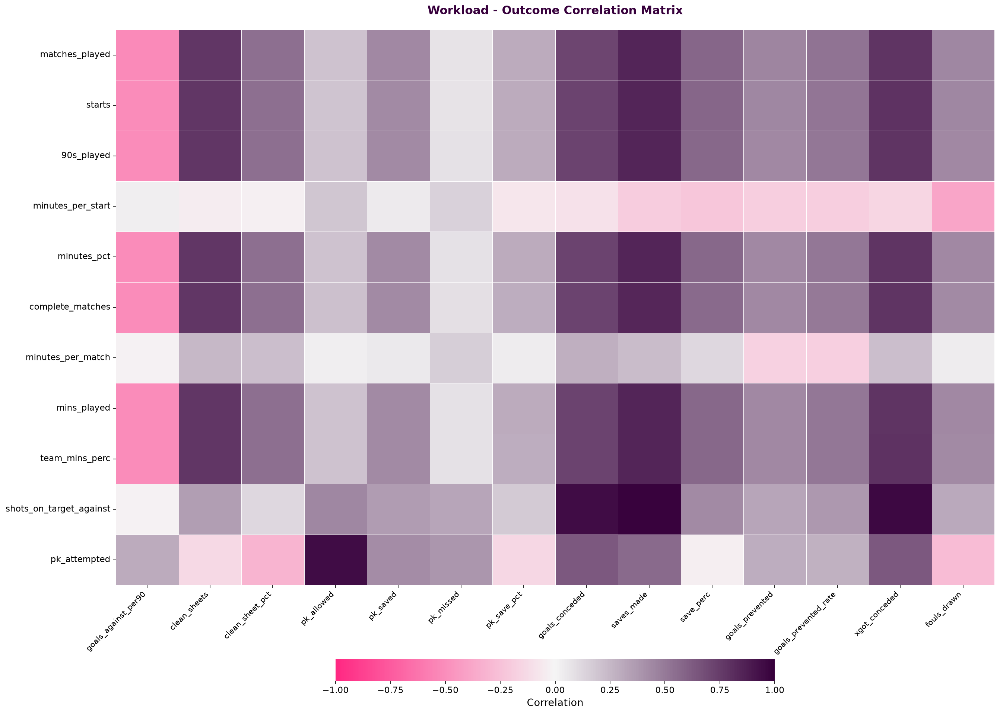

In [224]:
corr_heatmap_plot(workload_outcome_corr, title="Workload - Outcome Correlation Matrix")

In [174]:
workload_outcome_pairs = [
    ("shots_on_target_against", "goals_conceded"),
    ("shots_on_target_against", "saves_made"),
    ("shots_on_target_against", "xgot_conceded"),
    ("pk_attempted", "pk_allowed")
]

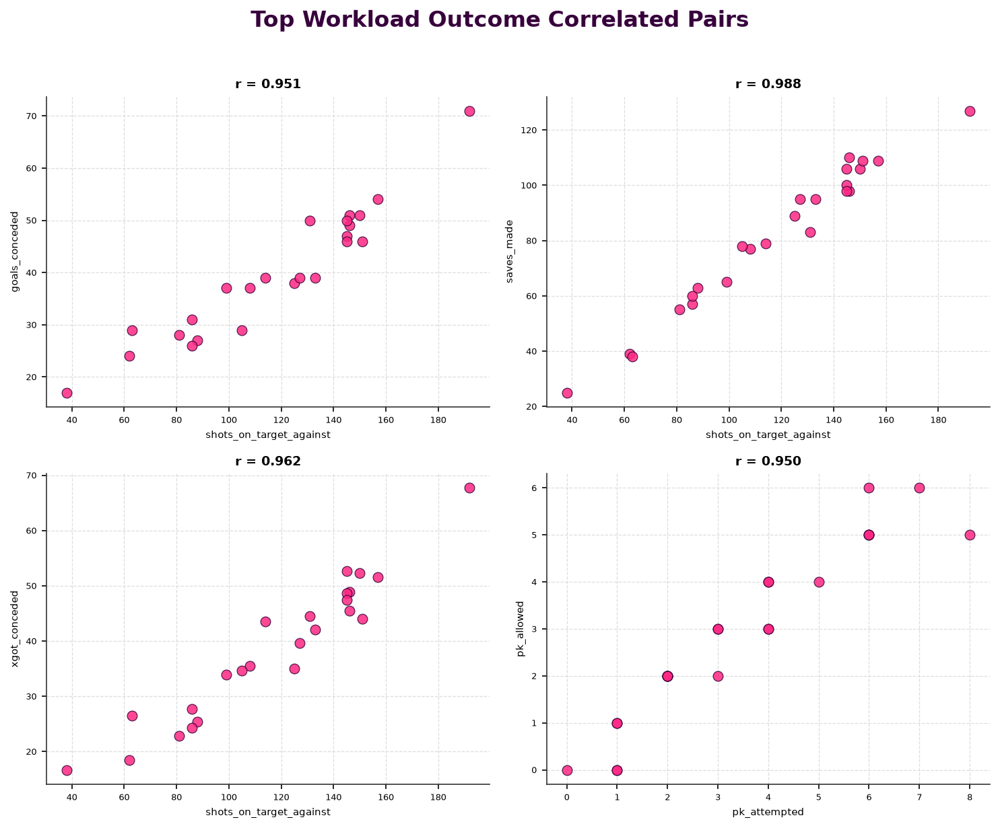

In [175]:
n_rows = 2
n_cols = 2

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(n_cols * 5, n_rows * 4)
)

axes = axes.flatten()

for i, (feat1, feat2) in enumerate(workload_outcome_pairs):
    corr = df[feat1].corr(df[feat2])
    x = df[feat1]
    y = df[feat2]
    ax = axes[i]

    ax.scatter(
        x,
        y,
        color=ACCENT,
        edgecolor=PRIMARY,
        linewidth=0.6,
        s=50,
        alpha=0.85,
        )
    
    ax.set_title(f"r = {corr:.3f}", fontsize=9, fontweight="bold")
    ax.set_xlabel(x.name, fontsize=7)
    ax.set_ylabel(y.name, fontsize=7)
    ax.tick_params(labelsize=6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    

plt.suptitle("Top Workload Outcome Correlated Pairs", fontsize=16, fontweight="bold", color=PRIMARY, y=1.02)

plt.tight_layout()
plt.show()

**Volume vs Efficiency**

Determine whether workload mainly increases how much a goalkeeper does (volume) or whether it also appears to affect how efficiently they perform.

Feature Definitions:

**Volume features** describes how much defensive workload a goalkeeper faced. 
**Efficiency features** capture the rate at which that workload was converted into a positive outcome

The goal of this section is to test whether efficiency metrics behave differently at low vs high workload, which has direct implications for how reliably these rates can be compared across goalkeepers with very different sample sizes.

In [176]:
workload_volume = [
    "shots_on_target_against",   # shot-facing exposure
    "pk_attempted",              # penalty-facing exposure
]

workload_efficiency = [
    "save_perc",              # % of shots on target saved
    "goals_prevented_rate",   # goals prevented relative to expected
    "pk_save_pct",            # % of penalties saved
    "clean_sheet_pct",        # % of matches with a clean sheet
    "goals_against_per90",    # inverse-direction efficiency (lower = better)
]

In [177]:
quadrant_pairs = [
    ("shots_on_target_against", "save_perc"),
    ("shots_on_target_against", "goals_prevented_rate"),
    ("shots_on_target_against", "goals_prevented"),
    ("pk_attempted", "pk_save_pct"),
]

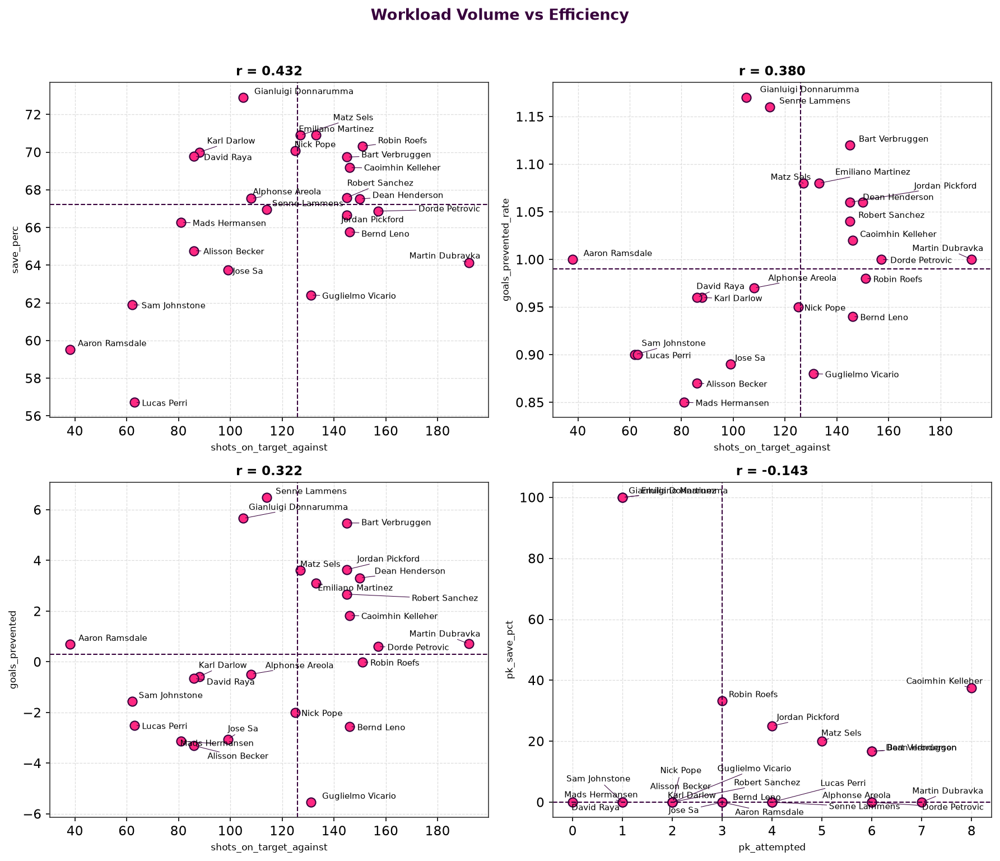

In [178]:
def quadrant_scatter_grid(df, pairs, n_cols=2):
    n_pairs = len(pairs)
    n_rows = int(np.ceil(n_pairs / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for i, (x_feat, y_feat) in enumerate(pairs):
        corr = df[x_feat].corr(df[y_feat])
        ax = axes[i]
        ax.scatter(df[x_feat], df[y_feat], color=ACCENT, edgecolor=PRIMARY, s=60)

        x_med, y_med = df[x_feat].median(), df[y_feat].median()
        ax.axvline(x_med, color=PRIMARY, linestyle="--", linewidth=1)
        ax.axhline(y_med, color=PRIMARY, linestyle="--", linewidth=1)

        texts = [ax.text(row[x_feat], row[y_feat], row["Player"], fontsize=7) for _, row in df.iterrows()]
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color=PRIMARY, lw=0.5))

        ax.set_xlabel(x_feat, fontsize=8)
        ax.set_ylabel(y_feat, fontsize=8)

        ax.set_title(
            f"r = {corr:.3f}",
            fontsize=11,
            fontweight="bold"
        )

    for j in range(n_pairs, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
    "Workload Volume vs Efficiency",
    fontsize=13, color=PRIMARY, fontweight="bold", y=1.02
    )
    plt.tight_layout()
    plt.show()

quadrant_scatter_grid(df, quadrant_pairs, n_cols=2)

##### Workload Analysis - Key Findings

**Volume and efficiency are only weakly correlated in this sample.**
Shot-facing volume (`shots_on_target_against`) showed weak-to-moderate correlation with 
both `save_perc` (r = 0.432) and `goals_prevented_rate` (r = 0.380). This means workload 
alone does not strongly predict how efficient a goalkeeper appears — facing more shots 
does not reliably make a keeper look better or worse on a rate basis.

**However, workload does not fully explain the variation in efficiency.** Several goalkeepers with relatively lower shot volumes recorded efficiency rates comparable to or higher than those facing substantially greater workloads. This highlights the potential for greater sampling variation when efficiency metrics are calculated from fewer opportunities. At the opposite extreme, Martin Dubravka faced the highest shot volume in the sample (~192) and recorded a below-median save percentage, while his goals-prevented rate remained around the sample median.

**Cross-metric consistency strengthens the finding.**
The same low-volume cluster (Karl Darlow, David Raya, Nick Pope) and the same 
high-volume/high-efficiency cluster (Bart Verbruggen, Caoimhin Kelleher, Robert Sanchez, 
Dean Henderson) appear in both the save% and goals_prevented_rate plots independently. 
A pattern repeating across two separately-calculated efficiency metrics is stronger 
evidence than either plot alone.

**Penalty save % is the least reliable metric in the workload set.**
Most goalkeepers in the sample faced fewer than 3 penalties, meaning `pk_save_pct` is 
frequently derived from 0 or 1 events (e.g. a single save producing a 100% rate). 
Correlation with `pk_attempted` was weak and arguably meaningless (r = -0.143) given how 
zero-inflated the underlying counts are. This metric carries substantially more sampling 
noise than `save_perc` or `goals_prevented_rate` and should not be treated with equal 
confidence.

**Implication for metric interpretation.**

Raw volume metrics such as `saves_made` and `goals_prevented` are strongly influenced by the amount of workload a goalkeeper receives. Efficiency metrics such as `save_perc` and `goals_prevented_rate` reduce this exposure effect, but can become unstable when calculated from a small number of opportunities. `pk_save_pct` is particularly susceptible to this issue because penalty attempts are relatively rare in the sample.

##### POTSI Implication - Separating Workload from Quality

The findings above indicate that efficiency rates should not be interpreted independently of the volume of work behind them. Two goalkeepers with identical `save_perc` do not provide equally precise evidence of performance if one faced 40 shots and the other faced 190, because the lower-volume rate is based on fewer opportunities and is therefore more sensitive to individual events.

**For the POTSI composite scoring framework, this suggests:**

1. **Apply a minimum exposure threshold before scoring efficiency metrics.** Goalkeepers below a defined `shots_on_target_against` or `pk_attempted` threshold should either be excluded from efficiency-based components or have those components down-weighted.

2. **Use volume and efficiency metrics for complementary purposes.** `goals_prevented` captures accumulated goal-prevention contribution and is naturally influenced by workload, whereas `goals_prevented_rate` provides an exposure-adjusted perspective. Neither should be interpreted in isolation.

3. **`pk_save_pct` should be heavily down-weighted or excluded from the composite score unless a minimum penalty-exposure threshold is applied.** The majority of the sample faced very few penalties, making this rate highly sensitive to individual events.

4. **High-workload, high-efficiency goalkeepers provide stronger observational evidence than equivalent efficiency rates based on very small workloads**, because their rates are supported by a larger number of defensive events. This does not establish superior goalkeeper quality by itself, but it provides greater confidence in the observed rate.

This distinction — workload as *context* for interpreting performance rather than performance itself — will be carried forward into Team-Context Analysis (Section 4.5), where the same reliability consideration applies to team-dependent metrics such as clean-sheet percentage.

#### 3.5 Team-context Analysis

**Objective:** Understand how much **team performance influences individual/player statistics**.

**Definitons:**

- **Team Context Variables** - These metrics describes the collective team-level results or provide contexual information about the defensive and competitive environment in which the goalkeeper played. 

- **Individual Performance Variables** - These metrics describe actions, outcomes, or effectiveness directly attributable to the goalkeeper's individual performance.

In [179]:
team_context_features = [
    "wins",
    "draws",
    "losses",
    "clean_sheets",
    "clean_sheet_pct",
    "points_per_match",
    "plus_minus",
    "plus_minus_per90",
    "plus_minus_net_per90",
]

individual_performance_features = [
    "goals_against_per90",
    "pk_allowed",
    "pk_saved",
    "pk_missed",
    "pk_save_pct",
    "yellow_cards",
    "red_cards",
    "fouls_drawn",
    "goals_conceded",
    "saves_made",
    "save_perc",
    "goals_prevented",
    "goals_prevented_rate",
    "xgot_conceded",
]

In [180]:
team_context_corr = (
    df[team_context_features + individual_performance_features]
    .corr()
    .loc[team_context_features, individual_performance_features]
)

In [181]:
# filtering out columns with missing values
team_context_corr = team_context_corr.loc[:, ~team_context_corr.isna().any()]

In [182]:
team_context_corr[team_context_corr.abs() > 0.75].dropna(how="all", axis=0).dropna(how="all", axis=1)

,goals_against_per90,goals_conceded
wins,-0.897145,NaN
losses,NaN,0.80153
clean_sheets,-0.840145,NaN
clean_sheet_pct,-0.826766,NaN
points_per_match,-0.911013,NaN
plus_minus,-0.883003,NaN
plus_minus_per90,-0.920274,NaN


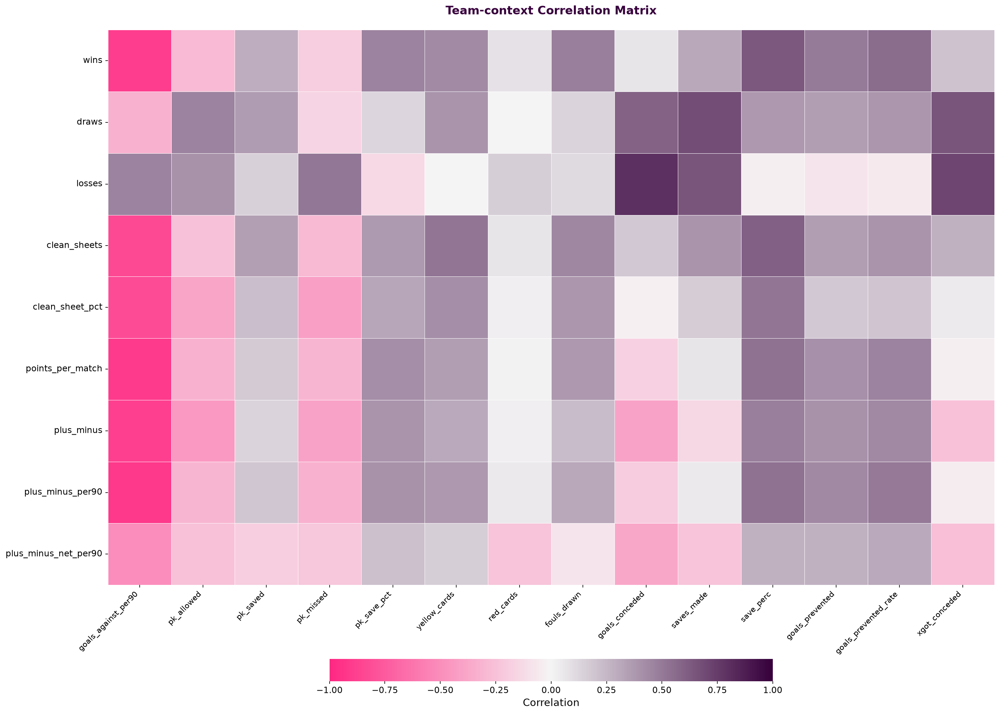

In [223]:
corr_heatmap_plot(
    team_context_corr,
    title="Team-context Correlation Matrix",
)

In [184]:
team_context_pairs = [
    ("save_perc", "points_per_match"),
    ("save_perc", "plus_minus_per90"),
    ("save_perc", "wins"),
    ("goals_prevented_rate", "points_per_match"),
    ("goals_prevented_rate", "plus_minus_per90"),
    ("goals_against_per90", "points_per_match"),
    ("goals_against_per90", "clean_sheet_pct"),
    ("clean_sheets", "yellow_cards"),
]

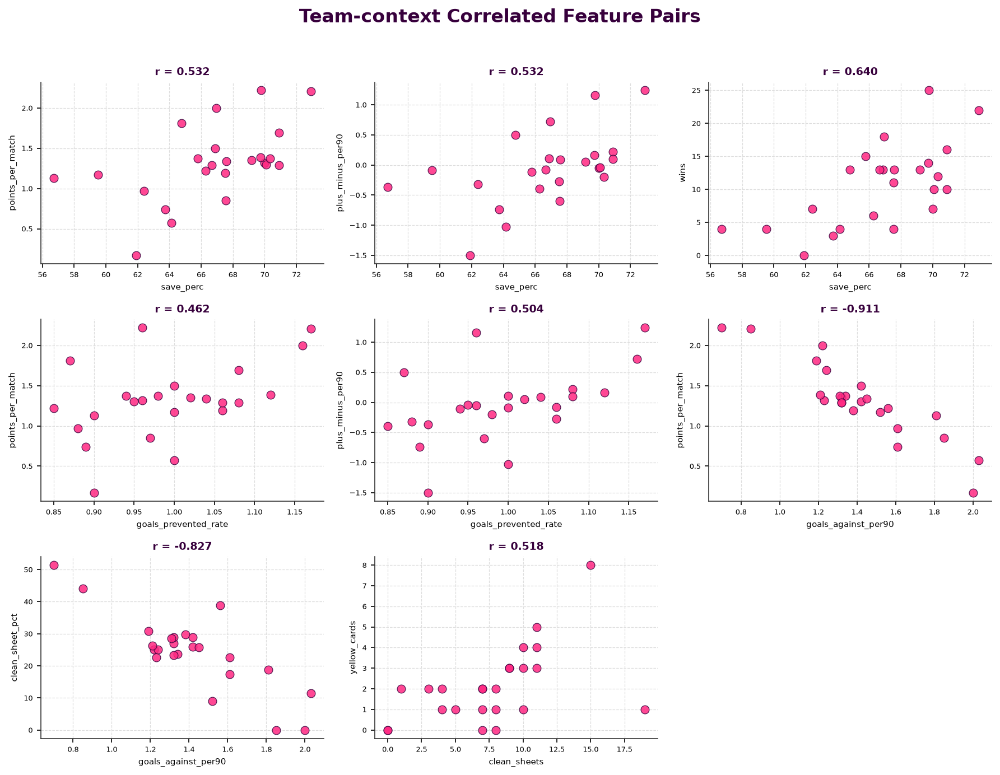

In [185]:
n_pairs = len(team_context_pairs)
n_cols = 3
n_rows = int(np.ceil(n_pairs / n_cols))

subplot_size_width = 4
subplot_size_height = 3

fig, axes = plt.subplots(
    n_rows, 
    n_cols,
    figsize=(subplot_size_width * n_cols, subplot_size_height * n_rows)
)

axes = axes.flatten()

for i, (x_feat, y_feat) in enumerate(team_context_pairs):
    r_val = df[x_feat].corr(df[y_feat])
    ax = axes[i]

    ax.scatter(
        df[x_feat],
        df[y_feat],
        color=ACCENT,
        edgecolor=PRIMARY,
        linewidth=0.6,
        s=50,
        alpha=0.85,
    )

    ax.set_title(f"r = {r_val:.3f}", fontsize=9, color=PRIMARY, fontweight="bold")
    ax.set_xlabel(x_feat, fontsize=7)
    ax.set_ylabel(y_feat, fontsize=7)
    ax.tick_params(labelsize=6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # hide any unused axes if n_pairs doesn't fill the grid
    for j in range(n_pairs, len(axes)):
        axes[j].set_visible(False)

fig.suptitle("Team-context Correlated Feature Pairs", fontsize=16, fontweight="bold", color=PRIMARY, y=1.02)
plt.tight_layout()
plt.show()

##### Team-dependent vs Individual-performance classification and summary

**Objective:** Distinguish team-dependent metrics from individual-performance metrics and assess the extent to which team context may influence goalkeeper evaluation.

---

**Team-dependent metrics**

| Metric | Why classified as team-context |
| ----------------------- | ------------------------------------------------------- |
| `wins` | Primarily reflects team match outcomes |
| `draws` | Team match outcome |
| `losses` | Team match outcome |
| `clean_sheets` | Strongly affected by overall team defensive performance |
| `clean_sheet_pct` | Team defensive outcome |
| `points_per_match` | Team result |
| `plus_minus` | Team performance while goalkeeper plays |
| `plus_minus_per90` | Team performance adjusted for playing time |
| `plus_minus_net_per90` | Team-level goal differential context |
| `goals_scored_on_pitch` | Team attacking output while goalkeeper plays |

**Individual-performance metrics**

| Metric | Performance type | Reliability / context |
| ---------------------- | --------------------- | ----------------------------- |
| `save_perc` | Individual efficiency | Some workload/team influence |
| `goals_prevented_rate` | Individual efficiency | Some workload/team influence |
| `goals_prevented` | Individual outcome | Volume-dependent |
| `saves_made` | Individual outcome | Strongly volume-dependent |
| `xgot_conceded` | Shot-stopping outcome | Context-sensitive |
| `pk_saved` | Individual outcome | Very small sample |
| `pk_save_pct` | Individual efficiency | Highly small-sample sensitive |

---

**Correlation screening**

A correlation matrix was calculated between the team-context and individual-performance metric groups to identify potential relationships between team environment and goalkeeper performance.

Relationships with very strong correlations (**|r| > 0.75**) were not taken forward to the scatterplot stage because these relationships were largely expected from the construction or mathematical relationship between the variables. Including them would provide limited additional analytical insight.

Instead, relationships showing **moderate associations (|r| ≥ 0.50)** were examined further using scatterplots. This provided a more useful set of relationships for investigating whether team context may influence how individual goalkeeper performance is observed.

The selected relationships were therefore treated as **exploratory relationships rather than evidence of causation**.

---

**Team-context and individual-performance relationships**

The following table summarizes the team-context and individual-performance metric pairs that showed moderate associations (**|r| ≥ 0.50**) and were selected for further visual investigation.

| Team context | Individual metric | r |
| ----------------------- | ---------------------- | --------: |
| `wins` | `save_perc` | **0.640** |
| `wins` | `goals_prevented_rate` | **0.557** |
| `draws` | `saves_made` | **0.680** |
| `losses` | `saves_made` | **0.653** |
| `goals_scored_on_pitch` | `goals_prevented_rate` | **0.617** |
| `clean_sheets` | `save_perc` | **0.602** |
| `points_per_match` | `save_perc` | **0.532** |

The results indicate that several goalkeeper performance metrics are not completely independent of team context. `save_perc`, `saves_made`, and `goals_prevented_rate` each show moderate relationships with at least one team-context variable.

This suggests that these metrics should be interpreted alongside team strength and match outcomes rather than being treated as completely isolated measures of goalkeeper quality.

However, correlation does not establish causation. The observed relationships may reflect a combination of team strength, match environment, defensive workload, and goalkeeper performance. Therefore, these results are interpreted as evidence of **potential team-context influence**, rather than proof that team performance directly causes changes in goalkeeper performance metrics.

---

**Key observations**

1. **Efficiency metrics are not completely independent of team context.**

   `save_perc` and `goals_prevented_rate` both show moderate associations with team-result and team-performance variables. Therefore, these metrics should not be interpreted as completely isolated measures of goalkeeper quality.

2. **Raw save volume is strongly connected to match context.**

   `saves_made` showed moderate associations with both `draws` (**r = 0.680**) and `losses` (**r = 0.653**). This suggests that save volume is partly determined by the type and defensive environment of matches experienced by the goalkeeper.

3. **Team attacking output also appears in goalkeeper performance relationships.**

   `goals_scored_on_pitch` showed a moderate relationship with `goals_prevented_rate` (**r = 0.617**), indicating that goalkeeper performance metrics can be associated with the team's overall performance while the goalkeeper is on the pitch.

4. **Clean-sheet outcomes have a meaningful relationship with goalkeeper efficiency.**

   `clean_sheets` and `save_perc` showed a moderate association (**r = 0.602**). This reinforces that clean-sheet outcomes should not be treated as purely individual goalkeeper achievements.

5. **The strongest relationships identified are contextual rather than purely individual.**

   The analysis suggests that goalkeeper evaluation should combine individual shot-stopping metrics with team-context information rather than relying heavily on outcome-based metrics alone.

---

##### POTSI implication

These findings provide an important consideration for the final POTSI scoring framework. Individual goalkeeper metrics should not automatically be treated as completely independent measures of goalkeeper quality.

Metrics such as `save_perc`, `goals_prevented_rate`, and `saves_made` may contain some degree of team-context influence. Meanwhile, metrics such as `clean_sheets`, `wins`, `points_per_match`, and `plus_minus` are inherently more dependent on the team's performance.

Therefore, the final POTSI model should distinguish between:

- **Individual shot-stopping performance**
- **Workload and exposure**
- **Team-dependent outcomes**

This reduces the risk of rewarding goalkeepers simply because they played in stronger teams or experienced more favourable team environments.

The team-context analysis will therefore be used as a **contextual adjustment rather than as a replacement for individual performance metrics** in the final POTSI framework.

### 4. Goalkeeper Performance Analysis

#### 4.1 Shot stopping

**Question:** How good is each goalkeeper at stopping shots?
  
- Analyse `save_perc`
- Analyse `goals_prevented`
- Analyse `goals_prevented_rate`
- Analyse workload vs efficiency
- Identify notable goalkeepers
- End with key findings


In [186]:
def plot_ranked_bar(
    df,
    metric_col,
    label_col="Player",
    n_highlight=5,
    higher_is_better=True,
    center_metric="median",
    use_buffer=True,  
    title=None,
    xlabel=None,
    figsize=(12, 8),
):

    plot_df = df.sort_values(metric_col, ascending=False).reset_index(drop=True)
    n = len(plot_df)

    if center_metric == "mean":
        center_val = plot_df[metric_col].mean()
        center_label = "Mean"
    elif center_metric == "median":
        center_val = plot_df[metric_col].median()
        center_label = "Median"
    else:
        raise ValueError("center_metric must be 'median' or 'mean'")

    colors = []
    for i in range(n):
        if i < n_highlight:
            colors.append(HIGHLIGHT_HIGH if higher_is_better else HIGHLIGHT_LOW)
        elif i >= n - n_highlight:
            colors.append(HIGHLIGHT_LOW if higher_is_better else HIGHLIGHT_HIGH)
        else:
            colors.append(NEUTRAL)

    fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(
        data=plot_df,
        x=metric_col,
        y=label_col,
        hue=label_col,
        palette=colors,
        legend=False,
    )

    for container in ax.containers:
        ax.bar_label(container, padding=4, fmt="%.1f")

    ax.axvline(x=center_val, color=PRIMARY, linestyle="--")

    x_min, x_max = plot_df[metric_col].min(), plot_df[metric_col].max()

    if use_buffer:
        buffer = (x_max - x_min) * 0.15
        ax.set_xlim(x_min - buffer, x_max + buffer * 1.5)
        label_x = center_val + buffer * 0.1
    else:
        buffer = (x_max - x_min) * 0.15  
        ax.set_xlim(0, x_max + buffer * 1.5)
        label_x = center_val + buffer * 0.1

    ax.text(
        label_x, n - 1,
        f"{center_label}: {center_val:.1f}",
        color=PRIMARY, fontsize=10, va="center"
    )

    style_plot(
        ax=ax,
        title=title or f"{metric_col} Across Goalkeepers",
        xlabel=xlabel or metric_col,
        ylabel="",
    )

    plt.tight_layout()
    plt.show()

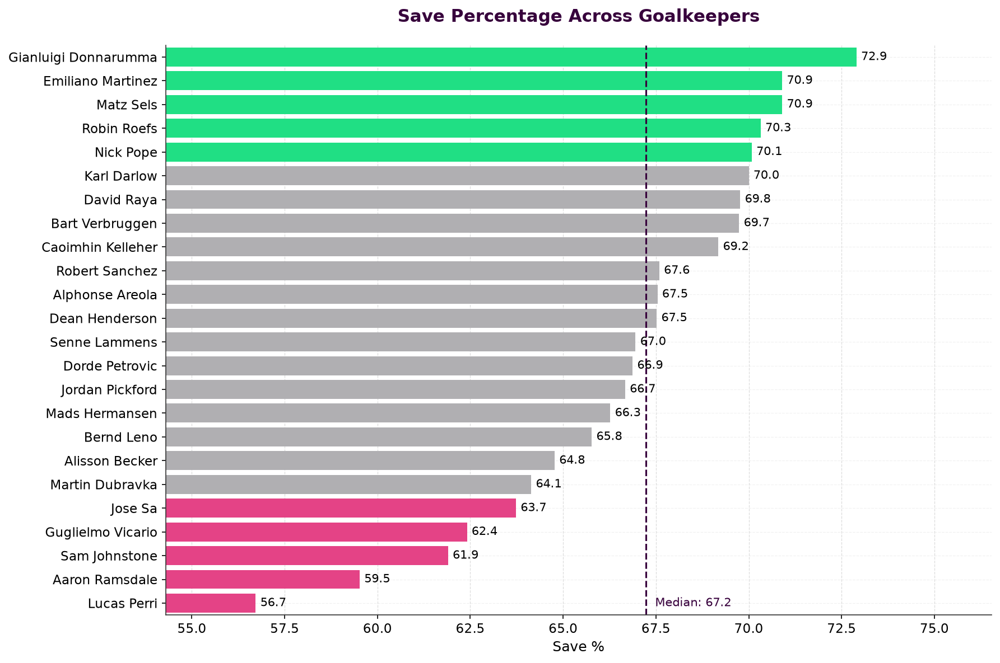

In [187]:
save_perc_df = df[["Player", "save_perc"]].sort_values(by="save_perc", ascending=False)

plot_ranked_bar(
    save_perc_df, 
    metric_col="save_perc", 
    title="Save Percentage Across Goalkeepers", 
    xlabel="Save %"
    )

In [188]:
goals_prevented_df = df[["Player", "goals_prevented"]].sort_values(by="goals_prevented", ascending=False)

In [189]:
goals_prevented_df.describe()

,goals_prevented
count,24.000000
mean,0.515417
std,3.214202
min,-5.540000
25%,-2.127500
50%,0.295000
75%,3.152500
max,6.490000


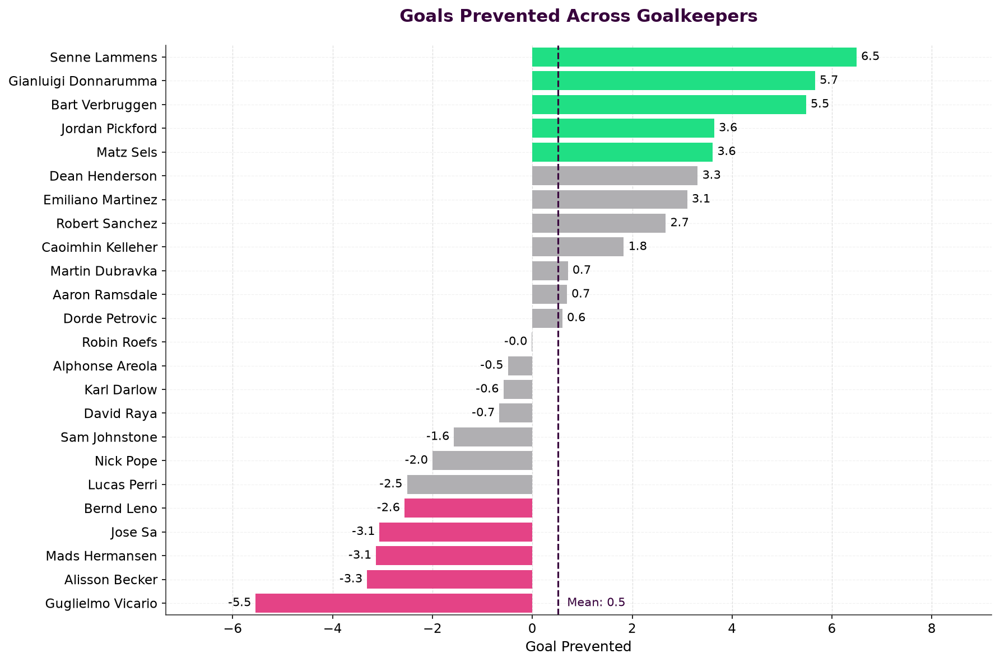

In [190]:
plot_ranked_bar(
    goals_prevented_df,
    metric_col="goals_prevented",
    title="Goals Prevented Across Goalkeepers",
    xlabel="Goal Prevented",
    center_metric="mean",
)

In [191]:
goals_prevented_df = df[["Player", "goals_prevented_rate"]].sort_values(by="goals_prevented_rate", ascending=False)

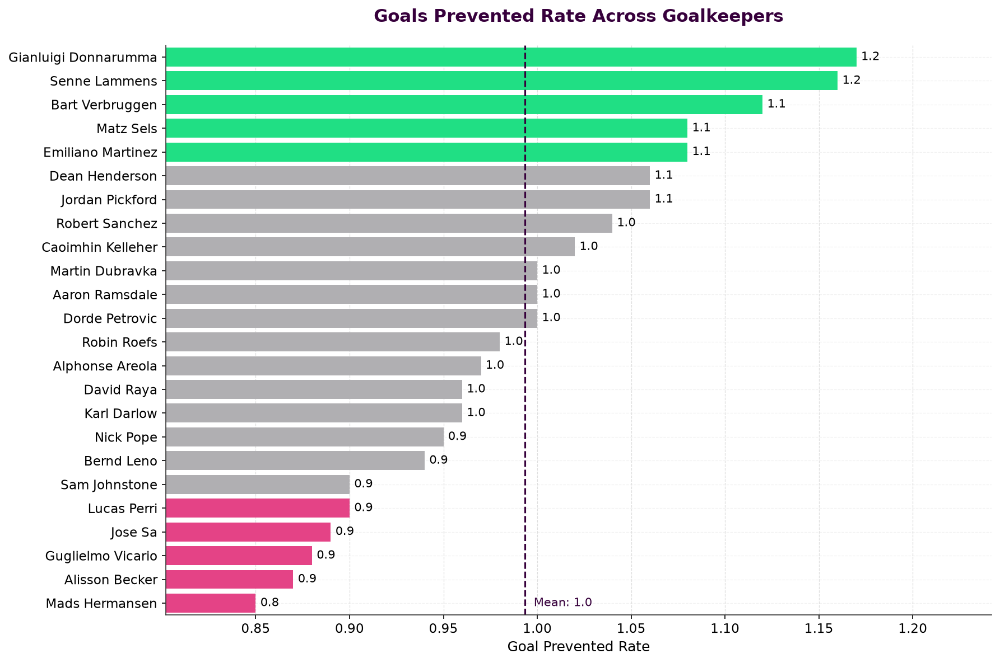

In [192]:
plot_ranked_bar(
    goals_prevented_df,
    metric_col="goals_prevented_rate",
    title="Goals Prevented Rate Across Goalkeepers",
    xlabel="Goal Prevented Rate",
    center_metric="mean",
)

**Workload vs Efficiency**

The exposure analysis showed that goalkeeper workload has a limited relationship with efficiency metrics. 
Therefore, save percentage and goals prevented rate should be interpreted alongside the volume of shots faced.
High efficiency at low exposure may be less reliable than a similar efficiency achieved under a larger workload.

**Notable Goalkeepers**

- **Gianluigi Donnarumma** stands out across the efficiency metrics and also records a strongly positive goals-prevented value.
- **Bart Verbruggen** combines strong efficiency with a substantial positive goals-prevented contribution.
- Some goalkeepers rank highly on efficiency but have lower workload, making their rates less reliable.
- Differences between raw and rate-based metrics demonstrate why goalkeeper performance should not be evaluated using a single metric.
- **David Raya provides an important reference point for the analysis.** As the only goalkeeper included among the Player of the Season nominees, his performance provides a useful comparison against the statistical leaders in the shot-stopping metrics. Raya does not rank among the very highest goalkeepers in every shot-stopping measure, highlighting that Player of the Season recognition cannot be explained by a single goalkeeper statistic.

##### Key Findings

1. Save efficiency varies considerably across the goalkeeper sample.

2. Goals prevented provides a different perspective from save percentage by capturing absolute shot-stopping contribution.

3. Goals prevented rate provides a volume-adjusted view of shot-stopping quality, helping distinguish efficiency from raw workload.

4. Workload must be considered when interpreting goalkeeper efficiency, as low-exposure performances can produce unstable rates.

5. Consistent performance across multiple metrics provides stronger evidence of goalkeeper quality than performance on a single metric.

**POTSI Implication**

The shot-stopping analysis suggests that POTSI should combine efficiency metrics with
workload-adjusted measures rather than relying on a single goalkeeper statistic.

#### 4.2 Defensive outcomes

**Question:** How effective are goalkeepers in producing defensive outcomes?

- Analyse `clean_sheets`
- Analyse `clean_sheet_pct`
- Analyse `goals_against_per90`
- Analyse penalty outcomes
- Consider reliability/sample-size issues
- Key findings

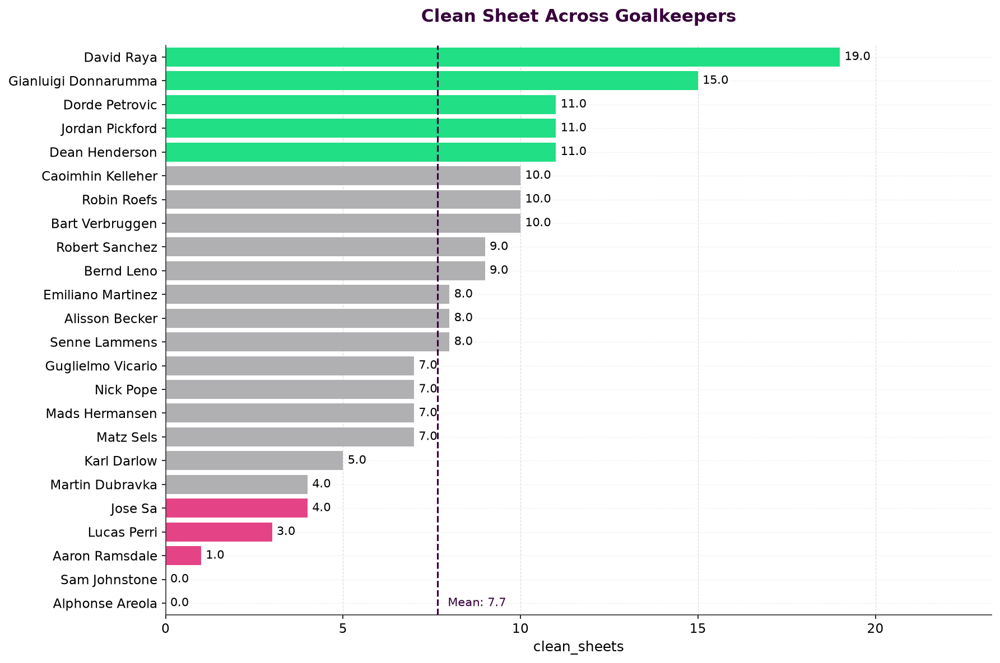

In [193]:
clean_sheet_df = df[["Player", "clean_sheets"]].sort_values(by="clean_sheets")


plot_ranked_bar(
    clean_sheet_df,
    metric_col="clean_sheets",
    center_metric="mean",
    higher_is_better=True,
    title="Clean Sheet Across Goalkeepers",
    use_buffer=False
)

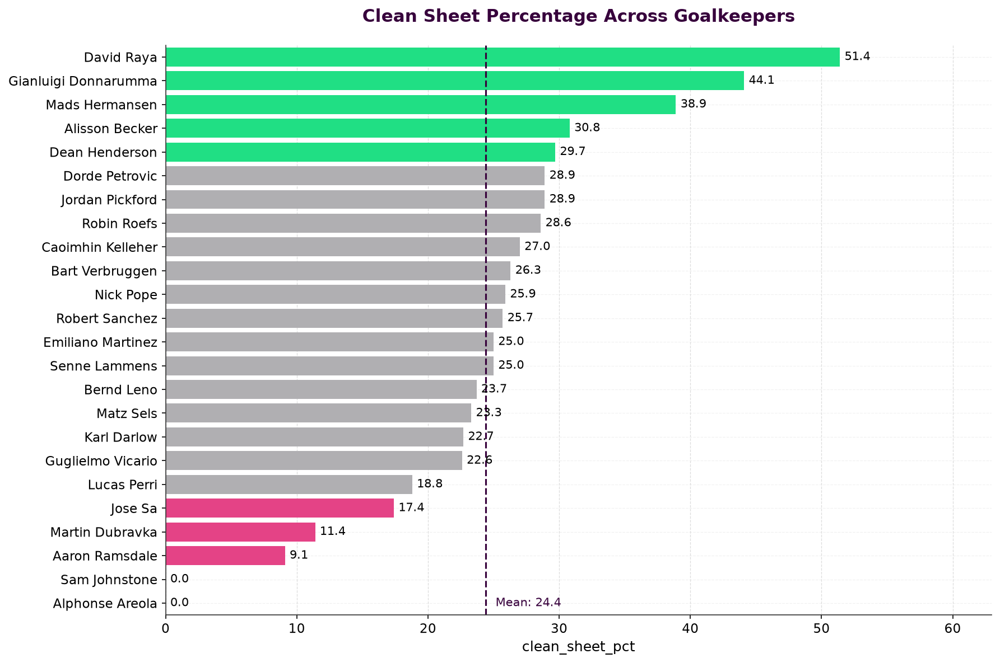

In [194]:
clean_sheet_perc_df = df[["Player", "clean_sheet_pct"]].sort_values(by="clean_sheet_pct")


plot_ranked_bar(
    clean_sheet_perc_df,
    metric_col="clean_sheet_pct",
    center_metric="mean",
    title="Clean Sheet Percentage Across Goalkeepers",
    use_buffer=False
)

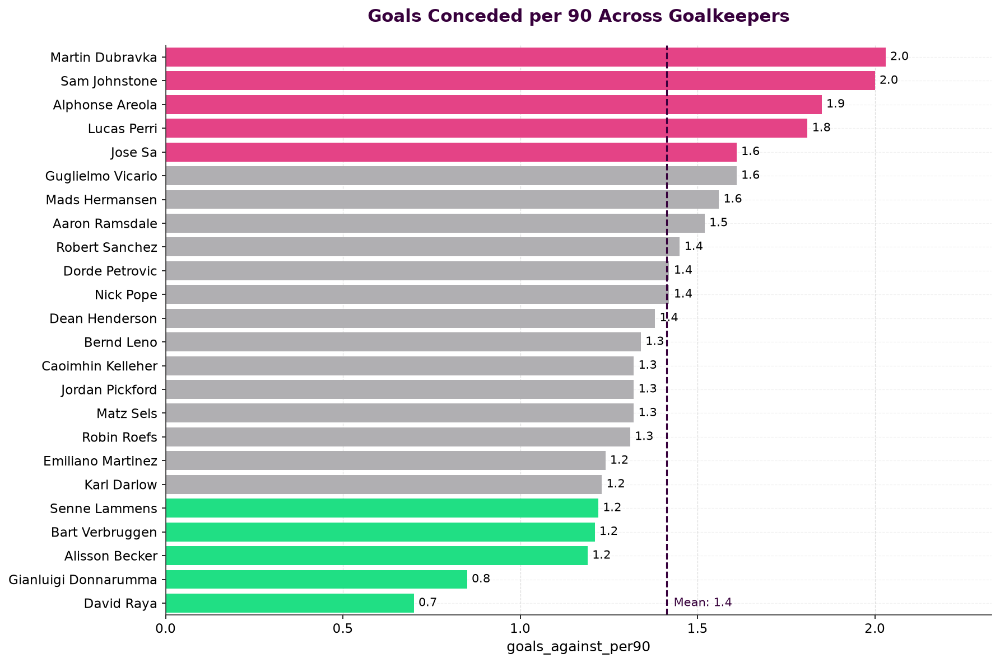

In [195]:
goals_against_df = df[["Player", "goals_against_per90"]].sort_values(by="goals_against_per90")


plot_ranked_bar(
    goals_against_df,
    metric_col="goals_against_per90",
    center_metric="mean",
    higher_is_better=False,
    title="Goals Conceded per 90 Across Goalkeepers",
    use_buffer=False
)

##### Key Findings

-  **Clean Sheets**

    David Raya recorded the highest number of clean sheets in the sample, followed by
    Gianluigi Donnarumma. However, clean sheets represent a team-level defensive outcome
    as much as an individual goalkeeper achievement.

    Because the metric is a raw count, it is also influenced by playing time and the
    defensive strength of the team. Therefore, a high number of clean sheets should not
    be interpreted as direct evidence of superior individual shot-stopping ability.

    The contrast between the clean-sheet rankings and the shot-stopping metrics also
    highlights why POTSI should separate team-dependent outcomes from individual
    goalkeeper performance.

- **Clean Sheet Count vs Rate**

    The raw clean-sheet count favours goalkeepers with greater playing time, while
    `clean_sheet_pct` provides an exposure-adjusted view of clean-sheet frequency.

    The difference between the two rankings demonstrates why raw defensive outcomes should
    not be interpreted independently of playing time. For POTSI, clean-sheet percentage
    provides a more comparable measure of defensive outcome, while the raw count can
    provide additional evidence of sustained contribution over a larger sample.

- **Goals Against per 90**

    `goals_against_per90` provides a playing-time-adjusted measure of goals conceded,
    making it more suitable for comparing goalkeepers than the raw goals-conceded count.

    David Raya recorded the lowest rate in the sample at **0.7 goals per 90**, followed by
    Gianluigi Donnarumma at **0.8**. At the opposite end, Martin Dubravka and Sam Johnstone
    recorded **2.0 goals per 90**.

    However, goals conceded are influenced by the defensive environment around the
    goalkeeper and the quality and volume of chances faced. Therefore, a low
    `goals_against_per90` should be interpreted as a strong defensive outcome rather than
    direct evidence of individual goalkeeper quality.

### 5. POTSI Model Development

##### 5.1 Final Feature Evaluation & Selection

In [196]:
feature_inventory = pd.DataFrame({
    "feature": df.columns,
    "category": None,
    "reliability_note": None,
    "decision": None,
})

In [197]:
feature_inventory.loc[feature_inventory["feature"] == "Player", "category"] = "Identifier"
feature_inventory.loc[feature_inventory["feature"] == "Player", "reliability_note"] = "NA"
feature_inventory.loc[feature_inventory["feature"] == "Player", "decision"] = "	Retain (not scored)"

In [198]:
feature_inventory

,feature,category,reliability_note,decision
0,Player,Identifier,NA,\tRetain (not scored)
1,matches_played,None,None,None
2,starts,None,None,None
3,90s_played,None,None,None
4,goals_against_per90,None,None,None
5,shots_on_target_against,None,None,None
6,wins,None,None,None
7,draws,None,None,None
8,losses,None,None,None
9,clean_sheets,None,None,None


In [199]:
df.columns

Index(['Player', 'matches_played', 'starts', '90s_played',
       'goals_against_per90', 'shots_on_target_against', 'wins', 'draws',
       'losses', 'clean_sheets', 'clean_sheet_pct', 'pk_attempted',
       'pk_allowed', 'pk_saved', 'pk_missed', 'pk_save_pct', 'yellow_cards',
       'red_cards', 'fouls_drawn', 'points_per_match', 'plus_minus_per90',
       'minutes_per_start', 'plus_minus', 'minutes_pct', 'complete_matches',
       'plus_minus_net_per90', 'minutes_per_match', 'mins_played',
       'team_mins_perc', 'goals_conceded', 'saves_made', 'save_perc',
       'goals_prevented', 'goals_prevented_rate', 'xgot_conceded'],
      dtype='str')

In [200]:
availability = [
    "matches_played",
    "starts",
    "90s_played",
    "minutes_per_start",
    "minutes_pct",
    "complete_matches",
    "minutes_per_match",
    "mins_played",
    "team_mins_perc"
]

penalty = [
    "pk_attempted",
    "pk_allowed",
    "pk_saved",
    "pk_missed",
    "pk_save_pct",
]

workload = [
    "goals_against_per90",
    "shots_on_target_against",
    "saves_made",
    "xgot_conceded"
]

shot_stopping = [
    "save_perc",
    "goals_prevented",
    "goals_prevented_rate",
]

team_context = [
    "wins",
    "draws",
    "losses",
    "clean_sheets",
    "clean_sheet_pct",
    "points_per_match",
    "plus_minus_per90",
    "plus_minus_net_per90",
    "plus_minus",
    "goals_conceded"
]

discipline = [
    "yellow_cards",
    "red_cards"
]

distribution_and_involvement = [
    "fouls_drawn"
]

In [201]:
def assign_categories(col):
    if col in availability:
        return "Availability"
    elif col in penalty:
        return "Penalty"
    elif col in workload:
        return "Workload"
    elif col in shot_stopping:
        return "Shot Stopping"
    elif col in team_context:
        return "Team Context"
    elif col in discipline:
        return "Discipline"
    else:
        return "NA"

feature_inventory["category"] = feature_inventory["feature"].apply(assign_categories)
feature_inventory

,feature,category,reliability_note,decision
0,Player,NA,NA,\tRetain (not scored)
1,matches_played,Availability,None,None
2,starts,Availability,None,None
3,90s_played,Availability,None,None
4,goals_against_per90,Workload,None,None
5,shots_on_target_against,Workload,None,None
6,wins,Team Context,None,None
7,draws,Team Context,None,None
8,losses,Team Context,None,None
9,clean_sheets,Team Context,None,None


In [207]:
df[availability]

,matches_played,starts,90s_played,minutes_per_start,minutes_pct,complete_matches,minutes_per_match,mins_played,team_mins_perc
0,26,26.0,26.0,90.0,68.4,26.0,90.0,2340,68
1,20,20.0,20.0,90.0,52.6,20.0,90.0,1800,53
7,22,22.0,22.0,90.0,57.9,22.0,90.0,1980,58
8,34,34.0,34.0,90.0,89.5,34.0,90.0,3060,89
9,35,35.0,35.0,90.0,92.1,35.0,90.0,3150,92
11,37,37.0,37.0,90.0,97.4,37.0,90.0,3330,97
12,18,18.0,18.0,90.0,47.4,18.0,90.0,1620,47
14,12,12.0,12.0,90.0,31.6,12.0,90.0,1080,32
16,37,37.0,37.0,90.0,97.4,37.0,90.0,3330,97
18,32,32.0,32.0,90.0,84.2,32.0,90.0,2880,84


In [209]:
availability_corr = df[availability].corr()

In [219]:
availability_corr

,matches_played,starts,90s_played,minutes_per_start,minutes_pct,complete_matches,minutes_per_match,mins_played,team_mins_perc
matches_played,1.000000,0.999518,0.998953,-0.141410,0.998959,0.997413,0.263467,0.998951,0.998881
starts,0.999518,1.000000,0.999518,-0.136379,0.999516,0.998306,0.289505,0.999525,0.999536
90s_played,0.998953,0.999518,1.000000,-0.106265,0.999999,0.999544,0.302442,0.999998,0.999911
minutes_per_start,-0.141410,-0.136379,-0.106265,1.000000,-0.106234,-0.079693,0.474105,-0.106584,-0.109500
minutes_pct,0.998959,0.999516,0.999999,-0.106234,1.000000,0.999531,0.302561,0.999999,0.999914
complete_matches,0.997413,0.998306,0.999544,-0.079693,0.999531,1.000000,0.320246,0.999518,0.999336
minutes_per_match,0.263467,0.289505,0.302442,0.474105,0.302561,0.320246,1.000000,0.302925,0.304630
mins_played,0.998951,0.999525,0.999998,-0.106584,0.999999,0.999518,0.302925,1.000000,0.999923
team_mins_perc,0.998881,0.999536,0.999911,-0.109500,0.999914,0.999336,0.304630,0.999923,1.000000


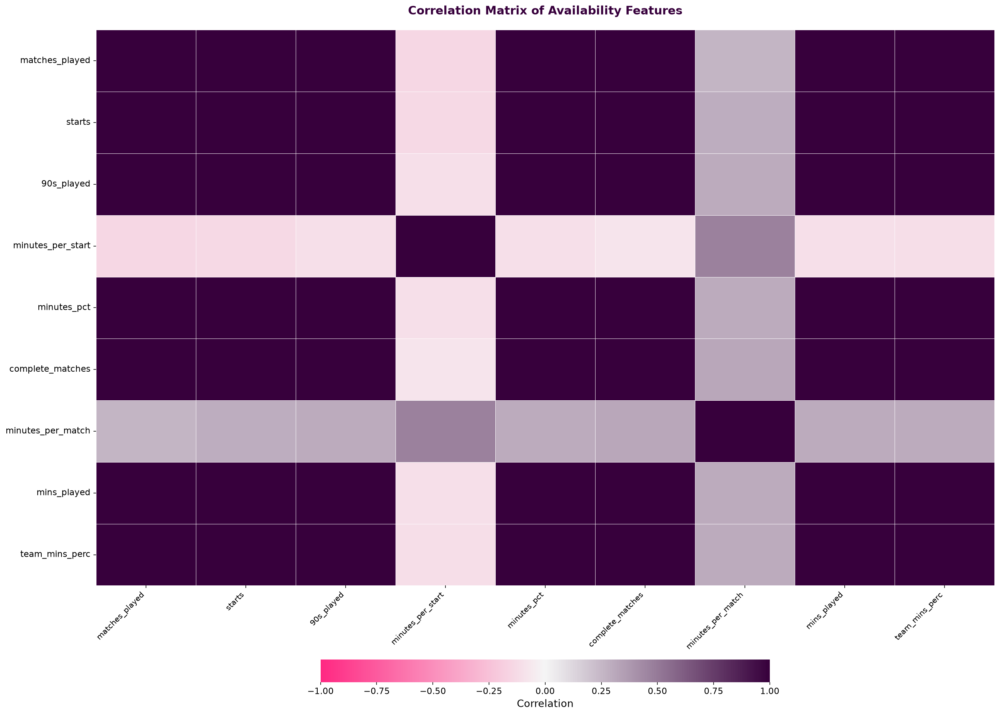

In [222]:
corr_heatmap_plot(
    corr_df=availability_corr,
    title="Correlation Matrix of Availability Features",
)

5. POTSI Model Development

│

├── 5.3 Metric Transformation & Normalization

├── 5.4 Reliability & Minimum Exposure Treatment

├── 5.5 POTSI Dimension Design

├── 5.6 Weighting Methodology

├── 5.7 POTSI Score Calculation

└── 5.8 Validation & Sensitivity Analysis


**Notebook Structure**

```text
Relationship Analysis
        ↓
Feature understanding
        ↓
Exposure / Workload / Team-context findings
        ↓
Goalkeeper Performance Analysis
        ↓
POTSI feature selection
```